# Proyecto Integrador M4 — Machine Learning

## Avance 3: Aprendizaje No Supervisado

### Predicción de fuga de clientes en el sector financiero

**Empresa:** FinanceGuard  
**Rol:** Analista de segmentación y exploración no supervisada

### Contexto del proyecto

FinanceGuard es un banco digital que ha experimentado un crecimiento significativo y cuenta actualmente con una base de 10.000 clientes.

Sin embargo, la organización enfrenta una tasa anual de abandono cercana al 20%, lo que genera pérdidas económicas y plantea la necesidad de comprender con mayor profundidad el comportamiento y las características de sus clientes.

En los avances anteriores se desarrollaron modelos supervisados orientados a predecir la probabilidad de abandono. En este tercer avance, el análisis se complementará mediante técnicas de aprendizaje no supervisado.

El objetivo será descubrir estructuras y patrones ocultos dentro de la base de clientes, identificar segmentos con características diferenciadas y analizar posteriormente cómo se relaciona cada grupo con la tasa de churn.

### Rol en el Avance

En este avance se asume el rol de **analista de segmentación y exploración no supervisada**.

La responsabilidad consiste en aplicar técnicas de clustering y reducción de dimensionalidad para:

- Identificar grupos naturales de clientes.
- Analizar las características demográficas, financieras y de comportamiento de cada segmento.
- Evaluar la relación entre los segmentos identificados y la tasa de abandono.
- Generar información útil para el diseño de estrategias de retención diferenciadas.
- Crear nuevas variables derivadas de la segmentación que puedan utilizarse en futuros modelos predictivos.

### Objetivo

Aplicar técnicas de aprendizaje no supervisado para segmentar la base de clientes de FinanceGuard, descubrir patrones de comportamiento y analizar la relación entre los segmentos identificados y el churn.

#### 2. Configuración del Entorno y Carga de Datos

En este bloque se importan las librerías necesarias para realizar el análisis de aprendizaje no supervisado.

Se utilizarán herramientas para:

- Manipulación y análisis de datos.
- Visualización.
- Preprocesamiento y escalamiento.
- Clustering mediante K-Means y DBSCAN.
- Evaluación de la calidad de los clusters.
- Reducción de dimensionalidad mediante PCA.
- Visualización no lineal mediante t-SNE.

También se define una semilla aleatoria para favorecer la reproducibilidad de los resultados y se carga el dataset original de clientes de FinanceGuard.

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Manejo de rutas
from pathlib import Path

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Algoritmos de clustering
from sklearn.cluster import KMeans, DBSCAN

# Métricas de evaluación no supervisada
from sklearn.metrics import silhouette_score

# Reducción de dimensionalidad
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Herramienta auxiliar para DBSCAN
from sklearn.neighbors import NearestNeighbors

# Visualización de objetos dentro del notebook
from IPython.display import display

In [2]:
# Semilla para reproducibilidad
RANDOM_STATE = 42

# Configuración para visualizar todas las columnas
pd.set_option("display.max_columns", None)

# Configuración general de gráficos
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

print("Configuración completada correctamente.")

Configuración completada correctamente.


##### 2.1 Carga del dataset

El archivo utilizado contiene información demográfica, financiera y de comportamiento correspondiente a 10.000 clientes de FinanceGuard.

El dataset se encuentra almacenado en la misma carpeta que el notebook bajo el nombre:

`Churn_Modelling.csv`

Antes de realizar el análisis, se verificará que el archivo exista y pueda cargarse correctamente.

In [3]:
# Ruta relativa del dataset
ruta_datos = Path("Churn_Modelling.csv")

# Validación de existencia del archivo
if not ruta_datos.exists():
    raise FileNotFoundError(
        "No se encontró el archivo 'Churn_Modelling.csv'. "
        "Verificá que se encuentre en la misma carpeta que el notebook."
    )

# Carga del dataset
df = pd.read_csv(ruta_datos)

print("Dataset cargado correctamente.")
print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

Dataset cargado correctamente.
Cantidad de filas: 10000
Cantidad de columnas: 14


In [4]:
# Visualización de los primeros registros
display(df.head())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


#### 3. Validación Inicial y Control de Consistencia

El análisis exploratorio completo del dataset fue realizado durante el Avance 1.

Por lo tanto, en este notebook se realizará únicamente una validación resumida de la estructura y calidad de los datos, con el objetivo de confirmar que el archivo conserva las características esperadas antes de iniciar el análisis no supervisado.

Se verificarán:

- Dimensiones del dataset.
- Nombres y tipos de las variables.
- Presencia de valores faltantes.
- Existencia de registros duplicados.
- Distribución general de la variable `Exited`.

La variable `Exited` será analizada únicamente con fines descriptivos y será excluida posteriormente de la construcción de los clusters.

In [5]:
# Dimensiones generales del dataset
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de variables: {df.shape[1]}")

# Lista de columnas
print("\nColumnas disponibles:")

for numero, columna in enumerate(df.columns, start=1):
    print(f"{numero}. {columna}")

Cantidad de registros: 10000
Cantidad de variables: 14

Columnas disponibles:
1. RowNumber
2. CustomerId
3. Surname
4. CreditScore
5. Geography
6. Gender
7. Age
8. Tenure
9. Balance
10. NumOfProducts
11. HasCrCard
12. IsActiveMember
13. EstimatedSalary
14. Exited


In [6]:
# Columnas esperadas según el dataset original
columnas_esperadas = [
    "RowNumber",
    "CustomerId",
    "Surname",
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

# Identificación de posibles diferencias
columnas_faltantes = [
    columna
    for columna in columnas_esperadas
    if columna not in df.columns
]

columnas_adicionales = [
    columna
    for columna in df.columns
    if columna not in columnas_esperadas
]

# Resultados
if not columnas_faltantes and not columnas_adicionales:
    print("La estructura de columnas coincide con el dataset original.")
else:
    print("Se detectaron diferencias en la estructura.")

    print("\nColumnas faltantes:")
    print(columnas_faltantes)

    print("\nColumnas adicionales:")
    print(columnas_adicionales)

La estructura de columnas coincide con el dataset original.


In [7]:
# Revisión de los tipos de datos
tabla_tipos = (
    df.dtypes
    .astype(str)
    .reset_index()
)

tabla_tipos.columns = [
    "Variable",
    "Tipo de dato"
]

display(tabla_tipos)

,Variable,Tipo de dato
0,RowNumber,int64
1,CustomerId,int64
2,Surname,object
3,CreditScore,int64
4,Geography,object
5,Gender,object
6,Age,int64
7,Tenure,int64
8,Balance,float64
9,NumOfProducts,int64


##### 3.1 Revisión resumida de la calidad de los datos

A continuación, se construirá una tabla que resume:

- Tipo de dato.
- Cantidad de valores faltantes.
- Porcentaje de valores faltantes.
- Cantidad de valores únicos.

Esta revisión permite validar que el dataset conserva la calidad observada durante el Avance 1.

In [8]:
# Tabla resumida de calidad de los datos
tabla_calidad = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores faltantes": df.isna().sum(),
    "Porcentaje faltante": (
        df.isna().mean() * 100
    ).round(2),
    "Valores únicos": df.nunique()
})

tabla_calidad.index.name = "Variable"

display(tabla_calidad)

,Tipo de dato,Valores faltantes,Porcentaje faltante,Valores únicos
Variable,,,,
RowNumber,int64,0,0.0,10000
CustomerId,int64,0,0.0,10000
Surname,object,0,0.0,2932
CreditScore,int64,0,0.0,460
Geography,object,0,0.0,3
Gender,object,0,0.0,2
Age,int64,0,0.0,70
Tenure,int64,0,0.0,11
Balance,float64,0,0.0,6382


In [9]:
#-------------------------------------------------------------
# Comprobación general de valores faltantes y duplicados
#-------------------------------------------------------------

# Cantidad total de valores faltantes
total_faltantes = df.isna().sum().sum()

# Cantidad de filas completamente duplicadas
total_duplicados = df.duplicated().sum()

print("Control general de calidad")
print("-" * 30)

print(
    f"Valores faltantes totales: "
    f"{total_faltantes}"
)

print(
    f"Registros duplicados: "
    f"{total_duplicados}"
)

# Mensaje de validación
if total_faltantes == 0 and total_duplicados == 0:
    print(
        "\nEl dataset no presenta valores faltantes "
        "ni registros duplicados."
    )
else:
    print(
        "\nSe detectaron aspectos que requieren revisión."
    )

Control general de calidad
------------------------------
Valores faltantes totales: 0
Registros duplicados: 0

El dataset no presenta valores faltantes ni registros duplicados.


##### 3.2 Distribución general de la variable `Exited

La variable `Exited` indica si un cliente abandonó el banco:

- `0`: cliente activo.
- `1`: cliente que abandonó la entidad.

Esta variable no participará en la construcción de los clusters.

Su distribución se analiza únicamente para conservar una referencia general sobre la tasa de churn y facilitar la comparación posterior con las tasas observadas dentro de cada segmento.

In [10]:
# Frecuencias absolutas
frecuencia_churn = (
    df["Exited"]
    .value_counts()
    .sort_index()
)

# Frecuencias porcentuales
porcentaje_churn = (
    df["Exited"]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .mul(100)
    .round(2)
)

# Tabla resumen
tabla_churn = pd.DataFrame({
    "Cantidad de clientes": frecuencia_churn,
    "Porcentaje": porcentaje_churn
})

tabla_churn.index = [
    "Cliente activo",
    "Cliente que abandonó"
]

display(tabla_churn)

,Cantidad de clientes,Porcentaje
Cliente activo,7963,79.63
Cliente que abandonó,2037,20.37


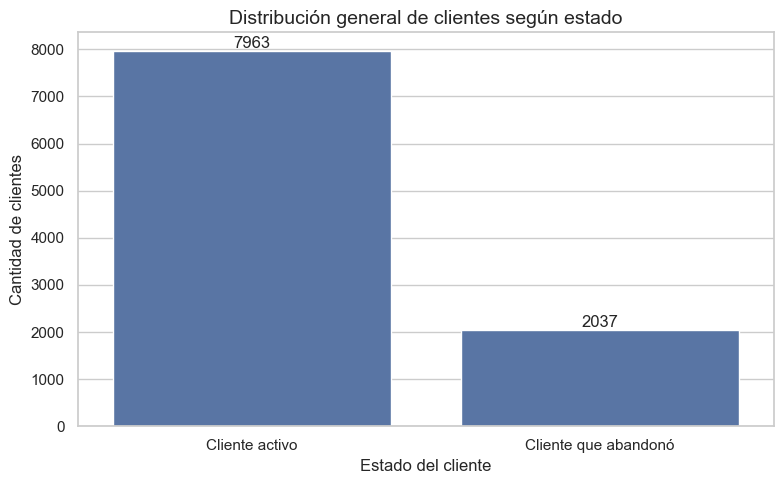

In [11]:
#-------------------------------------------------------------
# Visualización del churn
#-------------------------------------------------------------

# Preparación de datos para el gráfico
datos_churn = (
    df["Exited"]
    .map({
        0: "Cliente activo",
        1: "Cliente que abandonó"
    })
    .value_counts()
    .reset_index()
)

datos_churn.columns = [
    "Estado",
    "Cantidad"
]

# Gráfico
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=datos_churn,
    x="Estado",
    y="Cantidad"
)

# Etiquetas sobre las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.0f"
    )

plt.title(
    "Distribución general de clientes según estado"
)

plt.xlabel("Estado del cliente")
plt.ylabel("Cantidad de clientes")

plt.tight_layout()
plt.show()

**Interpretación**

El dataset contiene 10.000 clientes y mantiene la estructura utilizada durante los avances anteriores.

No se identificaron valores faltantes ni registros duplicados, por lo que no es necesario aplicar técnicas de imputación o eliminación de observaciones antes del análisis de clustering.

La distribución de la variable `Exited` muestra que aproximadamente el 20% de los clientes abandonó el banco, mientras que cerca del 80% permaneció activo.

Esta distribución coincide con el contexto general del proyecto y será utilizada posteriormente como referencia para comparar la tasa de churn de cada segmento.

Sin embargo, `Exited` no será incorporada en los algoritmos de clustering, ya que el objetivo es identificar grupos a partir de las características propias de los clientes y analizar su relación con el abandono únicamente después de haber construido los segmentos.

#### 4. Selección de Variables y Preprocesamiento

Los algoritmos de clustering buscan agrupar observaciones de acuerdo con su similitud.

Para que las distancias entre clientes sean comparables, es necesario preparar las variables antes de aplicar K-Means, DBSCAN, PCA y t-SNE.

El preprocesamiento incluirá:

- Exclusión de variables identificadoras.
- Separación de la variable `Exited`.
- Selección de características demográficas, financieras y de comportamiento.
- Estandarización de variables numéricas.
- Codificación de variables categóricas mediante One-Hot Encoding.
- Conservación de las variables binarias en formato `0/1`.


In [12]:
"""
Las columnas RowNumbre, CustomerId, Surname son variables que identifican 
registros o clientes, NO representan características demográficas, 
financieras o de comportamiento.
"""


# Variables excluidas por ser identificadores
variables_identificadoras = [
    "RowNumber",
    "CustomerId",
    "Surname"
]

# Variable de churn reservada para el análisis posterior
variable_churn = "Exited"

print("Variables identificadoras excluidas:")
for variable in variables_identificadoras:
    print(f"- {variable}")

print(
    f"\nVariable reservada para el análisis posterior: "
    f"{variable_churn}"
)

Variables identificadoras excluidas:
- RowNumber
- CustomerId
- Surname

Variable reservada para el análisis posterior: Exited


##### 4.1 Variables utilizadas para la Segmentación

Las variables seleccionadas representan diferentes dimensiones del perfil de cada cliente.

**Variables numéricas**

- `CreditScore`: puntaje crediticio.
- `Age`: edad.
- `Tenure`: antigüedad como cliente.
- `Balance`: saldo disponible.
- `NumOfProducts`: cantidad de productos contratados.
- `EstimatedSalary`: salario estimado.

**Variables categóricas**

- `Geography`: país de residencia.
- `Gender`: género registrado.

**Variables binarias**

- `HasCrCard`: indica si posee tarjeta de crédito.
- `IsActiveMember`: indica si es un miembro activo.

La variable `Exited` se conservará por separado y no será utilizada para construir los clusters.

In [13]:
# Variables numéricas
variables_numericas = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

# Variables categóricas
variables_categoricas = [
    "Geography",
    "Gender"
]

# Variables binarias
variables_binarias = [
    "HasCrCard",
    "IsActiveMember"
]

# Conjunto completo de variables para clustering
variables_clustering = (
    variables_numericas
    + variables_categoricas
    + variables_binarias
)

print(
    f"Cantidad de variables originales utilizadas: "
    f"{len(variables_clustering)}"
)

print("\nVariables seleccionadas:")

for numero, variable in enumerate(
    variables_clustering,
    start=1
):
    print(f"{numero}. {variable}")

Cantidad de variables originales utilizadas: 10

Variables seleccionadas:
1. CreditScore
2. Age
3. Tenure
4. Balance
5. NumOfProducts
6. EstimatedSalary
7. Geography
8. Gender
9. HasCrCard
10. IsActiveMember


In [14]:
# Resumen del tratamiento aplicado a cada variable
tabla_preprocesamiento = pd.DataFrame({
    "Variable": variables_clustering,
    "Tipo": (
        ["Numérica"] * len(variables_numericas)
        + ["Categórica"] * len(variables_categoricas)
        + ["Binaria"] * len(variables_binarias)
    ),
    "Tratamiento": (
        ["StandardScaler"] * len(variables_numericas)
        + ["One-Hot Encoding"] * len(
            variables_categoricas
        )
        + ["Se conserva en formato 0/1"] * len(
            variables_binarias
        )
    )
})

display(tabla_preprocesamiento)

,Variable,Tipo,Tratamiento
0,CreditScore,Numérica,StandardScaler
1,Age,Numérica,StandardScaler
2,Tenure,Numérica,StandardScaler
3,Balance,Numérica,StandardScaler
4,NumOfProducts,Numérica,StandardScaler
5,EstimatedSalary,Numérica,StandardScaler
6,Geography,Categórica,One-Hot Encoding
7,Gender,Categórica,One-Hot Encoding
8,HasCrCard,Binaria,Se conserva en formato 0/1
9,IsActiveMember,Binaria,Se conserva en formato 0/1


##### 4.2 Separación de las características y la variable churn

Se crearán dos objetos independientes:

- `X_clientes`: contendrá únicamente las características utilizadas por los algoritmos no supervisados.
- `y_churn`: conservará la variable `Exited` para analizar posteriormente la tasa de abandono dentro de cada cluster.

Esta separación evita que el churn influya en la formación de los segmentos.

In [15]:
# Matriz original de características para clustering
X_clientes = df[
    variables_clustering
].copy()

# Variable de churn reservada para análisis posteriores
y_churn = df[
    variable_churn
].copy()

print(
    "Dimensiones de la matriz original "
    f"de características: {X_clientes.shape}"
)

print(
    "Cantidad de registros en la variable "
    f"de churn: {y_churn.shape[0]}"
)

print(
    "\nLa variable 'Exited' no se encuentra "
    "dentro de X_clientes:"
)

print(
    variable_churn not in X_clientes.columns
)

Dimensiones de la matriz original de características: (10000, 10)
Cantidad de registros en la variable de churn: 10000

La variable 'Exited' no se encuentra dentro de X_clientes:
True


In [16]:
# Vista inicial de las variables seleccionadas
display(X_clientes.head())

Variable,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography,Gender,HasCrCard,IsActiveMember
0,619,42,2,0.00,1,101348.88,France,Female,1,1
1,608,41,1,83807.86,1,112542.58,Spain,Female,0,1
2,502,42,8,159660.80,3,113931.57,France,Female,1,0
3,699,39,1,0.00,2,93826.63,France,Female,0,0
4,850,43,2,125510.82,1,79084.10,Spain,Female,1,1


##### 4.3 Transformación de las Variables

Las variables requieren tratamientos diferentes según su naturaleza.

**Estandarización de variables numéricas**

Se utilizará `StandardScaler`, que transforma cada variable para que tenga aproximadamente:

- Media igual a `0`.
- Desviación estándar igual a `1`.

La estandarización es necesaria porque los algoritmos utilizados dependen de distancias o de la geometría de los datos.

Sin escalamiento, variables como `Balance` o `EstimatedSalary`, cuyos valores se encuentran en escalas monetarias elevadas, podrían dominar artificialmente las distancias y reducir la influencia de variables como `Age`, `Tenure` o `NumOfProducts`.

**Codificación de variables categóricas**

Se utilizará One-Hot Encoding para convertir las categorías de `Geography` y `Gender` en columnas binarias.

No se eliminará ninguna categoría mediante `drop="first"`.

En los modelos lineales del Avance 1 era útil eliminar una categoría de referencia para evitar redundancia e interpretar los coeficientes. En clustering no se estiman coeficientes, por lo que se conservarán todas las categorías para representar de manera simétrica las diferencias entre clientes.

**Variables binarias**

Las variables `HasCrCard` e `IsActiveMember` ya se encuentran codificadas como `0` y `1`, por lo que se mantendrán sin transformación.

In [17]:
# Preprocesador para aprendizaje no supervisado
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(
                drop=None,
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        ),
        (
            "binarias",
            "passthrough",
            variables_binarias
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print(
    "Preprocesador creado correctamente."
)

Preprocesador creado correctamente.


In [18]:
#-------------------------------------------------------------
# Aplicación del Preprocesamiento
#-------------------------------------------------------------

# Ajuste y transformación de los datos
X_cluster_array = (
    preprocesador
    .fit_transform(
        X_clientes
    )
)

# Recuperación de los nombres de las variables
nombres_variables_transformadas = (
    preprocesador
    .get_feature_names_out()
)

# Conversión a DataFrame
X_cluster = pd.DataFrame(
    X_cluster_array,
    columns=nombres_variables_transformadas,
    index=X_clientes.index
)

print(
    "Preprocesamiento completado correctamente."
)

print(
    "\nDimensiones de la matriz transformada:"
)

print(
    X_cluster.shape
)

Preprocesamiento completado correctamente.

Dimensiones de la matriz transformada:
(10000, 13)


In [19]:
# Lista final de variables utilizadas por los algoritmos
print(
    "Variables de la matriz transformada:"
)

for numero, variable in enumerate(
    X_cluster.columns,
    start=1
):
    print(
        f"{numero}. {variable}"
    )

Variables de la matriz transformada:
1. CreditScore
2. Age
3. Tenure
4. Balance
5. NumOfProducts
6. EstimatedSalary
7. Geography_France
8. Geography_Germany
9. Geography_Spain
10. Gender_Female
11. Gender_Male
12. HasCrCard
13. IsActiveMember


In [20]:
# Vista inicial de la matriz transformada
display(
    X_cluster.head()
)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,HasCrCard,IsActiveMember
0,-0.326221,0.293517,-1.041760,-1.225848,-0.911583,0.021886,1.0,0.0,0.0,1.0,0.0,1.0,1.0
1,-0.440036,0.198164,-1.387538,0.117350,-0.911583,0.216534,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,-1.536794,0.293517,1.032908,1.333053,2.527057,0.240687,1.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.501521,0.007457,-1.387538,-1.225848,0.807737,-0.108918,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2.063884,0.388871,-1.041760,0.785728,-0.911583,-0.365276,0.0,0.0,1.0,1.0,0.0,1.0,1.0


In [21]:
#-------------------------------------------------------------
# Validación de la Matriz Final
#-------------------------------------------------------------

# Validaciones de consistencia
cantidad_faltantes = (
    X_cluster
    .isna()
    .sum()
    .sum()
)

cantidad_infinitos = (
    np.isinf(
        X_cluster
        .to_numpy()
    )
    .sum()
)

columnas_no_permitidas = [
    "RowNumber",
    "CustomerId",
    "Surname",
    "Exited"
]

columnas_no_permitidas_presentes = [
    columna
    for columna in columnas_no_permitidas
    if columna in X_cluster.columns
]

print(
    "Validación de la matriz transformada"
)

print(
    "-" * 40
)

print(
    f"Cantidad de filas: "
    f"{X_cluster.shape[0]}"
)

print(
    f"Cantidad de variables: "
    f"{X_cluster.shape[1]}"
)

print(
    f"Valores faltantes: "
    f"{cantidad_faltantes}"
)

print(
    f"Valores infinitos: "
    f"{cantidad_infinitos}"
)

print(
    "Variables no permitidas presentes: "
    f"{columnas_no_permitidas_presentes}"
)

Validación de la matriz transformada
----------------------------------------
Cantidad de filas: 10000
Cantidad de variables: 13
Valores faltantes: 0
Valores infinitos: 0
Variables no permitidas presentes: []


In [22]:
# Comprobaciones automáticas
assert (
    X_cluster.shape[0]
    == df.shape[0]
), "Se modificó la cantidad de clientes."

assert (
    X_cluster.isna().sum().sum()
    == 0
), "La matriz contiene valores faltantes."

assert (
    np.isinf(
        X_cluster.to_numpy()
    ).sum()
    == 0
), "La matriz contiene valores infinitos."

assert (
    variable_churn
    not in X_cluster.columns
), "Exited fue incorporada por error."

assert (
    not columnas_no_permitidas_presentes
), "Se incorporaron variables no permitidas."

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


In [23]:
#-------------------------------------------------------------
# Verificación de la Estandarización
#-------------------------------------------------------------

# Media y desviación estándar de las variables numéricas transformadas
tabla_escalamiento = pd.DataFrame({
    "Media": (
        X_cluster[
            variables_numericas
        ]
        .mean()
    ),
    "Desviación estándar": (
        X_cluster[
            variables_numericas
        ]
        .std(
            ddof=0
        )
    )
}).round(4)

display(
    tabla_escalamiento
)

,Media,Desviación estándar
CreditScore,-0.0,1.0
Age,0.0,1.0
Tenure,-0.0,1.0
Balance,-0.0,1.0
NumOfProducts,-0.0,1.0
EstimatedSalary,-0.0,1.0


In [24]:
# Copia de los datos originales para la interpretación posterior
df_perfiles = (
    X_clientes
    .copy()
)

print(
    "Datos originales conservados "
    "para el análisis de perfiles."
)

print(
    f"Dimensiones: "
    f"{df_perfiles.shape}"
)

Datos originales conservados para el análisis de perfiles.
Dimensiones: (10000, 10)


**Interpretación del preprocesamiento**

Se seleccionaron diez variables demográficas, financieras y de comportamiento para representar el perfil de los clientes.

Las variables identificadoras `RowNumber`, `CustomerId` y `Surname` fueron excluidas porque no describen características relevantes para la segmentación y podrían generar agrupamientos artificiales.

La variable `Exited` se mantuvo separada y no participó en ninguna transformación ni será utilizada para construir los clusters.

Las seis variables numéricas fueron estandarizadas mediante `StandardScaler`, obteniendo medias cercanas a cero y desviaciones estándar cercanas a uno.

Las variables `Geography` y `Gender` fueron transformadas mediante One-Hot Encoding, conservando todas sus categorías.

Las variables binarias `HasCrCard` e `IsActiveMember` mantuvieron su representación original en formato `0/1`.

Como resultado, se obtuvo una matriz completamente numérica compuesta por 10.000 clientes y 13 características transformadas.

La matriz no contiene valores faltantes, valores infinitos ni variables identificadoras o relacionadas con el churn, por lo que se encuentra preparada para la aplicación de K-Means, DBSCAN, PCA y t-SNE.

#### 5. Selección del número de clusters para K-Means

K-Means requiere definir previamente la cantidad de clusters que se desea construir.

El parámetro `K` representa el número de grupos o segmentos en los que se dividirán las observaciones.

Seleccionar un valor demasiado bajo puede generar segmentos excesivamente generales y ocultar diferencias relevantes entre los clientes.

Por el contrario, utilizar una cantidad muy elevada puede producir grupos pequeños, difíciles de interpretar y poco útiles desde una perspectiva de negocio.

Para orientar la selección se utilizarán dos métodos complementarios:

- Método del codo.
- Coeficiente de silueta.

Se evaluarán valores de `K` comprendidos entre 2 y 10.

La selección final considerará conjuntamente:

- La evolución de la inercia.
- El coeficiente de silueta.
- La restricción de identificar entre 3 y 5 segmentos principales.
- La distribución de clientes entre los clusters.
- La interpretabilidad de los perfiles obtenidos.

##### 5.1 Funcionamiento general de K-Means

K-Means es un algoritmo de clustering particional que organiza las observaciones en una cantidad previamente definida de grupos.

El procedimiento se desarrolla de manera iterativa:

1. Se seleccionan inicialmente `K` centroides.

2. Cada cliente se asigna al centroide más cercano.

3. Los centroides se recalculan utilizando el promedio de las observaciones asignadas a cada grupo.

4. Los clientes vuelven a asignarse según las nuevas posiciones de los centroides.

5. El proceso se repite hasta alcanzar la convergencia o llegar al número máximo de iteraciones.

Cada centroide representa el perfil promedio de un cluster dentro del espacio de variables transformadas.

El objetivo del algoritmo es reducir la distancia entre las observaciones y el centroide correspondiente.

##### 5.2 Método del codo

El método del codo analiza la inercia obtenida para diferentes cantidades de clusters.

La inercia representa la suma de las distancias cuadráticas entre cada observación y el centroide del cluster al que pertenece.

Una inercia menor indica que los clientes se encuentran más próximos a sus respectivos centroides.

Sin embargo, la inercia siempre disminuye cuando aumenta el número de clusters. Por este motivo, no debe seleccionarse automáticamente el valor con menor inercia.

El objetivo es identificar un punto a partir del cual agregar nuevos clusters produce mejoras cada vez menores.

Ese cambio en la pendiente de la curva se conoce como “codo”.

##### 5.3 Coeficiente de silueta

El coeficiente de silueta evalúa simultáneamente:

- La cohesión interna de cada cluster.
- La separación respecto de los demás clusters.

Sus valores se encuentran entre `-1` y `1`.

Interpretación general:

- Valores cercanos a `1`: los grupos presentan buena cohesión interna y separación.

- Valores cercanos a `0`: existe superposición entre los clusters.

- Valores negativos: algunas observaciones podrían encontrarse asignadas a un cluster poco adecuado.

El mayor coeficiente de silueta constituye una referencia importante, pero no determina automáticamente la mejor solución.

La selección final también debe considerar la interpretabilidad, el tamaño de los segmentos y su utilidad para el negocio.

In [25]:
# Valores de K que serán evaluados
valores_k = range(2, 11)

# Listas para almacenar los resultados
inercias = []
coeficientes_silueta = []
iteraciones_convergencia = []

# Evaluación de cada cantidad de clusters
for k in valores_k:

    # Creación del modelo
    modelo_kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        max_iter=300,
        random_state=RANDOM_STATE
    )

    # Entrenamiento y generación de etiquetas
    etiquetas_k = modelo_kmeans.fit_predict(
        X_cluster
    )

    # Inercia
    inercias.append(
        modelo_kmeans.inertia_
    )

    # Coeficiente de silueta
    coeficiente_k = silhouette_score(
        X_cluster,
        etiquetas_k,
        sample_size=3000,
        random_state=RANDOM_STATE
    )

    coeficientes_silueta.append(
        coeficiente_k
    )

    # Cantidad de iteraciones hasta convergencia
    iteraciones_convergencia.append(
        modelo_kmeans.n_iter_
    )

print(
    "Evaluación de valores de K completada."
)

Evaluación de valores de K completada.


In [26]:
# Creación de la tabla de resultados
resultados_kmeans = pd.DataFrame({
    "K": list(valores_k),
    "Inercia": inercias,
    "Coeficiente de silueta": coeficientes_silueta,
    "Iteraciones hasta convergencia": (
        iteraciones_convergencia
    )
})

# Reducción porcentual de la inercia
resultados_kmeans[
    "Reducción porcentual de inercia"
] = (
    resultados_kmeans["Inercia"]
    .pct_change()
    .mul(-100)
)

# Tabla para visualización
tabla_resultados_kmeans = (
    resultados_kmeans
    .copy()
)

tabla_resultados_kmeans[
    "Inercia"
] = (
    tabla_resultados_kmeans[
        "Inercia"
    ]
    .round(2)
)

tabla_resultados_kmeans[
    "Coeficiente de silueta"
] = (
    tabla_resultados_kmeans[
        "Coeficiente de silueta"
    ]
    .round(4)
)

tabla_resultados_kmeans[
    "Reducción porcentual de inercia"
] = (
    tabla_resultados_kmeans[
        "Reducción porcentual de inercia"
    ]
    .round(2)
)

display(
    tabla_resultados_kmeans
)

,K,Inercia,Coeficiente de silueta,Iteraciones hasta convergencia,Reducción porcentual de inercia
0,2,65196.00,0.1443,11,NaN
1,3,60490.79,0.1143,21,7.22
2,4,56180.40,0.1299,10,7.13
3,5,53290.36,0.1165,20,5.14
4,6,50784.55,0.1064,25,4.70
5,7,48904.10,0.1054,46,3.70
6,8,47332.05,0.1012,37,3.21
7,9,45784.77,0.0994,70,3.27
8,10,44524.59,0.1013,86,2.75


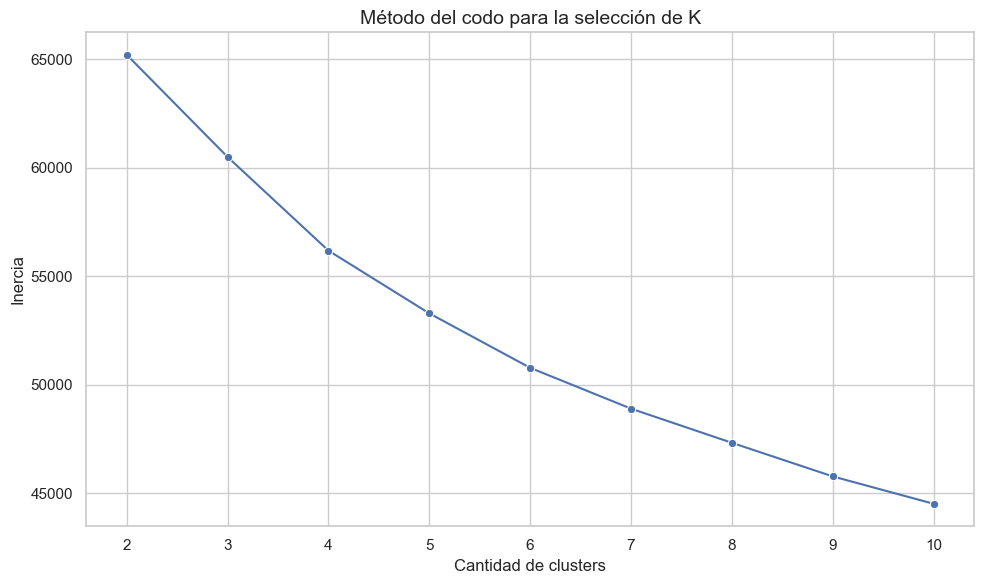

In [27]:
# Gráfico del método del codo
plt.figure(
    figsize=(10, 6)
)

sns.lineplot(
    data=resultados_kmeans,
    x="K",
    y="Inercia",
    marker="o"
)

plt.title(
    "Método del codo para la selección de K"
)

plt.xlabel(
    "Cantidad de clusters"
)

plt.ylabel(
    "Inercia"
)

plt.xticks(
    list(valores_k)
)

plt.tight_layout()

plt.show()

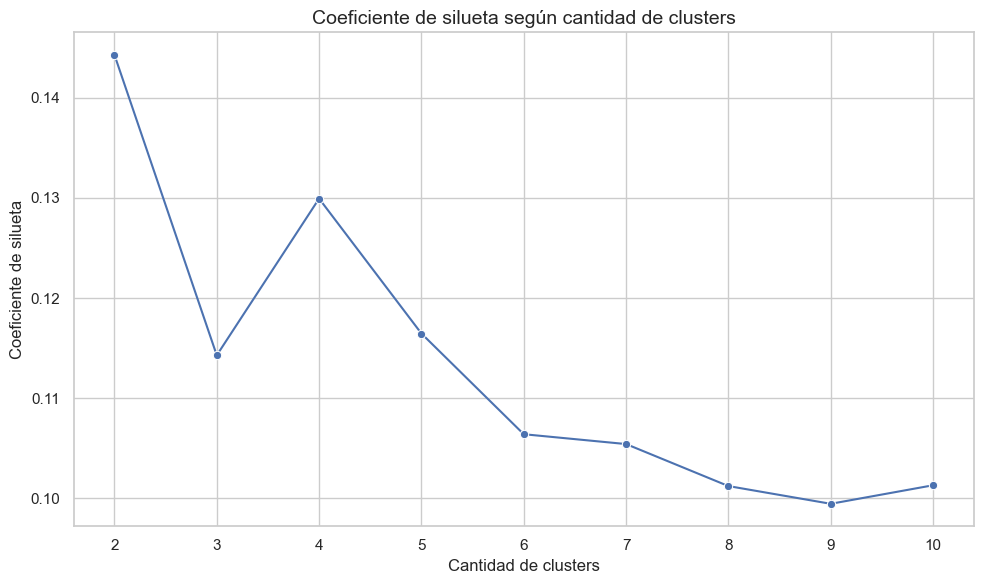

In [28]:
# Gráfico del coeficiente de silueta
plt.figure(
    figsize=(10, 6)
)

sns.lineplot(
    data=resultados_kmeans,
    x="K",
    y="Coeficiente de silueta",
    marker="o"
)

plt.title(
    "Coeficiente de silueta según cantidad de clusters"
)

plt.xlabel(
    "Cantidad de clusters"
)

plt.ylabel(
    "Coeficiente de silueta"
)

plt.xticks(
    list(valores_k)
)

plt.tight_layout()

plt.show()

In [29]:
# Identificacion del mejor K según silueta

# Fila con el mayor coeficiente de silueta
fila_mejor_silueta = (
    resultados_kmeans
    .loc[
        resultados_kmeans[
            "Coeficiente de silueta"
        ]
        .idxmax()
    ]
)

# Valores principales
k_mejor_silueta = int(
    fila_mejor_silueta["K"]
)

mejor_coeficiente = (
    fila_mejor_silueta[
        "Coeficiente de silueta"
    ]
)

print(
    "Mejor resultado según "
    "coeficiente de silueta"
)

print(
    "-" * 40
)

print(
    f"K: {k_mejor_silueta}"
)

print(
    "Coeficiente de silueta: "
    f"{mejor_coeficiente:.4f}"
)

Mejor resultado según coeficiente de silueta
----------------------------------------
K: 2
Coeficiente de silueta: 0.1443


##### 5.4 Comparación específica entre 3 y 5 clusters

In [30]:
# Soluciones compatibles con la consigna
resultados_candidatos = (
    resultados_kmeans[
        resultados_kmeans[
            "K"
        ]
        .between(
            3,
            5
        )
    ]
    .copy()
)

# Redondeo para visualización
resultados_candidatos[
    "Inercia"
] = (
    resultados_candidatos[
        "Inercia"
    ]
    .round(2)
)

resultados_candidatos[
    "Coeficiente de silueta"
] = (
    resultados_candidatos[
        "Coeficiente de silueta"
    ]
    .round(4)
)

resultados_candidatos[
    "Reducción porcentual de inercia"
] = (
    resultados_candidatos[
        "Reducción porcentual de inercia"
    ]
    .round(2)
)

display(
    resultados_candidatos
)

,K,Inercia,Coeficiente de silueta,Iteraciones hasta convergencia,Reducción porcentual de inercia
1,3,60490.79,0.1143,21,7.22
2,4,56180.40,0.1299,10,7.13
3,5,53290.36,0.1165,20,5.14


**Selección del número final de clusters**

Los resultados muestran que el mayor coeficiente de silueta global corresponde a `K = 2`, con un valor de `0,1443`.

Sin embargo, el objetivo del proyecto consiste en identificar entre 3 y 5 segmentos principales. Dentro de ese intervalo, la solución con `K = 4` obtuvo el mayor coeficiente de silueta, alcanzando un valor de `0,1299`.

El análisis del método del codo también respalda esta alternativa. La reducción de la inercia se mantiene elevada hasta cuatro clusters y comienza a disminuir con mayor intensidad a partir de ese punto.

La reducción de la inercia al pasar de tres a cuatro clusters fue del `7,13%`, mientras que al pasar de cuatro a cinco clusters disminuyó al `5,14%`.

Por lo tanto, se seleccionó:

**K = 4**

La elección representa un equilibrio entre:

- Cohesión interna y separación de los grupos.
- Reducción de la inercia.
- Cantidad de segmentos requerida.
- Complejidad de la solución.
- Potencial de interpretación desde una perspectiva de negocio.

El coeficiente de silueta obtenido es relativamente bajo, lo que indica que existe cierto nivel de superposición entre los perfiles de clientes.

Este resultado no invalida la segmentación. En datos reales, los comportamientos suelen formar estructuras continuas y no necesariamente grupos completamente separados.

La utilidad final de los cuatro clusters será evaluada mediante el análisis de su tamaño, sus centroides y las características demográficas, financieras y de comportamiento de los clientes asignados a cada segmento.

La variable `Exited` no fue utilizada para seleccionar el número de clusters.

#### 6. Implementación y evaluación del modelo K-Means definitivo

Luego de evaluar diferentes cantidades de clusters mediante el método del codo y el coeficiente de silueta, se seleccionó una solución compuesta por cuatro segmentos.

La elección de `K = 4` se fundamentó en los siguientes resultados:

- Presentó el mayor coeficiente de silueta dentro del rango solicitado de 3 a 5 segmentos.
- Alcanzó un coeficiente de silueta de aproximadamente `0,1299`.
- Conservó una reducción relevante de la inercia respecto de la solución con tres clusters.
- A partir del quinto cluster, la mejora relativa de la inercia comenzó a disminuir.
- Cuatro segmentos representan una cantidad suficientemente detallada y, al mismo tiempo, manejable desde una perspectiva de negocio.

En este bloque se entrenará el modelo definitivo utilizando la totalidad de los clientes y la matriz de características previamente transformada.

La variable `Exited` continuará excluida del proceso de clustering.

In [31]:
# Cantidad final de clusters seleccionada
K_FINAL = 4

print(
    "Cantidad final de clusters "
    f"seleccionada: {K_FINAL}"
)

Cantidad final de clusters seleccionada: 4


##### 6.1 Entrenamiento del modelo

El modelo K-Means definitivo utilizará los mismos parámetros definidos durante la etapa de evaluación.

Parámetros principales:

- `n_clusters=4`: cantidad de segmentos seleccionada.
- `init="k-means++"`: estrategia utilizada para inicializar los centroides de manera más eficiente.
- `n_init=20`: cantidad de inicializaciones independientes ejecutadas.
- `max_iter=300`: cantidad máxima de iteraciones permitida para alcanzar la convergencia.
- `random_state=42`: semilla utilizada para favorecer la reproducibilidad.

El modelo será ajustado utilizando `X_cluster`, que contiene las variables numéricas estandarizadas, las variables categóricas codificadas y las variables binarias.

In [32]:
# Creación del modelo K-Means definitivo
modelo_kmeans_final = KMeans(
    n_clusters=K_FINAL,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=RANDOM_STATE
)

# Entrenamiento y asignación de clusters
etiquetas_kmeans = (
    modelo_kmeans_final
    .fit_predict(
        X_cluster
    )
)

print(
    "Modelo K-Means definitivo "
    "entrenado correctamente."
)

print(
    f"Cantidad de clientes segmentados: "
    f"{len(etiquetas_kmeans)}"
)

Modelo K-Means definitivo entrenado correctamente.
Cantidad de clientes segmentados: 10000


##### 6.2 Evaluación global del modelo definitivo

La solución final será evaluada mediante:

- Inercia.
- Coeficiente de silueta.
- Cantidad de iteraciones requeridas para alcanzar la convergencia.
- Cantidad efectiva de clusters generados.

La inercia mide la suma de las distancias cuadráticas entre cada cliente y el centroide del cluster asignado.

El coeficiente de silueta evalúa la cohesión interna de los grupos y su separación respecto de los demás clusters.

Para mantener consistencia con la comparación realizada durante la selección de `K`, el coeficiente de silueta se calculará utilizando una muestra reproducible de 3.000 clientes.

In [33]:
# Cálculo del coeficiente de silueta
silueta_kmeans_final = silhouette_score(
    X_cluster,
    etiquetas_kmeans,
    sample_size=3000,
    random_state=RANDOM_STATE
)

# Cantidad efectiva de clusters obtenidos
cantidad_clusters_obtenidos = (
    np.unique(
        etiquetas_kmeans
    ).size
)

# Tabla resumen del modelo definitivo
resumen_kmeans_visual = pd.DataFrame({
    "Indicador": [
        "Cantidad de clusters",
        "Inercia",
        "Coeficiente de silueta",
        "Iteraciones hasta convergencia"
    ],
    "Resultado": [
        int(
            cantidad_clusters_obtenidos
        ),
        round(
            float(
                modelo_kmeans_final.inertia_
            ),
            2
        ),
        round(
            float(
                silueta_kmeans_final
            ),
            4
        ),
        int(
            modelo_kmeans_final.n_iter_
        )
    ]
})

display(
    resumen_kmeans_visual
)

,Indicador,Resultado
0,Cantidad de clusters,4.0000
1,Inercia,56180.4000
2,Coeficiente de silueta,0.1299
3,Iteraciones hasta convergencia,10.0000


##### 6.3 Incorporación de las etiquetas de cluster

K-Means asigna a cada cliente una etiqueta numérica que identifica el cluster al que pertenece.

Las etiquetas serán incorporadas a una copia del dataset original mediante la nueva variable:

`Cluster_KMeans`

La numeración de los clusters es arbitraria.

Por ejemplo, el `Cluster 0` no representa necesariamente un segmento mejor, peor, más rentable o de mayor riesgo que el `Cluster 1`.

Los números funcionan únicamente como identificadores y no poseen un orden jerárquico.

La interpretación de cada segmento se realizará posteriormente a partir de sus características demográficas, financieras y de comportamiento.

In [34]:
# Copia del dataset original
df_segmentacion = (
    df
    .copy()
)

# Incorporación de las etiquetas
df_segmentacion[
    "Cluster_KMeans"
] = etiquetas_kmeans

print(
    "Variable 'Cluster_KMeans' "
    "incorporada correctamente."
)

print(
    "\nDimensiones del dataset "
    "enriquecido:"
)

print(
    df_segmentacion.shape
)

Variable 'Cluster_KMeans' incorporada correctamente.

Dimensiones del dataset enriquecido:
(10000, 15)


In [35]:
# Vista de las primeras asignaciones
display(
    df_segmentacion[
        [
            "CustomerId",
            "Geography",
            "Gender",
            "Age",
            "Balance",
            "NumOfProducts",
            "Cluster_KMeans"
        ]
    ]
    .head(10)
)

Variable,CustomerId,Geography,Gender,Age,Balance,NumOfProducts,Cluster_KMeans
0,15634602,France,Female,42,0.00,1,1
1,15647311,Spain,Female,41,83807.86,1,2
2,15619304,France,Female,42,159660.80,3,0
3,15701354,France,Female,39,0.00,2,1
4,15737888,Spain,Female,43,125510.82,1,2
5,15574012,Spain,Male,44,113755.78,2,0
6,15592531,France,Male,50,0.00,2,1
7,15656148,Germany,Female,29,115046.74,4,0
8,15792365,France,Male,44,142051.07,2,0
9,15592389,France,Male,27,134603.88,1,2


##### 6.4 Distribución de clientes entre los clusters

Ahora, se analizará la cantidad y el porcentaje de clientes asignados a cada segmento.

Este análisis permitirá verificar:

- Si todos los clusters contienen observaciones.
- Si existen segmentos excesivamente pequeños.
- Si la distribución resulta razonablemente equilibrada.
- Si los grupos tienen un tamaño suficiente para ser analizados desde una perspectiva de negocio.

Un cluster pequeño no representa necesariamente un error, ya que podría corresponder a un perfil particular.

Sin embargo, los grupos extremadamente reducidos deben analizarse con cautela debido a su menor representatividad.

In [36]:
# Cantidad de clientes por cluster
tabla_distribucion_kmeans = (
    pd.Series(
        etiquetas_kmeans,
        name="Cluster"
    )
    .value_counts()
    .sort_index()
    .rename_axis(
        "Cluster"
    )
    .reset_index(
        name="Cantidad de clientes"
    )
)

# Porcentaje sobre la base total
tabla_distribucion_kmeans[
    "Porcentaje"
] = (
    tabla_distribucion_kmeans[
        "Cantidad de clientes"
    ]
    .div(
        len(
            etiquetas_kmeans
        )
    )
    .mul(100)
    .round(2)
)

# Etiqueta descriptiva
tabla_distribucion_kmeans[
    "Segmento"
] = (
    "Cluster "
    + tabla_distribucion_kmeans[
        "Cluster"
    ]
    .astype(str)
)

# Reordenamiento de columnas
tabla_distribucion_kmeans = (
    tabla_distribucion_kmeans[
        [
            "Cluster",
            "Segmento",
            "Cantidad de clientes",
            "Porcentaje"
        ]
    ]
)

display(
    tabla_distribucion_kmeans
)

,Cluster,Segmento,Cantidad de clientes,Porcentaje
0,0,Cluster 0,1978,19.78
1,1,Cluster 1,3269,32.69
2,2,Cluster 2,3500,35.00
3,3,Cluster 3,1253,12.53


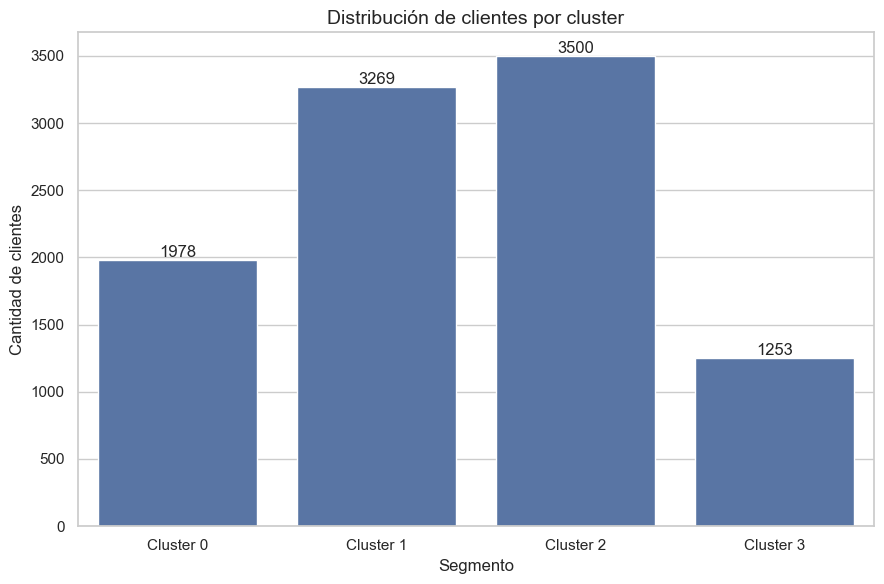

In [37]:
# Gráfico de cantidad de clientes
# por cluster
plt.figure(
    figsize=(9, 6)
)

ax = sns.barplot(
    data=tabla_distribucion_kmeans,
    x="Segmento",
    y="Cantidad de clientes"
)

# Etiquetas sobre las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.0f"
    )

plt.title(
    "Distribución de clientes por cluster"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Cantidad de clientes"
)

plt.tight_layout()

plt.show()

##### 6.5 Validación de la segmentación

Antes de continuar con la interpretación de los perfiles, se verificará que:

- Los 10.000 clientes recibieron una etiqueta.
- Se generaron exactamente cuatro clusters.
- No existen etiquetas faltantes.
- Ningún cluster quedó vacío.
- La cantidad total de clientes coincide con el dataset original.
- La suma de los porcentajes es igual al 100%.

In [38]:
# Clusters esperados
clusters_esperados = set(
    range(
        K_FINAL
    )
)

# Clusters obtenidos
clusters_obtenidos = set(
    np.unique(
        etiquetas_kmeans
    )
)

# Validaciones principales
cantidad_asignaciones = (
    len(
        etiquetas_kmeans
    )
)

etiquetas_faltantes = (
    df_segmentacion[
        "Cluster_KMeans"
    ]
    .isna()
    .sum()
)

suma_clientes = (
    tabla_distribucion_kmeans[
        "Cantidad de clientes"
    ]
    .sum()
)

suma_porcentajes = (
    tabla_distribucion_kmeans[
        "Porcentaje"
    ]
    .sum()
)

print(
    "Validación de la segmentación"
)

print(
    "-" * 40
)

print(
    f"Clientes originales: "
    f"{df.shape[0]}"
)

print(
    f"Clientes con cluster asignado: "
    f"{cantidad_asignaciones}"
)

print(
    f"Etiquetas faltantes: "
    f"{etiquetas_faltantes}"
)

print(
    f"Clusters esperados: "
    f"{sorted(clusters_esperados)}"
)

print(
    f"Clusters obtenidos: "
    f"{sorted(clusters_obtenidos)}"
)

print(
    f"Total de clientes en la tabla: "
    f"{suma_clientes}"
)

print(
    f"Suma de porcentajes: "
    f"{suma_porcentajes:.2f}%"
)

Validación de la segmentación
----------------------------------------
Clientes originales: 10000
Clientes con cluster asignado: 10000
Etiquetas faltantes: 0
Clusters esperados: [0, 1, 2, 3]
Clusters obtenidos: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
Total de clientes en la tabla: 10000
Suma de porcentajes: 100.00%


In [39]:
# Comprobaciones automáticas
assert (
    cantidad_asignaciones
    == df.shape[0]
), (
    "No todos los clientes "
    "recibieron una etiqueta."
)

assert (
    etiquetas_faltantes
    == 0
), (
    "Existen etiquetas de "
    "cluster faltantes."
)

assert (
    clusters_obtenidos
    == clusters_esperados
), (
    "La cantidad de clusters "
    "no coincide con la esperada."
)

assert (
    suma_clientes
    == df.shape[0]
), (
    "La suma de clientes "
    "no coincide con el total."
)

assert np.isclose(
    suma_porcentajes,
    100,
    atol=0.05
), (
    "Los porcentajes no "
    "suman aproximadamente 100%."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Resultado e interpretación del modelo K-Means definitivo**

El modelo K-Means definitivo fue entrenado utilizando cuatro clusters y la totalidad de los 10.000 clientes disponibles.

La solución obtuvo una inercia de `56.180,40` y un coeficiente de silueta de `0,1299`, coincidiendo con los resultados obtenidos durante la etapa de selección del número de clusters.

El algoritmo alcanzó la convergencia en 10 iteraciones, una cantidad considerablemente inferior al máximo establecido de 300 iteraciones.

La distribución de clientes fue la siguiente:

- Cluster 0: 1.978 clientes, equivalentes al 19,78% de la base.
- Cluster 1: 3.269 clientes, equivalentes al 32,69% de la base.
- Cluster 2: 3.500 clientes, equivalentes al 35,00% de la base.
- Cluster 3: 1.253 clientes, equivalentes al 12,53% de la base.

Aunque los segmentos presentan tamaños diferentes, todos contienen una cantidad suficiente de clientes para realizar análisis descriptivos e interpretar sus características.

El Cluster 3 es el segmento de menor tamaño, pero representa más del 12% de la base total, por lo que no puede considerarse un grupo residual.

Las validaciones confirmaron que:

- Los 10.000 clientes recibieron una etiqueta.
- No existen asignaciones faltantes.
- Se obtuvieron exactamente los cuatro clusters esperados.
- Ningún cluster quedó vacío.
- La distribución representa el 100% de la base.

La numeración de los clusters funciona únicamente como identificador y no representa un orden de valor, riesgo o importancia.

La evaluación cuantitativa deberá complementarse con la interpretación de los centroides y el análisis de las características demográficas, financieras y de comportamiento de cada segmento.

#### 7. Interpretación de centroides y construcción de perfiles

Cada cluster generado por K-Means se encuentra representado por un centroide.

El centroide contiene el valor promedio de cada característica dentro del espacio utilizado por el algoritmo.

Debido al preprocesamiento aplicado:

- Las variables numéricas se encuentran expresadas en unidades estandarizadas.
- Las variables categóricas codificadas representan proporciones aproximadas de cada categoría.
- Las variables binarias representan la proporción de clientes que presentan cada característica.

Los centroides permiten identificar qué variables distinguen principalmente a cada grupo.

In [40]:
# Obtención de los centroides en el espacio transformado
centroides_transformados = pd.DataFrame(
    modelo_kmeans_final.cluster_centers_,
    columns=X_cluster.columns
)

# Etiquetas descriptivas para las filas
centroides_transformados.index = [
    f"Cluster {cluster}"
    for cluster in range(K_FINAL)
]

centroides_transformados.index.name = "Segmento"

# Visualización
display(
    centroides_transformados.round(3)
)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,HasCrCard,IsActiveMember
Segmento,,,,,,,,,,,,,
Cluster 0,0.025,-0.195,-0.007,0.725,1.033,0.056,0.300,0.544,0.155,0.463,0.537,0.702,0.499
Cluster 1,-0.019,-0.308,0.038,-1.210,0.502,-0.010,0.671,0.002,0.328,0.452,0.548,0.712,0.497
Cluster 2,-0.005,-0.288,-0.007,0.712,-0.912,0.019,0.465,0.313,0.222,0.440,0.560,0.706,0.486
Cluster 3,0.024,1.915,-0.068,0.022,-0.394,-0.113,0.478,0.265,0.257,0.487,0.513,0.695,0.669


##### 7.1 Centroides de las variables numéricas

Las variables numéricas fueron transformadas mediante `StandardScaler`.

Por lo tanto, los valores de los centroides se interpretan en relación con el promedio general:

- Valor cercano a `0`: comportamiento próximo al promedio.
- Valor positivo: valor superior al promedio.
- Valor negativo: valor inferior al promedio.

Cuanto mayor sea la distancia respecto de cero, mayor será la diferencia del cluster en relación con el comportamiento general de la base.

Esta representación permite comparar qué características numéricas distinguen a cada segmento.

In [41]:
# Centroides correspondientes a las variables numéricas estandarizadas
centroides_numericos_std = (
    centroides_transformados[
        variables_numericas
    ]
    .copy()
)

display(
    centroides_numericos_std.round(3)
)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Segmento,,,,,,
Cluster 0,0.025,-0.195,-0.007,0.725,1.033,0.056
Cluster 1,-0.019,-0.308,0.038,-1.210,0.502,-0.010
Cluster 2,-0.005,-0.288,-0.007,0.712,-0.912,0.019
Cluster 3,0.024,1.915,-0.068,0.022,-0.394,-0.113


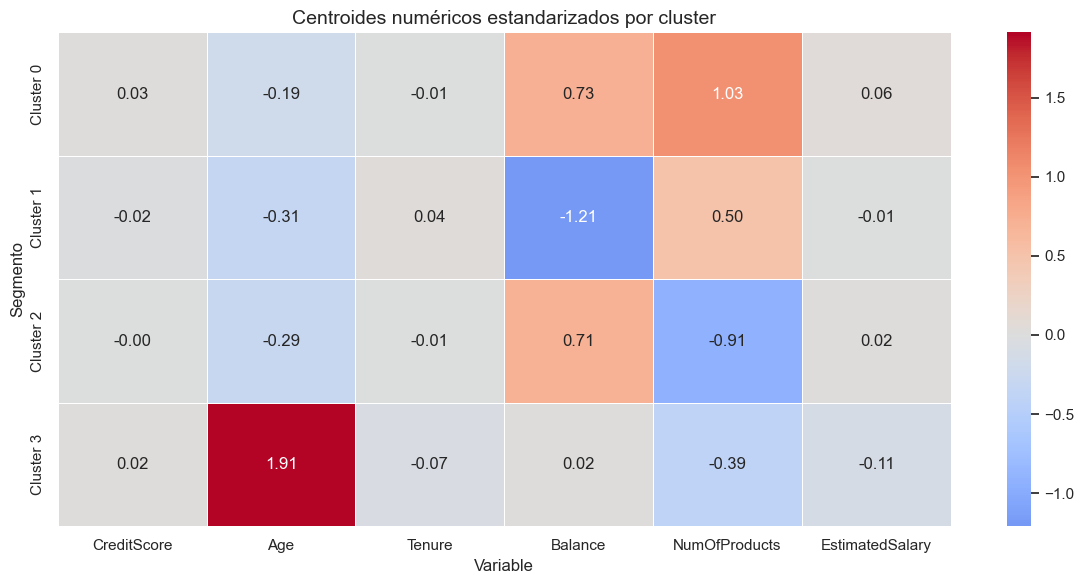

In [42]:
# Mapa de calor de los centroides numéricos estandarizados
plt.figure(
    figsize=(12, 6)
)

sns.heatmap(
    centroides_numericos_std,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Centroides numéricos estandarizados por cluster"
)

plt.xlabel(
    "Variable"
)

plt.ylabel(
    "Segmento"
)

plt.tight_layout()

plt.show()

##### 7.2 Perfil numérico de los segmentos

Aunque los centroides estandarizados son útiles para comparar los clusters, no resultan suficientemente intuitivos para una interpretación de negocio.

Por este motivo, se calcularán las medias y medianas utilizando las variables originales.

Esto permitirá describir los segmentos mediante valores comprensibles, por ejemplo:

- Edad promedio en años.
- Saldo promedio.
- Cantidad promedio de productos.
- Antigüedad promedio.
- Puntaje crediticio promedio.
- Salario estimado promedio.

La mediana se incorporará como complemento porque resulta menos sensible a valores extremos.

In [43]:
# Valores promedio de las variables numéricas por cluster
perfil_numerico_media = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )[
        variables_numericas
    ]
    .mean()
    .round(2)
)

# Etiquetas descriptivas
perfil_numerico_media.index = [
    f"Cluster {cluster}"
    for cluster in perfil_numerico_media.index
]

perfil_numerico_media.index.name = "Segmento"

display(
    perfil_numerico_media
)

Variable,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Segmento,,,,,,
Cluster 0,652.95,36.88,4.99,121746.10,2.13,103310.47
Cluster 1,648.66,35.69,5.12,1002.20,1.82,99490.07
Cluster 2,649.99,35.90,4.99,120929.25,1.00,101129.46
Cluster 3,653.08,59.02,4.82,77826.47,1.30,93669.71


In [44]:
# Medianas de las variables numéricas por cluster
perfil_numerico_mediana = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )[
        variables_numericas
    ]
    .median()
    .round(2)
)

# Etiquetas descriptivas
perfil_numerico_mediana.index = [
    f"Cluster {cluster}"
    for cluster in perfil_numerico_mediana.index
]

perfil_numerico_mediana.index.name = "Segmento"

display(
    perfil_numerico_mediana
)

Variable,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Segmento,,,,,,
Cluster 0,652.0,37.0,5.0,121172.14,2.0,104185.62
Cluster 1,649.0,36.0,5.0,0.00,2.0,98820.09
Cluster 2,652.0,36.0,5.0,120942.83,1.0,101936.87
Cluster 3,655.0,58.0,5.0,96891.46,1.0,89935.73


##### 7.3 Composición geográfica de los clusters

La variable `Geography` fue transformada mediante One-Hot Encoding para participar en el algoritmo.

Para interpretar los resultados se calculará el porcentaje de clientes correspondiente a cada país dentro de cada cluster.

Esto permitirá determinar si los segmentos presentan una composición geográfica diferenciada.

In [45]:
# Distribución porcentual de países dentro de cada cluster
tabla_geografia_cluster = (
    pd.crosstab(
        df_segmentacion[
            "Cluster_KMeans"
        ],
        df_segmentacion[
            "Geography"
        ],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

# Etiquetas descriptivas
tabla_geografia_cluster.index = [
    f"Cluster {cluster}"
    for cluster in tabla_geografia_cluster.index
]

tabla_geografia_cluster.index.name = "Segmento"

display(
    tabla_geografia_cluster
)

Geography,France,Germany,Spain
Segmento,,,
Cluster 0,30.03,54.45,15.52
Cluster 1,67.05,0.15,32.79
Cluster 2,46.54,31.26,22.20
Cluster 3,47.81,26.58,25.62


##### 7.4 Composición por género

Se calculará la distribución porcentual de la variable `Gender` dentro de cada segmento.

Este análisis permitirá identificar si alguno de los clusters presenta una composición predominantemente femenina o masculina.

In [46]:
# Distribución porcentual por género dentro de cada cluster
tabla_genero_cluster = (
    pd.crosstab(
        df_segmentacion[
            "Cluster_KMeans"
        ],
        df_segmentacion[
            "Gender"
        ],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

# Etiquetas descriptivas
tabla_genero_cluster.index = [
    f"Cluster {cluster}"
    for cluster in tabla_genero_cluster.index
]

tabla_genero_cluster.index.name = "Segmento"

display(
    tabla_genero_cluster
)

Gender,Female,Male
Segmento,,
Cluster 0,46.31,53.69
Cluster 1,45.18,54.82
Cluster 2,44.00,56.00
Cluster 3,48.68,51.32


##### 7.5 Tenencia de tarjeta y nivel de actividad

Las variables binarias se interpretarán como porcentajes.

Debido a que sus valores son:

- `0`: ausencia de la característica.
- `1`: presencia de la característica.

El promedio de cada variable representa directamente la proporción de clientes que cumple la condición.

Se analizarán:

- Porcentaje de clientes con tarjeta de crédito.
- Porcentaje de clientes activos.

In [47]:
# Porcentaje de clientes con tarjeta y porcentaje de clientes activos
perfil_variables_binarias = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )[
        variables_binarias
    ]
    .mean()
    .mul(100)
    .round(2)
)

# Nombres más descriptivos
perfil_variables_binarias = (
    perfil_variables_binarias
    .rename(
        columns={
            "HasCrCard": "% con tarjeta",
            "IsActiveMember": "% clientes activos"
        }
    )
)

# Etiquetas descriptivas
perfil_variables_binarias.index = [
    f"Cluster {cluster}"
    for cluster in perfil_variables_binarias.index
]

perfil_variables_binarias.index.name = "Segmento"

display(
    perfil_variables_binarias
)

Variable,% con tarjeta,% clientes activos
Segmento,,
Cluster 0,70.17,49.95
Cluster 1,71.18,49.68
Cluster 2,70.54,48.60
Cluster 3,69.51,66.88


##### 7.6 Perfil consolidado de los segmentos

Se construirá una tabla resumen que combine:

- Tamaño del segmento.
- Participación dentro de la base.
- Características numéricas promedio.
- Geografía predominante.
- Género predominante.
- Porcentaje de clientes con tarjeta.
- Porcentaje de clientes activos.

Esta tabla será utilizada para comparar los segmentos y asignar posteriormente nombres descriptivos a cada perfil.

Los nombres no se definirán antes de analizar los resultados, ya que deben surgir de las características reales observadas.

In [48]:
# Cantidad de clientes por cluster
cantidad_por_cluster = (
    df_segmentacion[
        "Cluster_KMeans"
    ]
    .value_counts()
    .sort_index()
)

# Porcentaje sobre la base total
porcentaje_por_cluster = (
    cantidad_por_cluster
    .div(
        len(
            df_segmentacion
        )
    )
    .mul(100)
)

# Perfil numérico original
perfil_media_original = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )[
        variables_numericas
    ]
    .mean()
)

# Perfil binario
perfil_binario_original = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )[
        variables_binarias
    ]
    .mean()
    .mul(100)
)

# Distribuciones categóricas
geografia_porcentual = (
    pd.crosstab(
        df_segmentacion[
            "Cluster_KMeans"
        ],
        df_segmentacion[
            "Geography"
        ],
        normalize="index"
    )
    .mul(100)
)

genero_porcentual = (
    pd.crosstab(
        df_segmentacion[
            "Cluster_KMeans"
        ],
        df_segmentacion[
            "Gender"
        ],
        normalize="index"
    )
    .mul(100)
)

# Categorías predominantes
geografia_predominante = (
    geografia_porcentual
    .idxmax(
        axis=1
    )
)

porcentaje_geografia_predominante = (
    geografia_porcentual
    .max(
        axis=1
    )
)

genero_predominante = (
    genero_porcentual
    .idxmax(
        axis=1
    )
)

porcentaje_genero_predominante = (
    genero_porcentual
    .max(
        axis=1
    )
)

# Construcción de la tabla consolidada
perfil_consolidado = pd.DataFrame({
    "Cantidad de clientes": (
        cantidad_por_cluster
    ),
    "% de la base": (
        porcentaje_por_cluster
    ),
    "CreditScore promedio": (
        perfil_media_original[
            "CreditScore"
        ]
    ),
    "Edad promedio": (
        perfil_media_original[
            "Age"
        ]
    ),
    "Antigüedad promedio": (
        perfil_media_original[
            "Tenure"
        ]
    ),
    "Saldo promedio": (
        perfil_media_original[
            "Balance"
        ]
    ),
    "Productos promedio": (
        perfil_media_original[
            "NumOfProducts"
        ]
    ),
    "Salario estimado promedio": (
        perfil_media_original[
            "EstimatedSalary"
        ]
    ),
    "% con tarjeta": (
        perfil_binario_original[
            "HasCrCard"
        ]
    ),
    "% clientes activos": (
        perfil_binario_original[
            "IsActiveMember"
        ]
    ),
    "Geografía predominante": (
        geografia_predominante
    ),
    "% geografía predominante": (
        porcentaje_geografia_predominante
    ),
    "Género predominante": (
        genero_predominante
    ),
    "% género predominante": (
        porcentaje_genero_predominante
    )
})

# Redondeo de variables numéricas
columnas_redondear = [
    "% de la base",
    "CreditScore promedio",
    "Edad promedio",
    "Antigüedad promedio",
    "Saldo promedio",
    "Productos promedio",
    "Salario estimado promedio",
    "% con tarjeta",
    "% clientes activos",
    "% geografía predominante",
    "% género predominante"
]

perfil_consolidado[
    columnas_redondear
] = (
    perfil_consolidado[
        columnas_redondear
    ]
    .round(2)
)

# Etiquetas descriptivas
perfil_consolidado.index = [
    f"Cluster {cluster}"
    for cluster in perfil_consolidado.index
]

perfil_consolidado.index.name = "Segmento"

display(
    perfil_consolidado
)

,Cantidad de clientes,% de la base,CreditScore promedio,Edad promedio,Antigüedad promedio,Saldo promedio,Productos promedio,Salario estimado promedio,% con tarjeta,% clientes activos,Geografía predominante,% geografía predominante,Género predominante,% género predominante
Segmento,,,,,,,,,,,,,,
Cluster 0,1978,19.78,652.95,36.88,4.99,121746.10,2.13,103310.47,70.17,49.95,Germany,54.45,Male,53.69
Cluster 1,3269,32.69,648.66,35.69,5.12,1002.20,1.82,99490.07,71.18,49.68,France,67.05,Male,54.82
Cluster 2,3500,35.00,649.99,35.90,4.99,120929.25,1.00,101129.46,70.54,48.60,France,46.54,Male,56.00
Cluster 3,1253,12.53,653.08,59.02,4.82,77826.47,1.30,93669.71,69.51,66.88,France,47.81,Male,51.32


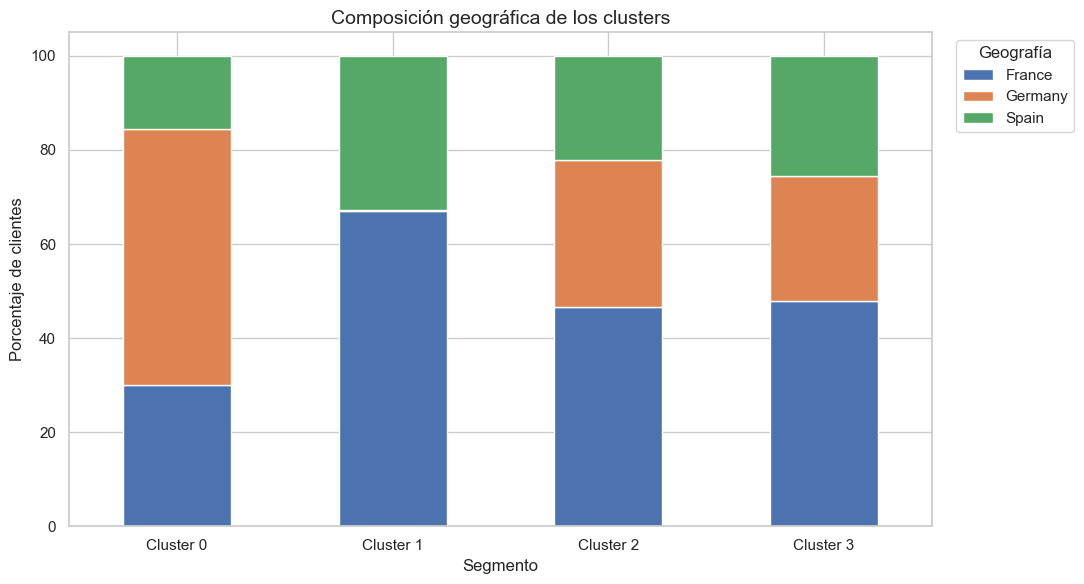

In [49]:
# Distribución geográfica por cluster
tabla_geografia_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title(
    "Composición geográfica de los clusters"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Porcentaje de clientes"
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Geografía",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

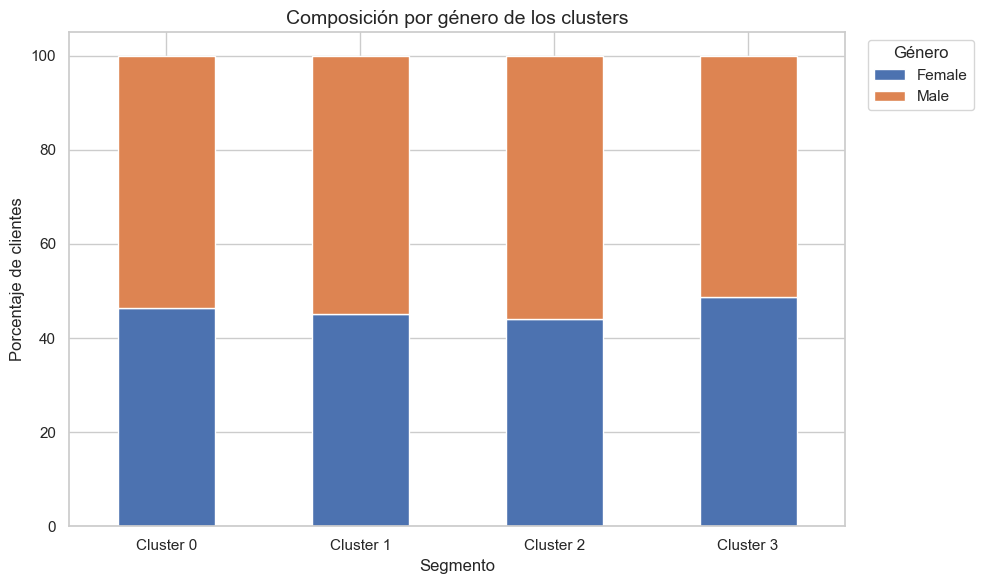

In [50]:
# Distribución por género dentro de cada cluster
tabla_genero_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title(
    "Composición por género de los clusters"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Porcentaje de clientes"
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Género",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

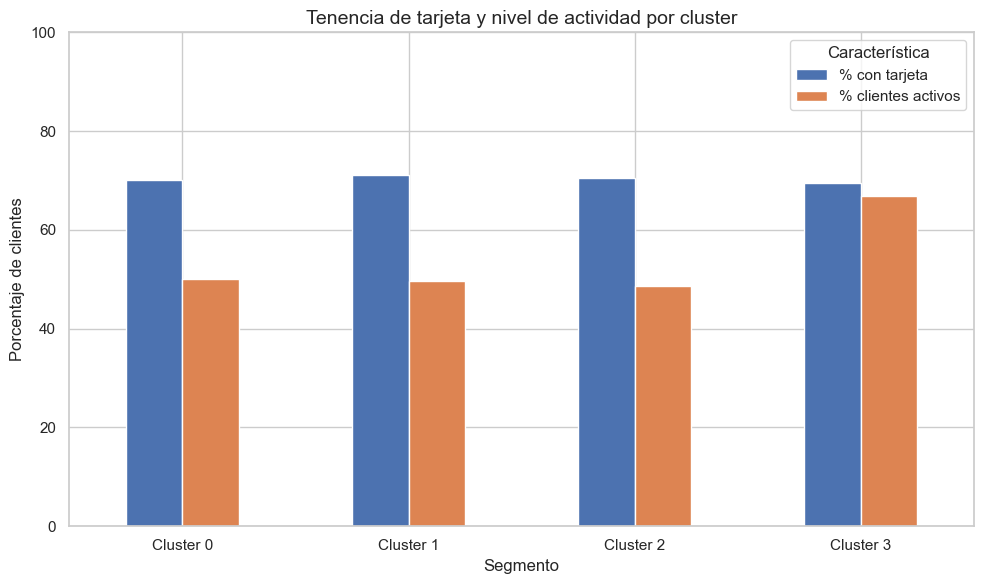

In [51]:
# Comparación de variables binarias
perfil_variables_binarias.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Tenencia de tarjeta y nivel de actividad por cluster"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Porcentaje de clientes"
)

plt.xticks(
    rotation=0
)

plt.ylim(
    0,
    100
)

plt.legend(
    title="Característica"
)

plt.tight_layout()

plt.show()

In [52]:
# Validaciones de consistencia
total_clientes_perfiles = (
    perfil_consolidado[
        "Cantidad de clientes"
    ]
    .sum()
)

suma_geografia = (
    tabla_geografia_cluster
    .sum(
        axis=1
    )
)

suma_genero = (
    tabla_genero_cluster
    .sum(
        axis=1
    )
)

print(
    "Validación de los perfiles"
)

print(
    "-" * 40
)

print(
    f"Clientes representados: "
    f"{total_clientes_perfiles}"
)

print(
    "\nSuma porcentual de geografía:"
)

display(
    suma_geografia
    .round(2)
)

print(
    "Suma porcentual de género:"
)

display(
    suma_genero
    .round(2)
)

Validación de los perfiles
----------------------------------------
Clientes representados: 10000

Suma porcentual de geografía:


Segmento
Cluster 0    100.00
Cluster 1     99.99
Cluster 2    100.00
Cluster 3    100.01
dtype: float64

Suma porcentual de género:


Segmento
Cluster 0    100.0
Cluster 1    100.0
Cluster 2    100.0
Cluster 3    100.0
dtype: float64

In [53]:
# Comprobaciones automáticas
assert (
    total_clientes_perfiles
    == len(
        df_segmentacion
    )
), (
    "La cantidad de clientes "
    "no coincide con el total."
)

assert np.allclose(
    suma_geografia,
    100,
    atol=0.05
), (
    "Las proporciones de geografía "
    "no suman aproximadamente 100%."
)

assert np.allclose(
    suma_genero,
    100,
    atol=0.05
), (
    "Las proporciones de género "
    "no suman aproximadamente 100%."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Interpretación de los perfiles identificados**

El análisis de los centroides y de las variables originales permitió identificar características diferenciadas para los cuatro segmentos.

Las principales variables asociadas a la formación de los clusters fueron:

- Edad.
- Saldo.
- Cantidad de productos.
- Geografía.
- Nivel de actividad.

Por el contrario, las variables `CreditScore`, `Tenure`, `EstimatedSalary`, `HasCrCard` y `Gender` presentaron diferencias reducidas entre los segmentos y no parecen constituir los principales factores de separación.

Los perfiles identificados fueron los siguientes:

###### Cluster 0 — Clientes multiproducto con saldo alto y predominio alemán

El Cluster 0 contiene 1.978 clientes, equivalentes al 19,78% de la base.

Presenta una edad promedio de 36,88 años, un saldo promedio de 121.746,10 y la mayor cantidad promedio de productos, con un valor de 2,13.

El 54,45% de sus integrantes pertenece a Alemania.

Este segmento se caracteriza principalmente por combinar saldos elevados con una relación multiproducto.

###### Cluster 1 — Clientes de saldo prácticamente nulo y predominio francés

El Cluster 1 contiene 3.269 clientes y representa el 32,69% de la base.

Presenta una edad promedio de 35,69 años y un saldo promedio de apenas 1.002,20.

Sin embargo, mantiene una cantidad promedio relativamente elevada de productos, con un valor de 1,82.

El 67,05% de los clientes pertenece a Francia.

La principal característica del segmento es la combinación de un saldo prácticamente nulo con la contratación de más de un producto.

###### Cluster 2 — Clientes con saldo alto y un único producto

El Cluster 2 es el segmento más grande y contiene 3.500 clientes, equivalentes al 35,00% de la base.

Presenta una edad promedio de 35,90 años, un saldo promedio de 120.929,25 y una cantidad promedio de productos igual a 1,00.

Aunque presenta saldos similares al Cluster 0, su nivel de vinculación mediante productos es considerablemente menor.

La composición geográfica es más diversa: 46,54% de los clientes pertenece a Francia, 31,26% a Alemania y 22,20% a España.

Este perfil podría representar una oportunidad potencial para estrategias de venta cruzada, aunque será necesario analizar también su relación con el churn.

###### Cluster 3 — Clientes senior y con mayor nivel de actividad

El Cluster 3 contiene 1.253 clientes y representa el 12,53% de la base.

Es el segmento de mayor edad, con un promedio de 59,02 años.

También presenta la mayor proporción de clientes activos, alcanzando el 66,88%.

Su saldo promedio es de 77.826,47 y la cantidad promedio de productos es de 1,30.

La edad constituye la característica más distintiva del segmento, con un centroide estandarizado de aproximadamente 1,92 desviaciones estándar por encima de la media general.

###### Conclusión

Los resultados muestran que K-Means logró generar cuatro perfiles con diferencias interpretables.

La estructura identificada se encuentra asociada principalmente a la edad, el saldo, la cantidad de productos, la geografía y el nivel de actividad.

Las variables `CreditScore`, `Tenure`, `EstimatedSalary`, `HasCrCard` y `Gender` presentan comportamientos relativamente similares entre los clusters.

La variable `Exited` no fue utilizada para construir ni interpretar inicialmente los segmentos.


#### 8. Análisis de la tasa de churn por segmento

La variable `Exited` no fue utilizada para construir los clusters.

Los segmentos fueron identificados exclusivamente a partir de características demográficas, financieras y de comportamiento.

Una vez finalizada la segmentación, la variable de churn se incorpora con fines descriptivos para responder las siguientes preguntas:

- ¿Todos los clusters presentan una tasa de abandono similar?
- ¿Existe algún segmento con una tasa superior al promedio general?
- ¿Qué perfiles podrían requerir mayor atención por parte del equipo de retención?
- ¿Existen segmentos que presenten una relación más estable con el banco?

Este análisis permite estudiar la asociación entre la pertenencia a un cluster y la tasa de churn.

In [54]:
# Verificación de la presencia de la variable Exited
print(
    "Variable 'Exited' disponible:"
)

print(
    "Exited"
    in df_segmentacion.columns
)

print(
    "\nValores identificados:"
)

print(
    sorted(
        df_segmentacion[
            "Exited"
        ]
        .unique()
    )
)

Variable 'Exited' disponible:
True

Valores identificados:
[np.int64(0), np.int64(1)]


##### 8.1 Tasa general de churn

Antes de analizar los segmentos, se calculará la tasa de abandono de toda la base.

Este valor funcionará como referencia para determinar si la tasa de cada cluster se encuentra por encima o por debajo del comportamiento general.

Debido a que `Exited` utiliza la siguiente codificación:

- `0`: cliente activo.
- `1`: cliente que abandonó.

La media de la variable representa directamente la proporción de clientes que abandonaron el banco.

In [55]:
# Cantidad total de clientes
total_clientes = (
    len(
        df_segmentacion
    )
)

# Cantidad de clientes que abandonaron
total_churn = int(
    df_segmentacion[
        "Exited"
    ]
    .sum()
)

# Cantidad de clientes activos
total_activos = (
    total_clientes
    - total_churn
)

# Tasa general de churn
tasa_churn_general = (
    df_segmentacion[
        "Exited"
    ]
    .mean()
)

# Conversión a porcentaje
tasa_churn_general_pct = (
    tasa_churn_general
    * 100
)

print(
    "Resumen general del churn"
)

print(
    "-" * 35
)

print(
    f"Cantidad total de clientes: "
    f"{total_clientes}"
)

print(
    f"Clientes activos: "
    f"{total_activos}"
)

print(
    f"Clientes que abandonaron: "
    f"{total_churn}"
)

print(
    f"Tasa general de churn: "
    f"{tasa_churn_general_pct:.2f}%"
)

Resumen general del churn
-----------------------------------
Cantidad total de clientes: 10000
Clientes activos: 7963
Clientes que abandonaron: 2037
Tasa general de churn: 20.37%


##### 8.2 Tasa de churn por cluster

Para cada segmento se calcularán los siguientes indicadores:

- Cantidad total de clientes.
- Cantidad de clientes activos.
- Cantidad de clientes que abandonaron.
- Tasa de churn.
- Diferencia respecto de la tasa general.
- Índice relativo de churn.
- Posición dentro del ranking de abandono.

La diferencia respecto del promedio se expresará en puntos porcentuales.

El índice relativo comparará la tasa del segmento con la tasa general:

- Valor mayor que `1`: churn superior al promedio.
- Valor cercano a `1`: churn similar al promedio.
- Valor menor que `1`: churn inferior al promedio.

In [56]:
# Cálculo de indicadores de churn por cluster
tabla_churn_cluster = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )
    .agg(
        Cantidad_clientes=(
            "Exited",
            "size"
        ),
        Clientes_que_abandonaron=(
            "Exited",
            "sum"
        )
    )
    .reset_index()
)

# Cantidad de clientes activos
tabla_churn_cluster[
    "Clientes_activos"
] = (
    tabla_churn_cluster[
        "Cantidad_clientes"
    ]
    - tabla_churn_cluster[
        "Clientes_que_abandonaron"
    ]
)

# Tasa de churn
tabla_churn_cluster[
    "Tasa_churn_pct"
] = (
    tabla_churn_cluster[
        "Clientes_que_abandonaron"
    ]
    .div(
        tabla_churn_cluster[
            "Cantidad_clientes"
        ]
    )
    .mul(100)
)

# Diferencia respecto
# de la tasa general
tabla_churn_cluster[
    "Diferencia_vs_general_pp"
] = (
    tabla_churn_cluster[
        "Tasa_churn_pct"
    ]
    - tasa_churn_general_pct
)

# Índice relativo
tabla_churn_cluster[
    "Indice_relativo"
] = (
    tabla_churn_cluster[
        "Tasa_churn_pct"
    ]
    .div(
        tasa_churn_general_pct
    )
)

# Ranking:
# 1 representa la mayor tasa de churn
tabla_churn_cluster[
    "Ranking_churn"
] = (
    tabla_churn_cluster[
        "Tasa_churn_pct"
    ]
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
)

# Etiqueta descriptiva
tabla_churn_cluster[
    "Segmento"
] = (
    "Cluster "
    + tabla_churn_cluster[
        "Cluster_KMeans"
    ]
    .astype(str)
)

In [57]:
# Selección y orden de las columnas
tabla_churn_visual = (
    tabla_churn_cluster[
        [
            "Cluster_KMeans",
            "Segmento",
            "Cantidad_clientes",
            "Clientes_activos",
            "Clientes_que_abandonaron",
            "Tasa_churn_pct",
            "Diferencia_vs_general_pp",
            "Indice_relativo",
            "Ranking_churn"
        ]
    ]
    .copy()
)

# Nombres más descriptivos
tabla_churn_visual = (
    tabla_churn_visual
    .rename(
        columns={
            "Cluster_KMeans": "Cluster",
            "Cantidad_clientes": (
                "Cantidad de clientes"
            ),
            "Clientes_activos": (
                "Clientes que permanecieron"
            ),
            "Clientes_que_abandonaron": (
                "Clientes que abandonaron"
            ),
            "Tasa_churn_pct": (
                "Tasa de churn (%)"
            ),
            "Diferencia_vs_general_pp": (
                "Diferencia vs. general (p.p.)"
            ),
            "Indice_relativo": (
                "Índice relativo"
            ),
            "Ranking_churn": (
                "Ranking de churn"
            )
        }
    )
)

# Redondeo
columnas_decimales = [
    "Tasa de churn (%)",
    "Diferencia vs. general (p.p.)",
    "Índice relativo"
]

tabla_churn_visual[
    columnas_decimales
] = (
    tabla_churn_visual[
        columnas_decimales
    ]
    .round(2)
)

display(
    tabla_churn_visual
)

,Cluster,Segmento,Cantidad de clientes,Clientes que permanecieron,Clientes que abandonaron,Tasa de churn (%),Diferencia vs. general (p.p.),Índice relativo,Ranking de churn
0,0,Cluster 0,1978,1582,396,20.02,-0.35,0.98,3
1,1,Cluster 1,3269,2922,347,10.61,-9.76,0.52,4
2,2,Cluster 2,3500,2762,738,21.09,0.72,1.04,2
3,3,Cluster 3,1253,697,556,44.37,24.00,2.18,1


**Interpretación de los indicadores**

La tasa de churn permite conocer qué proporción de clientes abandonó el banco dentro de cada segmento.

La diferencia respecto de la tasa general se expresa en puntos porcentuales.

Por ejemplo:

- Una diferencia de `+5` indica que el segmento presenta una tasa de churn cinco puntos porcentuales superior al promedio general.

- Una diferencia de `-5` indica que el segmento presenta una tasa cinco puntos porcentuales inferior al promedio.

El índice relativo compara la tasa del cluster con la tasa general.

Por ejemplo:

- Un índice de `1,50` indica que la tasa del segmento es un 50% mayor que la tasa general.

- Un índice de `0,75` indica que la tasa del segmento equivale al 75% de la tasa general.

Estos indicadores permiten comparar el nivel de abandono entre segmentos con diferentes cantidades de clientes.

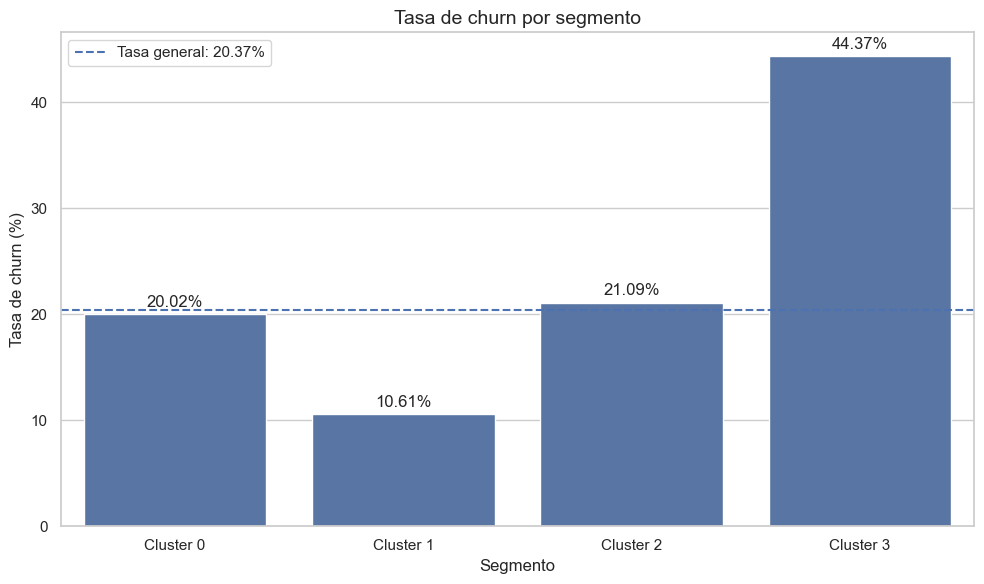

In [58]:
# Gráfico de tasa de churn por segmento
plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    data=tabla_churn_visual,
    x="Segmento",
    y="Tasa de churn (%)"
)

# Etiquetas porcentuales
for contenedor in ax.containers:

    etiquetas = [
        f"{valor:.2f}%"
        for valor
        in tabla_churn_visual[
            "Tasa de churn (%)"
        ]
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        padding=3
    )

# Línea de referencia
plt.axhline(
    y=tasa_churn_general_pct,
    linestyle="--",
    label=(
        "Tasa general: "
        f"{tasa_churn_general_pct:.2f}%"
    )
)

plt.title(
    "Tasa de churn por segmento"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Tasa de churn (%)"
)

plt.legend()

plt.tight_layout()

plt.show()

##### 8.3 Diferencia respecto de la tasa general

La siguiente visualización mostrará la diferencia entre la tasa de churn de cada segmento y la tasa general de la base.

La línea horizontal ubicada en cero representa el promedio general.

- Valores positivos: churn superior al promedio.
- Valores negativos: churn inferior al promedio.

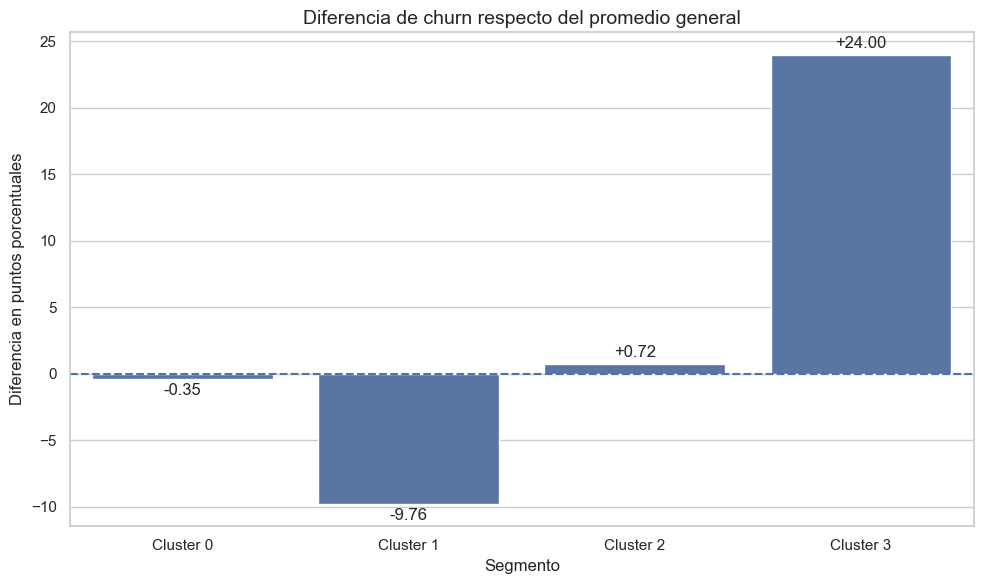

In [59]:
# Diferencia respecto de la tasa general
plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    data=tabla_churn_visual,
    x="Segmento",
    y="Diferencia vs. general (p.p.)"
)

# Etiquetas sobre las barras
for contenedor in ax.containers:

    etiquetas = [
        f"{valor:+.2f}"
        for valor
        in tabla_churn_visual[
            "Diferencia vs. general (p.p.)"
        ]
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        padding=3
    )

# Línea de referencia
plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Diferencia de churn respecto del promedio general"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Diferencia en puntos porcentuales"
)

plt.tight_layout()

plt.show()

In [60]:
# Ranking de mayor a menor tasa de churn
ranking_churn = (
    tabla_churn_visual
    .sort_values(
        by="Tasa de churn (%)",
        ascending=False
    )
    [
        [
            "Ranking de churn",
            "Segmento",
            "Cantidad de clientes",
            "Clientes que abandonaron",
            "Tasa de churn (%)",
            "Diferencia vs. general (p.p.)",
            "Índice relativo"
        ]
    ]
    .reset_index(
        drop=True
    )
)

display(
    ranking_churn
)

,Ranking de churn,Segmento,Cantidad de clientes,Clientes que abandonaron,Tasa de churn (%),Diferencia vs. general (p.p.),Índice relativo
0,1,Cluster 3,1253,556,44.37,24.00,2.18
1,2,Cluster 2,3500,738,21.09,0.72,1.04
2,3,Cluster 0,1978,396,20.02,-0.35,0.98
3,4,Cluster 1,3269,347,10.61,-9.76,0.52


##### 8.4 Validación de los indicadores

Se verificará que:

- La suma de clientes de los clusters sea igual a 10.000.
- La suma de clientes que abandonaron coincida con el total general.
- La suma de clientes activos coincida con el total general.
- La tasa ponderada de los clusters sea igual a la tasa de churn de toda la base.

In [61]:
# Totales obtenidos desde la tabla por cluster
clientes_tabla = (
    tabla_churn_cluster[
        "Cantidad_clientes"
    ]
    .sum()
)

churn_tabla = (
    tabla_churn_cluster[
        "Clientes_que_abandonaron"
    ]
    .sum()
)

activos_tabla = (
    tabla_churn_cluster[
        "Clientes_activos"
    ]
    .sum()
)

# Tasa ponderada
tasa_ponderada = (
    churn_tabla
    / clientes_tabla
    * 100
)

print(
    "Validación del análisis de churn"
)

print(
    "-" * 40
)

print(
    f"Clientes representados: "
    f"{clientes_tabla}"
)

print(
    f"Clientes que permaneciero: "
    f"{activos_tabla}"
)

print(
    f"Clientes que abandonaron: "
    f"{churn_tabla}"
)

print(
    f"Tasa ponderada: "
    f"{tasa_ponderada:.2f}%"
)

print(
    f"Tasa general: "
    f"{tasa_churn_general_pct:.2f}%"
)

Validación del análisis de churn
----------------------------------------
Clientes representados: 10000
Clientes que permaneciero: 7963
Clientes que abandonaron: 2037
Tasa ponderada: 20.37%
Tasa general: 20.37%


In [62]:
# Comprobaciones automáticas
assert (
    clientes_tabla
    == total_clientes
), (
    "La cantidad total "
    "de clientes no coincide."
)

assert (
    churn_tabla
    == total_churn
), (
    "La cantidad de clientes "
    "que abandonaron no coincide."
)

assert (
    activos_tabla
    == total_activos
), (
    "La cantidad de clientes "
    "activos no coincide."
)

assert np.isclose(
    tasa_ponderada,
    tasa_churn_general_pct,
    atol=0.01
), (
    "La tasa ponderada "
    "no coincide con la general."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Interpretación de la tasa de churn por segmento**

La tasa general de churn de FinanceGuard es del `20,37%`.

El análisis posterior a la segmentación permitió identificar diferencias importantes entre los cuatro clusters.

La variable `Exited` no fue utilizada para formar los grupos ni para seleccionar el número de clusters. Fue incorporada únicamente después de finalizar la segmentación.

###### Cluster 3 — Segmento de mayor riesgo relativo

El Cluster 3 presenta la tasa de churn más elevada:

- Tasa de churn: `44,37%`.
- Diferencia respecto del promedio: `+24,00` puntos porcentuales.
- Índice relativo: `2,18`.
- Clientes que abandonaron: `556`.

La tasa de abandono es más del doble de la tasa general.

Este segmento se caracteriza por una edad promedio de 59,02 años, una cantidad promedio de 1,30 productos y el mayor porcentaje de miembros activos según `IsActiveMember`.

El hecho de presentar simultáneamente una elevada proporción de miembros activos y la mayor tasa de churn indica que la actividad registrada no garantiza por sí sola la permanencia del cliente.

Debido a su elevada tasa de abandono, el Cluster 3 constituye el segmento de mayor prioridad relativa para acciones de retención.

###### Cluster 2 — Mayor volumen absoluto de abandono

El Cluster 2 presenta:

- Tasa de churn: `21,09%`.
- Diferencia respecto del promedio: `+0,72` puntos porcentuales.
- Índice relativo: `1,04`.
- Clientes que abandonaron: `738`.

Su tasa se encuentra ligeramente por encima del promedio general.

Sin embargo, al ser el segmento más grande, concentra la mayor cantidad absoluta de clientes que abandonaron.

El perfil se caracteriza por presentar saldos elevados y una cantidad promedio de productos igual a uno.

Por lo tanto, este segmento resulta relevante principalmente por el volumen total de bajas y podría representar una oportunidad para estrategias de vinculación y venta cruzada.

###### Cluster 0 — Comportamiento cercano al promedio

El Cluster 0 presenta:

- Tasa de churn: `20,02%`.
- Diferencia respecto del promedio: `-0,35` puntos porcentuales.
- Índice relativo: `0,98`.
- Clientes que abandonaron: `396`.

Su tasa de abandono es prácticamente igual a la tasa general.

El segmento combina saldos elevados con la mayor cantidad promedio de productos y una fuerte presencia de clientes de Alemania.

No presenta un nivel de riesgo particularmente alto ni bajo, por lo que puede considerarse un segmento de prioridad intermedia.

###### Cluster 1 — Segmento con menor tasa de abandono

El Cluster 1 presenta:

- Tasa de churn: `10,61%`.
- Diferencia respecto del promedio: `-9,76` puntos porcentuales.
- Índice relativo: `0,52`.
- Clientes que abandonaron: `347`.

Es el segmento con menor tasa de churn.

Su nivel de abandono equivale aproximadamente a la mitad de la tasa general.

El perfil se caracteriza por un saldo prácticamente nulo, una cantidad promedio de 1,82 productos y una fuerte concentración de clientes de Francia.

El resultado demuestra que un saldo bajo no implica necesariamente una mayor tasa de abandono.

Sin embargo, no puede concluirse que sea el segmento más rentable, ya que el dataset no contiene información sobre ingresos, costos o rentabilidad.

###### Prioridades identificadas

Los resultados permiten distinguir dos tipos de prioridad:

- El Cluster 3 representa la mayor prioridad por intensidad del riesgo, debido a su tasa de churn del 44,37%.

- El Cluster 2 representa una prioridad por volumen, ya que concentra 738 abandonos, la mayor cantidad absoluta entre los segmentos.

El Cluster 0 presenta un comportamiento cercano al promedio general.

El Cluster 1 presenta la menor tasa de abandono y constituye el segmento de menor prioridad relativa desde la perspectiva del churn.

Las diferencias observadas representan asociaciones descriptivas y no demuestran que pertenecer a un determinado cluster cause el abandono.

#### 9. Implementación y evaluación de DBSCAN

DBSCAN, cuyo nombre proviene de *Density-Based Spatial Clustering of Applications with Noise*, es un algoritmo de clustering basado en densidad.

A diferencia de K-Means:

- No requiere establecer previamente la cantidad de clusters.
- No utiliza centroides.
- Puede detectar grupos con formas irregulares.
- Permite identificar observaciones ubicadas en regiones de baja densidad y clasificarlas como ruido.

DBSCAN utiliza dos hiperparámetros principales:

- `eps`: radio máximo utilizado para definir el vecindario de una observación.
- `min_samples`: cantidad mínima de observaciones necesarias dentro del radio definido para considerar que una región posee suficiente densidad.

El algoritmo clasifica las observaciones en tres categorías:

###### Puntos centrales o *core points*

Poseen al menos la cantidad de vecinos establecida mediante `min_samples` dentro de una distancia máxima igual a `eps`.

Estos puntos forman las regiones densas de los clusters.

###### Puntos de borde o *border points*

No cumplen individualmente la condición de densidad, pero se encuentran dentro del vecindario de un punto central.

Por lo tanto, son incorporados a un cluster existente.

###### Puntos de ruido o *noise points*

No son puntos centrales ni se encuentran conectados con una región suficientemente densa.

DBSCAN utiliza la etiqueta `-1` para identificar estas observaciones.

La clasificación como ruido no implica necesariamente que exista un error en el registro. Puede representar un cliente con características poco frecuentes dentro de la base.

##### 9.1 Datos utilizados por DBSCAN

DBSCAN se aplicará sobre la misma matriz transformada utilizada por K-Means:

`X_cluster`

La matriz contiene:

- Variables numéricas estandarizadas.
- Variables categóricas transformadas mediante One-Hot Encoding.
- Variables binarias expresadas como `0` y `1`.

El escalamiento es fundamental porque DBSCAN utiliza distancias para identificar regiones densas.

La variable `Exited` continuará excluida del proceso.

El churn no será utilizado para seleccionar `eps`, ajustar `min_samples` ni definir los clusters.

In [63]:
# Verificación de la matriz utilizada por DBSCAN

print(
    "Dimensiones de la matriz:"
)

print(
    X_cluster.shape
)

print(
    "\nCantidad de valores faltantes:"
)

print(
    X_cluster
    .isna()
    .sum()
    .sum()
)

print(
    "\nVariable 'Exited' incluida:"
)

print(
    "Exited"
    in X_cluster.columns
)

Dimensiones de la matriz:
(10000, 13)

Cantidad de valores faltantes:
0

Variable 'Exited' incluida:
False


##### 9.2 Definición inicial de `min_samples`

El parámetro `min_samples` determina la cantidad mínima de observaciones que debe contener un vecindario para ser considerado una región densa.

No existe un valor universalmente correcto.

Como criterio inicial se utilizará una regla heurística equivalente a dos veces la cantidad de características presentes en la matriz transformada.

La matriz contiene 13 características:

`min_samples = 2 × 13 = 26`

Esta regla constituye un punto de partida y no una solución obligatoria.

El valor deberá interpretarse conjuntamente con los resultados obtenidos y con el comportamiento del parámetro `eps`.

In [64]:
# Cantidad de características
cantidad_caracteristicas = (
    X_cluster
    .shape[1]
)

# Valor inicial de min_samples
MIN_SAMPLES_INICIAL = (
    2
    * cantidad_caracteristicas
)

print(
    f"Cantidad de características: "
    f"{cantidad_caracteristicas}"
)

print(
    f"min_samples inicial: "
    f"{MIN_SAMPLES_INICIAL}"
)

Cantidad de características: 13
min_samples inicial: 26


##### 9.3 Curva de distancias para orientar la selección de `eps`

La selección de `eps` puede orientarse mediante una curva de distancias al vecino número `min_samples`.

El procedimiento consiste en:

1. Calcular la distancia desde cada cliente hasta su vecino número 26.

2. Ordenar las distancias de menor a mayor.

3. Representarlas gráficamente.

4. Buscar una zona donde la pendiente comience a aumentar con mayor intensidad.

Ese cambio puede funcionar como referencia para seleccionar un valor inicial de `eps`.

La curva no siempre presenta un codo claramente definido.

La ausencia de un cambio marcado también puede indicar que la densidad de los datos varía de manera gradual.

In [65]:
# Modelo de vecinos más cercanos
modelo_vecinos = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_INICIAL,
    n_jobs=-1
)

# Ajuste sobre la matriz transformada
modelo_vecinos.fit(
    X_cluster
)

# Cálculo de distancias
distancias_vecinos, _ = (
    modelo_vecinos
    .kneighbors(
        X_cluster
    )
)

# Distancia correspondiente
# al vecino número min_samples
distancias_k = (
    distancias_vecinos[
        :,
        -1
    ]
)

# Ordenamiento ascendente
distancias_k_ordenadas = (
    np.sort(
        distancias_k
    )
)

print(
    "Distancias calculadas correctamente."
)

print(
    f"Cantidad de observaciones: "
    f"{len(distancias_k_ordenadas)}"
)

Distancias calculadas correctamente.
Cantidad de observaciones: 10000


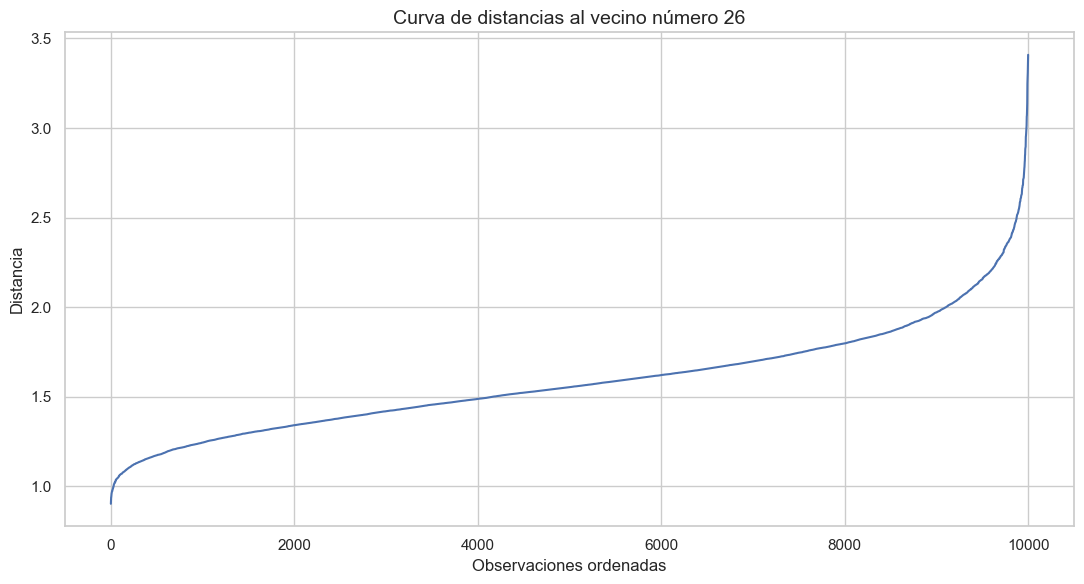

In [66]:
# Curva de distancias al vecino número min_samples

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    distancias_k_ordenadas
)

plt.title(
    "Curva de distancias al vecino "
    f"número {MIN_SAMPLES_INICIAL}"
)

plt.xlabel(
    "Observaciones ordenadas"
)

plt.ylabel(
    "Distancia"
)

plt.tight_layout()

plt.show()

##### 9.4 Cuantiles de las distancias

Debido a que la identificación visual del punto de cambio puede ser subjetiva, se calcularán distintos cuantiles de la distribución de distancias.

Los valores obtenidos se utilizarán como candidatos iniciales para `eps`.

Los cuantiles más bajos tenderán a generar una definición más estricta de densidad y posiblemente una mayor cantidad de ruido.

Los cuantiles más altos permitirán vecindarios más amplios y podrían unir una mayor cantidad de observaciones.

In [67]:
# Cuantiles evaluados
cuantiles_eps = [
    0.70,
    0.80,
    0.85,
    0.90,
    0.93,
    0.95,
    0.97,
    0.99
]

# Cálculo de valores candidatos
valores_eps_candidatos = (
    np.quantile(
        distancias_k_ordenadas,
        cuantiles_eps
    )
)

# Tabla de referencia
tabla_cuantiles_eps = pd.DataFrame({
    "Cuantil": cuantiles_eps,
    "Percentil": [
        f"{int(cuantil * 100)}%"
        for cuantil
        in cuantiles_eps
    ],
    "Valor candidato de eps": (
        valores_eps_candidatos
    )
})

# Redondeo para visualización
tabla_cuantiles_eps[
    "Valor candidato de eps"
] = (
    tabla_cuantiles_eps[
        "Valor candidato de eps"
    ]
    .round(3)
)

display(
    tabla_cuantiles_eps
)

,Cuantil,Percentil,Valor candidato de eps
0,0.70,70%,1.698
1,0.80,80%,1.798
2,0.85,85%,1.864
3,0.90,90%,1.971
4,0.93,93%,2.071
5,0.95,95%,2.156
6,0.97,97%,2.284
7,0.99,99%,2.550


##### 9.5 Evaluación exploratoria de configuraciones

Se entrenará un modelo DBSCAN para cada valor candidato de `eps`.

Para cada configuración se calcularán:

- Cantidad de clusters identificados.
- Cantidad de observaciones clasificadas como ruido.
- Porcentaje de ruido.
- Cantidad de clientes asignados a clusters.
- Tamaño del cluster más grande.
- Porcentaje de la base representado por el cluster más grande.
- Coeficiente de silueta cuando la estructura permita calcularlo.

La etiqueta `-1` no será considerada un cluster.

El coeficiente de silueta se calculará únicamente cuando existan al menos dos clusters válidos y se excluirán las observaciones clasificadas como ruido.

La selección definitiva no dependerá de una única métrica.

También se considerarán:

- La proporción de ruido.
- El tamaño de los clusters.
- La estabilidad de la estructura.
- La posibilidad de interpretar los resultados.

In [68]:
# Valores únicos de eps utilizados en la exploración

valores_eps_explorados = (
    np.unique(
        np.round(
            valores_eps_candidatos,
            3
        )
    )
)

# Lista para almacenar resultados
resultados_dbscan = []

# Evaluación de configuraciones
for eps_actual in valores_eps_explorados:

    # Creación del modelo
    modelo_actual = DBSCAN(
        eps=float(
            eps_actual
        ),
        min_samples=(
            MIN_SAMPLES_INICIAL
        ),
        n_jobs=-1
    )

    # Entrenamiento
    etiquetas_actuales = (
        modelo_actual
        .fit_predict(
            X_cluster
        )
    )

    # Identificación de ruido
    mascara_ruido = (
        etiquetas_actuales
        == -1
    )

    # Cantidad de observaciones
    # clasificadas como ruido
    cantidad_ruido = int(
        mascara_ruido
        .sum()
    )

    # Cantidad de clusters válidos
    etiquetas_validas = (
        set(
            etiquetas_actuales
        )
        - {-1}
    )

    cantidad_clusters = (
        len(
            etiquetas_validas
        )
    )

    # Clientes asignados
    # a algún cluster
    clientes_asignados = (
        len(
            etiquetas_actuales
        )
        - cantidad_ruido
    )

    # Tamaño del cluster mayor
    conteos_clusters = (
        pd.Series(
            etiquetas_actuales[
                ~mascara_ruido
            ]
        )
        .value_counts()
    )

    if (
        len(
            conteos_clusters
        )
        > 0
    ):

        tamano_cluster_mayor = int(
            conteos_clusters
            .max()
        )

    else:

        tamano_cluster_mayor = 0

    # Coeficiente de silueta
    silueta_actual = np.nan

    if (
        cantidad_clusters
        >= 2
        and clientes_asignados
        > cantidad_clusters
    ):

        X_sin_ruido = (
            X_cluster
            .loc[
                ~mascara_ruido
            ]
        )

        etiquetas_sin_ruido = (
            etiquetas_actuales[
                ~mascara_ruido
            ]
        )

        silueta_actual = (
            silhouette_score(
                X_sin_ruido,
                etiquetas_sin_ruido,
                sample_size=min(
                    3000,
                    clientes_asignados
                ),
                random_state=(
                    RANDOM_STATE
                )
            )
        )

    # Registro de resultados
    resultados_dbscan.append({
        "eps": float(
            eps_actual
        ),
        "min_samples": (
            MIN_SAMPLES_INICIAL
        ),
        "Cantidad de clusters": (
            cantidad_clusters
        ),
        "Clientes asignados": (
            clientes_asignados
        ),
        "Cantidad de ruido": (
            cantidad_ruido
        ),
        "Porcentaje de ruido": (
            cantidad_ruido
            / len(
                etiquetas_actuales
            )
            * 100
        ),
        "Tamaño del cluster mayor": (
            tamano_cluster_mayor
        ),
        "% de la base en cluster mayor": (
            tamano_cluster_mayor
            / len(
                etiquetas_actuales
            )
            * 100
        ),
        "Coeficiente de silueta": (
            silueta_actual
        )
    })

print(
    "Evaluación exploratoria "
    "de DBSCAN completada."
)

Evaluación exploratoria de DBSCAN completada.


In [69]:
# Conversión a DataFrame
tabla_resultados_dbscan = (
    pd.DataFrame(
        resultados_dbscan
    )
)

# Copia para visualización
tabla_dbscan_visual = (
    tabla_resultados_dbscan
    .copy()
)

# Redondeo
columnas_redondear_dbscan = [
    "eps",
    "Porcentaje de ruido",
    "% de la base en cluster mayor",
    "Coeficiente de silueta"
]

tabla_dbscan_visual[
    columnas_redondear_dbscan
] = (
    tabla_dbscan_visual[
        columnas_redondear_dbscan
    ]
    .round(3)
)

display(
    tabla_dbscan_visual
)

,eps,min_samples,Cantidad de clusters,Clientes asignados,Cantidad de ruido,Porcentaje de ruido,Tamaño del cluster mayor,% de la base en cluster mayor,Coeficiente de silueta
0,1.698,26,2,9300,700,7.00,4894,48.94,0.128
1,1.798,26,1,9536,464,4.64,9536,95.36,NaN
2,1.864,26,1,9673,327,3.27,9673,96.73,NaN
3,1.971,26,1,9810,190,1.90,9810,98.10,NaN
4,2.071,26,1,9892,108,1.08,9892,98.92,NaN
5,2.156,26,1,9924,76,0.76,9924,99.24,NaN
6,2.284,26,1,9965,35,0.35,9965,99.65,NaN
7,2.550,26,1,9991,9,0.09,9991,99.91,NaN


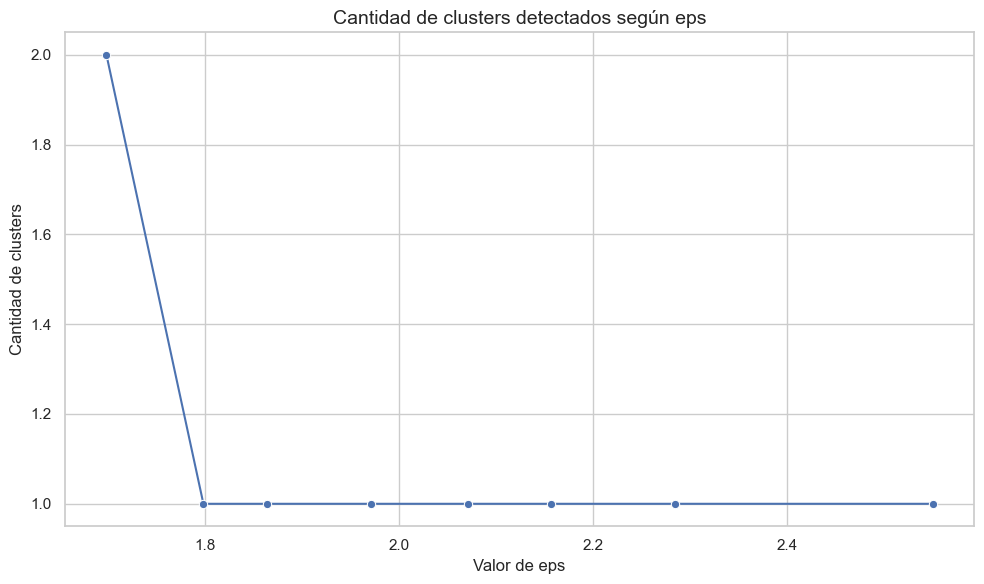

In [70]:
# Cantidad de clusters según el valor de eps

plt.figure(
    figsize=(10, 6)
)

sns.lineplot(
    data=tabla_resultados_dbscan,
    x="eps",
    y="Cantidad de clusters",
    marker="o"
)

plt.title(
    "Cantidad de clusters detectados según eps"
)

plt.xlabel(
    "Valor de eps"
)

plt.ylabel(
    "Cantidad de clusters"
)

plt.tight_layout()

plt.show()

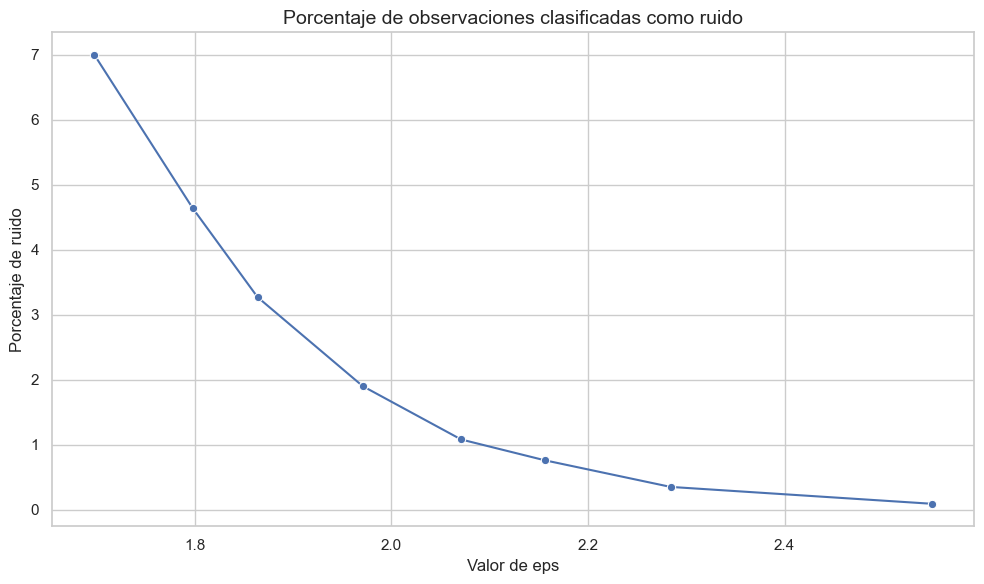

In [71]:
# Porcentaje de ruido según el valor de eps

plt.figure(
    figsize=(10, 6)
)

sns.lineplot(
    data=tabla_resultados_dbscan,
    x="eps",
    y="Porcentaje de ruido",
    marker="o"
)

plt.title(
    "Porcentaje de observaciones clasificadas como ruido"
)

plt.xlabel(
    "Valor de eps"
)

plt.ylabel(
    "Porcentaje de ruido"
)

plt.tight_layout()

plt.show()

**Selección de la configuración definitiva de DBSCAN**

La curva de distancias al vecino número 26 mostró un aumento gradual durante la mayor parte del recorrido y un crecimiento más pronunciado hacia el extremo superior.

No se identificó un único punto de cambio completamente definido, lo que sugiere una estructura de densidad relativamente continua.

La evaluación exploratoria mostró que la configuración:

- `eps = 1,698`
- `min_samples = 26`

fue la única alternativa analizada que identificó más de un cluster.

Los resultados fueron:

- Cantidad de clusters: 2.
- Clientes asignados a clusters: 9.300.
- Observaciones clasificadas como ruido: 700.
- Porcentaje de ruido: 7,00%.
- Tamaño del cluster principal: 4.894 clientes.
- Participación del cluster principal: 48,94%.
- Coeficiente de silueta: 0,128.

Los dos clusters presentan tamaños relativamente equilibrados y la proporción de ruido es moderada.

Al aumentar `eps` a 1,798, DBSCAN agrupó al 95,36% de la base dentro de un único cluster.

Los valores superiores mantuvieron una única estructura principal y redujeron progresivamente la cantidad de observaciones clasificadas como ruido.

Este comportamiento indica que gran parte de los clientes se encuentra conectada dentro de una estructura de densidad relativamente continua.

Por lo tanto, se seleccionaron los siguientes parámetros:

**EPS_FINAL = 1,698**

**MIN_SAMPLES_FINAL = 26**

La configuración permite conservar dos regiones diferenciadas y analizar simultáneamente las observaciones ubicadas en zonas de menor densidad.

Las observaciones clasificadas como ruido no serán interpretadas automáticamente como errores o registros inválidos. Representan clientes que, bajo esta configuración, no pertenecen a una región suficientemente densa.

##### 9.6 Entrenamiento del modelo DBSCAN definitivo

Luego de analizar la curva de distancias y comparar diferentes configuraciones, se seleccionaron los siguientes parámetros:

- `eps = 1,698`
- `min_samples = 26`

El modelo definitivo será entrenado utilizando la totalidad de los 10.000 clientes.

DBSCAN asignará:

- Valores iguales o superiores a `0` para identificar los clusters.
- La etiqueta `-1` para representar observaciones clasificadas como ruido.

La numeración de los clusters es arbitraria y no representa un orden de valor, importancia o nivel de riesgo.

In [72]:
# Parámetros definitivos
EPS_FINAL = 1.698
MIN_SAMPLES_FINAL = 26

# Creación del modelo definitivo
modelo_dbscan_final = DBSCAN(
    eps=EPS_FINAL,
    min_samples=MIN_SAMPLES_FINAL,
    n_jobs=-1
)

# Entrenamiento y generación de etiquetas
etiquetas_dbscan = (
    modelo_dbscan_final
    .fit_predict(
        X_cluster
    )
)

print(
    "Modelo DBSCAN definitivo "
    "entrenado correctamente."
)

print(
    f"Cantidad de etiquetas generadas: "
    f"{len(etiquetas_dbscan)}"
)

Modelo DBSCAN definitivo entrenado correctamente.
Cantidad de etiquetas generadas: 10000


##### 9.7 Clasificación de las observaciones según DBSCAN

DBSCAN diferencia tres tipos de observaciones:

###### Puntos centrales

Son observaciones que poseen suficiente cantidad de vecinos dentro del radio definido mediante `eps`.

Representan las zonas de mayor densidad.

###### Puntos de borde

No cumplen individualmente la condición necesaria para ser puntos centrales, pero se encuentran conectados con la región de un punto central.

Forman parte de un cluster.

###### Puntos de ruido

No pertenecen a una región suficientemente densa.

DBSCAN utiliza la etiqueta `-1` para identificarlos.

La clasificación como ruido no implica necesariamente que el registro sea erróneo o que deba eliminarse.

In [73]:
# Máscara inicial para puntos centrales
mascara_core = np.zeros(
    len(
        etiquetas_dbscan
    ),
    dtype=bool
)

# Índices identificados como puntos centrales
indices_core = (
    modelo_dbscan_final
    .core_sample_indices_
)

# Marcación de puntos centrales
mascara_core[
    indices_core
] = True

# Identificación de ruido
mascara_ruido_dbscan = (
    etiquetas_dbscan
    == -1
)

# Identificación de puntos de borde
mascara_borde = (
    ~mascara_core
    & ~mascara_ruido_dbscan
)

print(
    "Clasificación de puntos completada."
)

Clasificación de puntos completada.


In [74]:
# Tabla de tipos de puntos
tabla_tipos_dbscan = pd.DataFrame({
    "Tipo de punto": [
        "Punto central",
        "Punto de borde",
        "Ruido"
    ],
    "Cantidad de clientes": [
        int(
            mascara_core.sum()
        ),
        int(
            mascara_borde.sum()
        ),
        int(
            mascara_ruido_dbscan.sum()
        )
    ]
})

# Porcentaje sobre la base
tabla_tipos_dbscan[
    "Porcentaje"
] = (
    tabla_tipos_dbscan[
        "Cantidad de clientes"
    ]
    .div(
        len(
            etiquetas_dbscan
        )
    )
    .mul(100)
    .round(2)
)

display(
    tabla_tipos_dbscan
)

,Tipo de punto,Cantidad de clientes,Porcentaje
0,Punto central,6999,69.99
1,Punto de borde,2301,23.01
2,Ruido,700,7.00


In [75]:
# Cantidad de clientes por etiqueta de DBSCAN
tabla_distribucion_dbscan = (
    pd.Series(
        etiquetas_dbscan,
        name="Cluster"
    )
    .value_counts()
    .sort_index()
    .rename_axis(
        "Cluster"
    )
    .reset_index(
        name="Cantidad de clientes"
    )
)

# Etiqueta descriptiva
tabla_distribucion_dbscan[
    "Segmento"
] = (
    tabla_distribucion_dbscan[
        "Cluster"
    ]
    .apply(
        lambda valor: (
            "Ruido"
            if valor == -1
            else f"Cluster {valor}"
        )
    )
)

# Porcentaje de la base
tabla_distribucion_dbscan[
    "Porcentaje"
] = (
    tabla_distribucion_dbscan[
        "Cantidad de clientes"
    ]
    .div(
        len(
            etiquetas_dbscan
        )
    )
    .mul(100)
    .round(2)
)

# Orden de columnas
tabla_distribucion_dbscan = (
    tabla_distribucion_dbscan[
        [
            "Cluster",
            "Segmento",
            "Cantidad de clientes",
            "Porcentaje"
        ]
    ]
)

display(
    tabla_distribucion_dbscan
)

,Cluster,Segmento,Cantidad de clientes,Porcentaje
0,-1,Ruido,700,7.00
1,0,Cluster 0,4894,48.94
2,1,Cluster 1,4406,44.06


##### 9.8 Evaluación global de DBSCAN

La evaluación incluirá:

- Cantidad de clusters válidos.
- Cantidad de clientes asignados.
- Cantidad y porcentaje de ruido.
- Cantidad de puntos centrales.
- Cantidad de puntos de borde.
- Coeficiente de silueta.

Las observaciones clasificadas como ruido serán excluidas del cálculo del coeficiente de silueta.

Esta decisión permite evaluar la cohesión y separación de los grupos identificados por densidad.

In [76]:
# Etiquetas válidas
clusters_validos_dbscan = (
    set(
        etiquetas_dbscan
    )
    - {-1}
)

# Cantidad de clusters
cantidad_clusters_dbscan = (
    len(
        clusters_validos_dbscan
    )
)

# Cantidad de ruido
cantidad_ruido_dbscan = int(
    mascara_ruido_dbscan
    .sum()
)

# Cantidad asignada
clientes_asignados_dbscan = (
    len(
        etiquetas_dbscan
    )
    - cantidad_ruido_dbscan
)

# Coeficiente de silueta
silueta_dbscan_final = np.nan

if cantidad_clusters_dbscan >= 2:

    X_dbscan_sin_ruido = (
        X_cluster
        .loc[
            ~mascara_ruido_dbscan
        ]
    )

    etiquetas_dbscan_sin_ruido = (
        etiquetas_dbscan[
            ~mascara_ruido_dbscan
        ]
    )

    silueta_dbscan_final = (
        silhouette_score(
            X_dbscan_sin_ruido,
            etiquetas_dbscan_sin_ruido,
            sample_size=min(
                3000,
                clientes_asignados_dbscan
            ),
            random_state=RANDOM_STATE
        )
    )

# Tabla resumen
resumen_dbscan_final = pd.DataFrame({
    "Indicador": [
        "eps",
        "min_samples",
        "Cantidad de clusters",
        "Clientes asignados",
        "Cantidad de ruido",
        "Porcentaje de ruido",
        "Puntos centrales",
        "Puntos de borde",
        "Coeficiente de silueta"
    ],
    "Resultado": [
        EPS_FINAL,
        MIN_SAMPLES_FINAL,
        cantidad_clusters_dbscan,
        clientes_asignados_dbscan,
        cantidad_ruido_dbscan,
        (
            cantidad_ruido_dbscan
            / len(
                etiquetas_dbscan
            )
            * 100
        ),
        int(
            mascara_core.sum()
        ),
        int(
            mascara_borde.sum()
        ),
        silueta_dbscan_final
    ]
})

# Redondeo
resumen_dbscan_final[
    "Resultado"
] = (
    resumen_dbscan_final[
        "Resultado"
    ]
    .astype(float)
    .round(4)
)

display(
    resumen_dbscan_final
)

,Indicador,Resultado
0,eps,1.6980
1,min_samples,26.0000
2,Cantidad de clusters,2.0000
3,Clientes asignados,9300.0000
4,Cantidad de ruido,700.0000
5,Porcentaje de ruido,7.0000
6,Puntos centrales,6999.0000
7,Puntos de borde,2301.0000
8,Coeficiente de silueta,0.1283


In [77]:
# Incorporación de etiquetas
df_segmentacion[
    "Cluster_DBSCAN"
] = (
    etiquetas_dbscan
)

# Clasificación del tipo de punto
df_segmentacion[
    "Tipo_Punto_DBSCAN"
] = np.select(
    [
        mascara_core,
        mascara_borde,
        mascara_ruido_dbscan
    ],
    [
        "Punto central",
        "Punto de borde",
        "Ruido"
    ],
    default="Sin clasificar"
)

print(
    "Variables de DBSCAN incorporadas "
    "correctamente."
)

print(
    "\nDimensiones actuales:"
)

print(
    df_segmentacion.shape
)

Variables de DBSCAN incorporadas correctamente.

Dimensiones actuales:
(10000, 17)


In [78]:
# Vista de algunas asignaciones
display(
    df_segmentacion[
        [
            "CustomerId",
            "Geography",
            "Age",
            "Balance",
            "NumOfProducts",
            "Cluster_KMeans",
            "Cluster_DBSCAN",
            "Tipo_Punto_DBSCAN"
        ]
    ]
    .head(15)
)

Variable,CustomerId,Geography,Age,Balance,NumOfProducts,Cluster_KMeans,Cluster_DBSCAN,Tipo_Punto_DBSCAN
0,15634602,France,42,0.00,1,1,0,Punto central
1,15647311,Spain,41,83807.86,1,2,0,Punto de borde
2,15619304,France,42,159660.80,3,0,-1,Ruido
3,15701354,France,39,0.00,2,1,1,Punto central
4,15737888,Spain,43,125510.82,1,2,0,Punto de borde
5,15574012,Spain,44,113755.78,2,0,1,Punto de borde
6,15592531,France,50,0.00,2,1,1,Punto de borde
7,15656148,Germany,29,115046.74,4,0,-1,Ruido
8,15792365,France,44,142051.07,2,0,1,Punto de borde
9,15592389,France,27,134603.88,1,2,0,Punto central


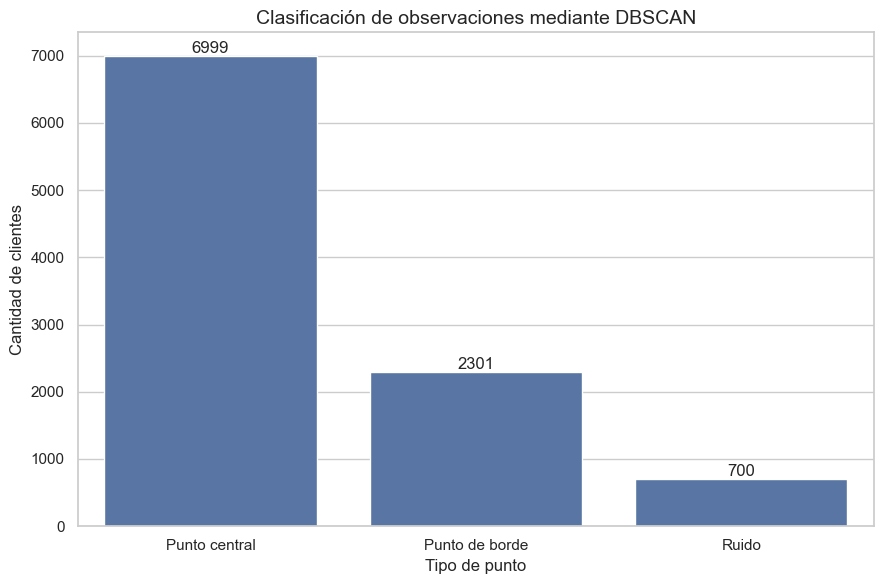

In [79]:
# Distribución por tipo de punto
plt.figure(
    figsize=(9, 6)
)

ax = sns.barplot(
    data=tabla_tipos_dbscan,
    x="Tipo de punto",
    y="Cantidad de clientes"
)

# Etiquetas
for contenedor in ax.containers:

    ax.bar_label(
        contenedor,
        fmt="%.0f"
    )

plt.title(
    "Clasificación de observaciones mediante DBSCAN"
)

plt.xlabel(
    "Tipo de punto"
)

plt.ylabel(
    "Cantidad de clientes"
)

plt.tight_layout()

plt.show()

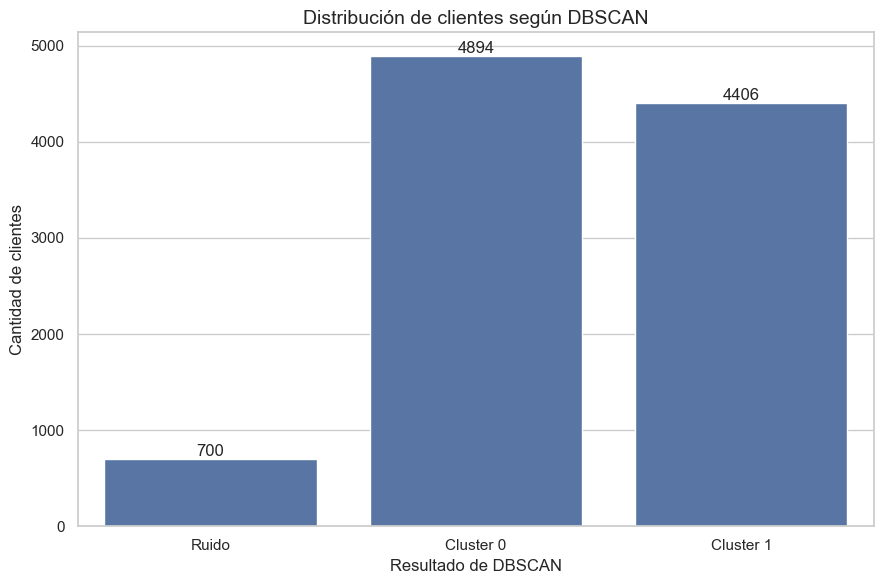

In [80]:
# Distribución por cluster incluyendo el ruido
plt.figure(
    figsize=(9, 6)
)

ax = sns.barplot(
    data=tabla_distribucion_dbscan,
    x="Segmento",
    y="Cantidad de clientes"
)

# Etiquetas
for contenedor in ax.containers:

    ax.bar_label(
        contenedor,
        fmt="%.0f"
    )

plt.title(
    "Distribución de clientes según DBSCAN"
)

plt.xlabel(
    "Resultado de DBSCAN"
)

plt.ylabel(
    "Cantidad de clientes"
)

plt.tight_layout()

plt.show()

In [81]:
# Cantidades principales
total_tipos_dbscan = (
    tabla_tipos_dbscan[
        "Cantidad de clientes"
    ]
    .sum()
)

total_distribucion_dbscan = (
    tabla_distribucion_dbscan[
        "Cantidad de clientes"
    ]
    .sum()
)

# Verificación de exclusividad
suma_mascaras = (
    mascara_core.astype(int)
    + mascara_borde.astype(int)
    + mascara_ruido_dbscan.astype(int)
)

print(
    "Validación del modelo DBSCAN"
)

print(
    "-" * 40
)

print(
    f"Clientes originales: "
    f"{len(df_segmentacion)}"
)

print(
    f"Clientes clasificados por tipo: "
    f"{total_tipos_dbscan}"
)

print(
    f"Clientes representados "
    f"en la distribución: "
    f"{total_distribucion_dbscan}"
)

print(
    f"Clusters obtenidos: "
    f"{sorted(clusters_validos_dbscan)}"
)

print(
    f"Cantidad de clusters: "
    f"{cantidad_clusters_dbscan}"
)

print(
    f"Observaciones de ruido: "
    f"{cantidad_ruido_dbscan}"
)

Validación del modelo DBSCAN
----------------------------------------
Clientes originales: 10000
Clientes clasificados por tipo: 10000
Clientes representados en la distribución: 10000
Clusters obtenidos: [np.int64(0), np.int64(1)]
Cantidad de clusters: 2
Observaciones de ruido: 700


In [82]:
# Comprobaciones automáticas
assert (
    len(
        etiquetas_dbscan
    )
    == len(
        X_cluster
    )
), (
    "La cantidad de etiquetas "
    "no coincide con la base."
)

assert (
    total_tipos_dbscan
    == len(
        X_cluster
    )
), (
    "La clasificación por tipo "
    "no representa toda la base."
)

assert (
    total_distribucion_dbscan
    == len(
        X_cluster
    )
), (
    "La distribución no representa "
    "toda la base."
)

assert np.all(
    suma_mascaras
    == 1
), (
    "Las categorías de puntos "
    "no son mutuamente excluyentes."
)

assert (
    len(
        indices_core
    )
    == mascara_core.sum()
), (
    "La cantidad de puntos centrales "
    "no coincide."
)

assert (
    cantidad_clusters_dbscan
    == 2
), (
    "La cantidad de clusters "
    "no coincide con la esperada."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Interpretación del modelo DBSCAN definitivo**

El modelo DBSCAN definitivo fue configurado con los siguientes parámetros:

- `eps = 1,698`.
- `min_samples = 26`.

La solución identificó dos clusters y clasificó 700 observaciones como ruido.

Los resultados generales fueron:

- Cluster 0: 4.894 clientes, equivalentes al 48,94% de la base.
- Cluster 1: 4.406 clientes, equivalentes al 44,06% de la base.
- Ruido: 700 clientes, equivalentes al 7,00% de la base.

Los dos clusters presentan tamaños relativamente equilibrados.

La clasificación por tipo de punto fue:

- Puntos centrales: 6.999 clientes, equivalentes al 69,99%.
- Puntos de borde: 2.301 clientes, equivalentes al 23,01%.
- Puntos de ruido: 700 clientes, equivalentes al 7,00%.

La elevada proporción de puntos centrales indica que una parte importante de los clientes pertenece a regiones con suficiente densidad.

Los puntos de borde forman parte de los clusters, aunque se encuentran en zonas menos densas.

Las observaciones clasificadas como ruido representan perfiles que, bajo los parámetros seleccionados, no se encuentran conectados con una región suficientemente densa.

La clasificación como ruido no implica que los registros sean incorrectos ni que deban eliminarse. Puede indicar la presencia de combinaciones de características menos frecuentes dentro de la base.

El coeficiente de silueta fue de `0,1283`.

Este valor es cercano al obtenido mediante K-Means, que alcanzó aproximadamente `0,1299`.

Sin embargo, la comparación debe realizarse con cautela debido a que K-Means asignó la totalidad de los clientes a un segmento, mientras que DBSCAN excluyó las observaciones de ruido del cálculo del coeficiente.

La identificación de dos clusters mediante DBSCAN y cuatro segmentos mediante K-Means no representa una contradicción.

Los algoritmos utilizan criterios diferentes:

- K-Means divide la base según la proximidad a centroides y requiere definir previamente la cantidad de grupos.

- DBSCAN identifica regiones conectadas de alta densidad y permite mantener observaciones sin asignación.

Los resultados sugieren que los datos presentan dos regiones principales de densidad relativamente amplia, junto con un conjunto minoritario de clientes con perfiles menos frecuentes.

K-Means, en cambio, permitió generar una segmentación más detallada mediante cuatro perfiles orientados a la interpretación y aplicación de negocio.

#### 10. Comparación entre K-Means y DBSCAN

K-Means y DBSCAN son algoritmos de clustering que utilizan criterios diferentes para descubrir estructuras dentro de los datos.

K-Means:

- Requiere definir previamente la cantidad de clusters.
- Agrupa las observaciones según su proximidad a centroides.
- Asigna todos los clientes a un segmento.
- Tiende a generar grupos compactos alrededor de un centro.

DBSCAN:

- No requiere definir previamente la cantidad de clusters.
- Identifica regiones conectadas de alta densidad.
- Puede detectar grupos con formas irregulares.
- Permite clasificar observaciones como ruido.

La comparación considerará:

- Cantidad de clusters obtenidos.
- Cobertura de la base.
- Presencia de ruido.
- Coeficiente de silueta.
- Distribución de clientes.
- Relación entre las asignaciones de ambos algoritmos.
- Asociación de los resultados de DBSCAN con la tasa de churn.
- Utilidad potencial desde una perspectiva técnica y de negocio.

##### 10.1 Comparación metodológica

Los resultados de K-Means y DBSCAN no deben interpretarse como soluciones equivalentes.

K-Means divide la base completa en una cantidad definida de segmentos.

DBSCAN analiza la estructura de densidad y puede mantener observaciones fuera de los clusters.

Por este motivo, obtener cuatro grupos mediante K-Means y dos mediante DBSCAN no representa una contradicción.

Los algoritmos están observando la estructura de los datos desde perspectivas diferentes.

In [83]:
# Comparación conceptual entre K-Means y DBSCAN

comparacion_metodologica = pd.DataFrame({
    "Criterio": [
        "Criterio de agrupamiento",
        "Requiere definir cantidad de clusters",
        "Utiliza centroides",
        "Asigna todas las observaciones",
        "Detecta ruido",
        "Puede detectar formas irregulares",
        "Sensibilidad principal",
        "Uso potencial"
    ],
    "K-Means": [
        "Proximidad a centroides",
        "Sí",
        "Sí",
        "Sí",
        "No",
        "Limitado",
        "Cantidad de clusters e inicialización",
        "Segmentación operativa"
    ],
    "DBSCAN": [
        "Regiones de alta densidad",
        "No",
        "No",
        "No",
        "Sí",
        "Sí",
        "eps y min_samples",
        "Detección de densidad y perfiles atípicos"
    ]
})

display(
    comparacion_metodologica
)

,Criterio,K-Means,DBSCAN
0,Criterio de agrupamiento,Proximidad a centroides,Regiones de alta densidad
1,Requiere definir cantidad de clusters,Sí,No
2,Utiliza centroides,Sí,No
3,Asigna todas las observaciones,Sí,No
4,Detecta ruido,No,Sí
5,Puede detectar formas irregulares,Limitado,Sí
6,Sensibilidad principal,Cantidad de clusters e inicialización,eps y min_samples
7,Uso potencial,Segmentación operativa,Detección de densidad y perfiles atípicos


##### 10.2 Comparación de los resultados obtenidos

La siguiente tabla resume los principales resultados de ambos algoritmos.

Debe considerarse que los coeficientes de silueta no son completamente equivalentes:

- En K-Means, todos los clientes poseen una etiqueta de cluster.

- En DBSCAN, las observaciones clasificadas como ruido fueron excluidas del cálculo de la silueta.

Por lo tanto, la métrica se utilizará como referencia complementaria y no como único criterio de comparación.

In [84]:
# Porcentaje de clientes asignados por DBSCAN

cobertura_dbscan = (
    clientes_asignados_dbscan
    / len(
        df_segmentacion
    )
    * 100
)

# Tabla comparativa
# de resultados

comparacion_resultados = pd.DataFrame({
    "Indicador": [
        "Cantidad de clusters",
        "Clientes incluidos en clusters",
        "Cobertura de la base",
        "Observaciones de ruido",
        "Porcentaje de ruido",
        "Coeficiente de silueta",
        "Cantidad de segmentos principales"
    ],
    "K-Means": [
        f"{K_FINAL}",
        f"{len(df_segmentacion):,}",
        "100,00%",
        "0",
        "0,00%",
        f"{silueta_kmeans_final:.4f}",
        "4"
    ],
    "DBSCAN": [
        f"{cantidad_clusters_dbscan}",
        f"{clientes_asignados_dbscan:,}",
        f"{cobertura_dbscan:.2f}%",
        f"{cantidad_ruido_dbscan:,}",
        (
            f"{cantidad_ruido_dbscan / len(df_segmentacion) * 100:.2f}%"
        ),
        f"{silueta_dbscan_final:.4f}",
        "2 clusters y ruido"
    ]
})

display(
    comparacion_resultados
)

,Indicador,K-Means,DBSCAN
0,Cantidad de clusters,4,2
1,Clientes incluidos en clusters,"10,000","9,300"
2,Cobertura de la base,"100,00%",93.00%
3,Observaciones de ruido,0,700
4,Porcentaje de ruido,"0,00%",7.00%
5,Coeficiente de silueta,0.1299,0.1283
6,Cantidad de segmentos principales,4,2 clusters y ruido


##### 10.3 Relación entre los segmentos de K-Means y DBSCAN

Los números utilizados por los algoritmos son etiquetas arbitrarias.

Por ejemplo:

- El Cluster 0 de K-Means no representa necesariamente el mismo grupo que el Cluster 0 de DBSCAN.

Para estudiar la relación entre ambas segmentaciones se construirá una tabla cruzada.

La tabla permitirá analizar cómo se distribuyen los cuatro segmentos de K-Means dentro de:

- Cluster 0 de DBSCAN.
- Cluster 1 de DBSCAN.
- Observaciones clasificadas como ruido.

In [85]:
# Dataset auxiliar para comparar las asignaciones

df_comparacion_clusters = (
    df_segmentacion[
        [
            "Cluster_KMeans",
            "Cluster_DBSCAN"
        ]
    ]
    .copy()
)

# Etiquetas descriptivas
# de K-Means

df_comparacion_clusters[
    "Segmento_KMeans"
] = (
    "K-Means "
    + df_comparacion_clusters[
        "Cluster_KMeans"
    ]
    .astype(str)
)

# Etiquetas descriptivas
# de DBSCAN

df_comparacion_clusters[
    "Segmento_DBSCAN"
] = (
    df_comparacion_clusters[
        "Cluster_DBSCAN"
    ]
    .apply(
        lambda cluster: (
            "Ruido"
            if cluster == -1
            else f"DBSCAN {cluster}"
        )
    )
)

print(
    "Etiquetas descriptivas "
    "creadas correctamente."
)

Etiquetas descriptivas creadas correctamente.


In [86]:
# Tabla cruzada en cantidad de clientes

tabla_cruce_clusters = (
    pd.crosstab(
        df_comparacion_clusters[
            "Segmento_KMeans"
        ],
        df_comparacion_clusters[
            "Segmento_DBSCAN"
        ]
    )
)

# Orden esperado
# de las columnas

orden_columnas_dbscan = [
    columna
    for columna
    in [
        "DBSCAN 0",
        "DBSCAN 1",
        "Ruido"
    ]
    if columna
    in tabla_cruce_clusters.columns
]

tabla_cruce_clusters = (
    tabla_cruce_clusters[
        orden_columnas_dbscan
    ]
)

tabla_cruce_clusters.index.name = (
    "Segmento K-Means"
)

display(
    tabla_cruce_clusters
)

Segmento_DBSCAN,DBSCAN 0,DBSCAN 1,Ruido
Segmento K-Means,,,
K-Means 0,0,1724,254
K-Means 1,681,2464,124
K-Means 2,3491,0,9
K-Means 3,722,218,313


##### 10.4 Distribución porcentual de DBSCAN dentro de cada cluster de K-Means

La tabla porcentual permitirá analizar la composición interna de cada segmento de K-Means.

Cada fila representará el 100% de los clientes pertenecientes a un cluster de K-Means.

Los porcentajes indicarán qué proporción fue asignada a cada región identificada mediante DBSCAN o clasificada como ruido.

In [87]:
# Tabla cruzada normalizada por fila

tabla_cruce_clusters_pct = (
    pd.crosstab(
        df_comparacion_clusters[
            "Segmento_KMeans"
        ],
        df_comparacion_clusters[
            "Segmento_DBSCAN"
        ],
        normalize="index"
    )
    .mul(100)
)

# Reordenamiento
# de las columnas

tabla_cruce_clusters_pct = (
    tabla_cruce_clusters_pct[
        orden_columnas_dbscan
    ]
)

# Redondeo
tabla_cruce_clusters_pct = (
    tabla_cruce_clusters_pct
    .round(2)
)

tabla_cruce_clusters_pct.index.name = (
    "Segmento K-Means"
)

display(
    tabla_cruce_clusters_pct
)

Segmento_DBSCAN,DBSCAN 0,DBSCAN 1,Ruido
Segmento K-Means,,,
K-Means 0,0.00,87.16,12.84
K-Means 1,20.83,75.37,3.79
K-Means 2,99.74,0.00,0.26
K-Means 3,57.62,17.40,24.98


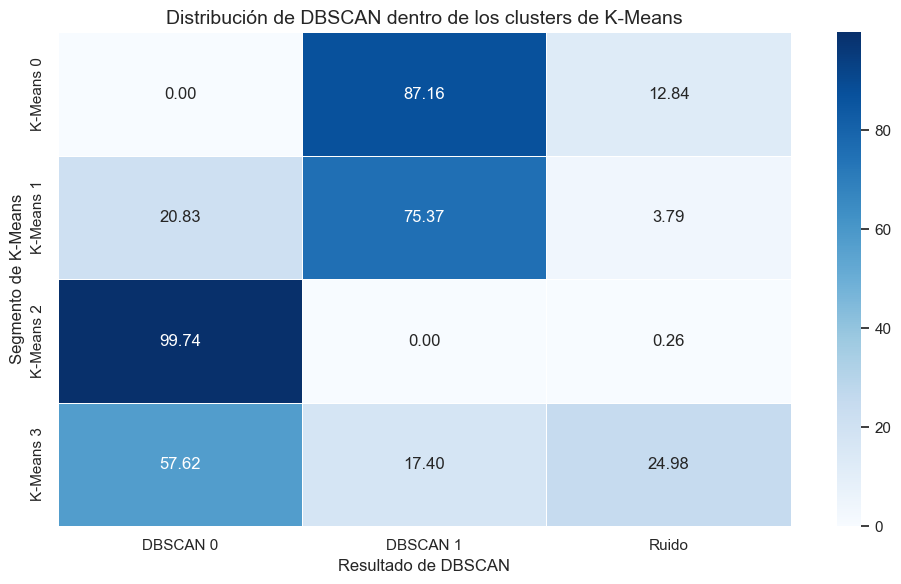

In [88]:
# Mapa de calor de la relación entre algoritmos

plt.figure(
    figsize=(10, 6)
)

sns.heatmap(
    tabla_cruce_clusters_pct,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title(
    "Distribución de DBSCAN dentro de los clusters de K-Means"
)

plt.xlabel(
    "Resultado de DBSCAN"
)

plt.ylabel(
    "Segmento de K-Means"
)

plt.tight_layout()

plt.show()

##### 10.5 Tasa de churn según los resultados de DBSCAN

Aunque DBSCAN no utilizó la variable `Exited` para construir los grupos, es posible analizar posteriormente la tasa de abandono correspondiente a:

- Cluster 0.
- Cluster 1.
- Observaciones clasificadas como ruido.

Este análisis permitirá evaluar si las regiones de densidad identificadas presentan comportamientos diferenciados respecto del churn.

La variable `Exited` no será utilizada para modificar los parámetros ni seleccionar una nueva configuración.

In [89]:
# Análisis de churn según DBSCAN

tabla_churn_dbscan = (
    df_segmentacion
    .groupby(
        "Cluster_DBSCAN"
    )
    .agg(
        Cantidad_clientes=(
            "Exited",
            "size"
        ),
        Clientes_que_abandonaron=(
            "Exited",
            "sum"
        )
    )
    .reset_index()
)

# Clientes que permanecieron

tabla_churn_dbscan[
    "Clientes_que_permanecieron"
] = (
    tabla_churn_dbscan[
        "Cantidad_clientes"
    ]
    - tabla_churn_dbscan[
        "Clientes_que_abandonaron"
    ]
)

# Tasa de churn

tabla_churn_dbscan[
    "Tasa_churn_pct"
] = (
    tabla_churn_dbscan[
        "Clientes_que_abandonaron"
    ]
    .div(
        tabla_churn_dbscan[
            "Cantidad_clientes"
        ]
    )
    .mul(100)
)

# Diferencia respecto
# de la tasa general

tabla_churn_dbscan[
    "Diferencia_vs_general_pp"
] = (
    tabla_churn_dbscan[
        "Tasa_churn_pct"
    ]
    - tasa_churn_general_pct
)

# Etiqueta descriptiva

tabla_churn_dbscan[
    "Resultado_DBSCAN"
] = (
    tabla_churn_dbscan[
        "Cluster_DBSCAN"
    ]
    .apply(
        lambda cluster: (
            "Ruido"
            if cluster == -1
            else f"Cluster {cluster}"
        )
    )
)

In [90]:
# Tabla final de churn según DBSCAN

tabla_churn_dbscan_visual = (
    tabla_churn_dbscan[
        [
            "Cluster_DBSCAN",
            "Resultado_DBSCAN",
            "Cantidad_clientes",
            "Clientes_que_permanecieron",
            "Clientes_que_abandonaron",
            "Tasa_churn_pct",
            "Diferencia_vs_general_pp"
        ]
    ]
    .copy()
)

# Nombres descriptivos

tabla_churn_dbscan_visual = (
    tabla_churn_dbscan_visual
    .rename(
        columns={
            "Cluster_DBSCAN": (
                "Etiqueta"
            ),
            "Resultado_DBSCAN": (
                "Resultado DBSCAN"
            ),
            "Cantidad_clientes": (
                "Cantidad de clientes"
            ),
            "Clientes_que_permanecieron": (
                "Clientes que permanecieron"
            ),
            "Clientes_que_abandonaron": (
                "Clientes que abandonaron"
            ),
            "Tasa_churn_pct": (
                "Tasa de churn (%)"
            ),
            "Diferencia_vs_general_pp": (
                "Diferencia vs. general (p.p.)"
            )
        }
    )
)

# Redondeo

tabla_churn_dbscan_visual[
    [
        "Tasa de churn (%)",
        "Diferencia vs. general (p.p.)"
    ]
] = (
    tabla_churn_dbscan_visual[
        [
            "Tasa de churn (%)",
            "Diferencia vs. general (p.p.)"
        ]
    ]
    .round(2)
)

display(
    tabla_churn_dbscan_visual
)

,Etiqueta,Resultado DBSCAN,Cantidad de clientes,Clientes que permanecieron,Clientes que abandonaron,Tasa de churn (%),Diferencia vs. general (p.p.)
0,-1,Ruido,700,307,393,56.14,35.77
1,0,Cluster 0,4894,3553,1341,27.40,7.03
2,1,Cluster 1,4406,4103,303,6.88,-13.49


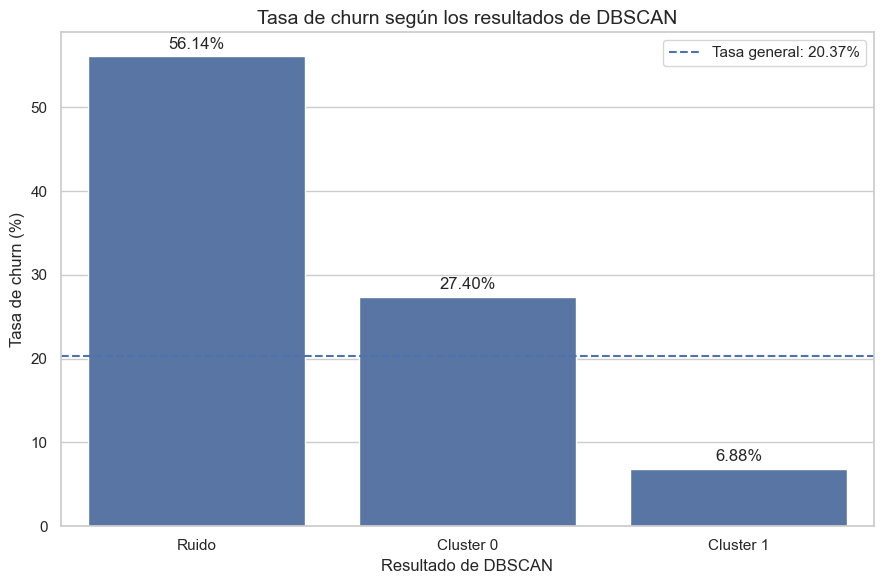

In [91]:
# Tasa de churn según DBSCAN

plt.figure(
    figsize=(9, 6)
)

ax = sns.barplot(
    data=tabla_churn_dbscan_visual,
    x="Resultado DBSCAN",
    y="Tasa de churn (%)"
)

# Etiquetas porcentuales

for contenedor in ax.containers:

    etiquetas = [
        f"{valor:.2f}%"
        for valor
        in tabla_churn_dbscan_visual[
            "Tasa de churn (%)"
        ]
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        padding=3
    )

# Tasa general

plt.axhline(
    y=tasa_churn_general_pct,
    linestyle="--",
    label=(
        "Tasa general: "
        f"{tasa_churn_general_pct:.2f}%"
    )
)

plt.title(
    "Tasa de churn según los resultados de DBSCAN"
)

plt.xlabel(
    "Resultado de DBSCAN"
)

plt.ylabel(
    "Tasa de churn (%)"
)

plt.legend()

plt.tight_layout()

plt.show()

##### 10.6 Validación de las comparaciones

Se verificará que:

- La tabla cruzada represente los 10.000 clientes.
- Cada fila porcentual sume aproximadamente 100%.
- La tabla de churn de DBSCAN incluya la totalidad de la base.
- La cantidad total de abandonos coincida con el dataset original.

In [92]:
# Total representado en la tabla cruzada

total_tabla_cruce = (
    tabla_cruce_clusters
    .to_numpy()
    .sum()
)

# Suma porcentual
# por fila

suma_filas_porcentuales = (
    tabla_cruce_clusters_pct
    .sum(
        axis=1
    )
)

# Totales de churn
# según DBSCAN

total_clientes_dbscan_churn = (
    tabla_churn_dbscan[
        "Cantidad_clientes"
    ]
    .sum()
)

total_abandonos_dbscan = (
    tabla_churn_dbscan[
        "Clientes_que_abandonaron"
    ]
    .sum()
)

print(
    "Validación de la comparación"
)

print(
    "-" * 40
)

print(
    f"Clientes representados "
    f"en la tabla cruzada: "
    f"{total_tabla_cruce}"
)

print(
    f"Clientes representados "
    f"en el análisis de churn: "
    f"{total_clientes_dbscan_churn}"
)

print(
    f"Clientes que abandonaron: "
    f"{total_abandonos_dbscan}"
)

print(
    "\nSuma porcentual por fila:"
)

display(
    suma_filas_porcentuales
    .round(2)
)

Validación de la comparación
----------------------------------------
Clientes representados en la tabla cruzada: 10000
Clientes representados en el análisis de churn: 10000
Clientes que abandonaron: 2037

Suma porcentual por fila:


Segmento K-Means
K-Means 0    100.00
K-Means 1     99.99
K-Means 2    100.00
K-Means 3    100.00
dtype: float64

In [93]:
# Comprobaciones automáticas

assert (
    total_tabla_cruce
    == len(
        df_segmentacion
    )
), (
    "La tabla cruzada no representa "
    "la totalidad de los clientes."
)

assert np.allclose(
    suma_filas_porcentuales,
    100,
    atol=0.05
), (
    "Las filas porcentuales "
    "no suman aproximadamente 100%."
)

assert (
    total_clientes_dbscan_churn
    == len(
        df_segmentacion
    )
), (
    "El análisis de churn de DBSCAN "
    "no representa toda la base."
)

assert (
    total_abandonos_dbscan
    == total_churn
), (
    "La cantidad de abandonos "
    "no coincide con el total."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Conclusión de la comparación entre K-Means y DBSCAN**

K-Means y DBSCAN identificaron estructuras diferentes debido a que utilizan criterios de agrupamiento distintos.

K-Means generó cuatro segmentos y asignó la totalidad de los 10.000 clientes.

DBSCAN identificó dos regiones principales de densidad, asignó 9.300 clientes a clusters y clasificó 700 observaciones como ruido.

Los coeficientes de silueta fueron similares:

- K-Means: `0,1299`.
- DBSCAN: `0,1283`.

Sin embargo, estos valores no son completamente equivalentes.

K-Means incluyó la totalidad de los clientes, mientras que DBSCAN excluyó las observaciones de ruido del cálculo de la silueta.

La relación entre las asignaciones mostró que DBSCAN generó una estructura más general:

- El 87,16% del Cluster 0 de K-Means fue asignado al Cluster 1 de DBSCAN.

- El 75,37% del Cluster 1 de K-Means fue asignado al Cluster 1 de DBSCAN.

- El 99,74% del Cluster 2 de K-Means fue asignado al Cluster 0 de DBSCAN.

- El Cluster 3 de K-Means presentó la estructura más heterogénea: 57,62% fue asignado al Cluster 0 de DBSCAN, 17,40% al Cluster 1 y 24,98% fue clasificado como ruido.

La correspondencia casi completa entre el Cluster 2 de K-Means y el Cluster 0 de DBSCAN indica que el perfil caracterizado por saldo elevado y un único producto constituye una región de densidad consistente.

Por el contrario, el Cluster 3 presenta una estructura más diversa y la mayor proporción relativa de observaciones clasificadas como ruido.

El análisis posterior del churn mostró diferencias importantes:

- Ruido: tasa de churn del `56,14%`.

- Cluster 0 de DBSCAN: tasa de churn del `27,40%`.

- Cluster 1 de DBSCAN: tasa de churn del `6,88%`.

Las observaciones clasificadas como ruido representan el 7,00% de la base, pero concentran 393 clientes que abandonaron.

La elevada tasa de churn del grupo de ruido indica que los perfiles ubicados en regiones de menor densidad presentan una asociación importante con el abandono.

Sin embargo, la clasificación como ruido no implica que los registros sean incorrectos ni demuestra una relación causal.

K-Means será utilizado como algoritmo principal de segmentación porque:

- Asigna la totalidad de los clientes.

- Genera cuatro perfiles interpretables.

- Cumple con el objetivo de identificar entre 3 y 5 segmentos.

- Facilita el diseño de estrategias comerciales y de retención diferenciadas.

- Permite crear una variable de cluster aplicable a futuros modelos.

DBSCAN será utilizado como método complementario.

Su principal aporte consiste en:

- Analizar la estructura de densidad.

- Diferenciar puntos centrales y de borde.

- Identificar clientes con combinaciones de características menos frecuentes.

- Detectar un grupo de ruido con una tasa de churn considerablemente elevada.

Por lo tanto, ambos algoritmos aportan información complementaria:

**K-Means proporciona una segmentación operativa y detallada.**

**DBSCAN aporta una perspectiva adicional sobre densidad, atipicidad y posibles perfiles de riesgo.**

#### 11. Reducción de dimensionalidad mediante PCA

PCA, o Análisis de Componentes Principales, es una técnica de reducción de dimensionalidad.

Su objetivo es transformar un conjunto de variables posiblemente relacionadas en un nuevo conjunto de variables denominadas componentes principales.

Las componentes presentan las siguientes características:

- Son combinaciones lineales de las variables originales.
- No se encuentran correlacionadas entre sí.
- Se ordenan según la cantidad de variabilidad que logran representar.

La primera componente principal captura la mayor cantidad posible de varianza.

La segunda componente explica la mayor cantidad de varianza restante y es perpendicular a la primera.

El procedimiento continúa hasta obtener una cantidad de componentes igual al número de características originales.

PCA permitirá representar la información contenida en las 13 variables transformadas mediante una cantidad menor de dimensiones.

##### 11.1 Datos utilizados para PCA

PCA se aplicará sobre la matriz:

`X_cluster`

Esta es la misma representación utilizada para entrenar K-Means y DBSCAN.

La matriz contiene:

- Variables numéricas estandarizadas.
- Variables categóricas transformadas mediante One-Hot Encoding.
- Variables binarias expresadas mediante valores `0` y `1`.

La variable `Exited` no forma parte de la matriz.

La utilización del mismo espacio de características permite que las visualizaciones obtenidas mediante PCA representen la estructura utilizada por los algoritmos de clustering.

PCA no utilizará la información de churn para construir las componentes.

Debido a que se conservaron todas las categorías durante el One-Hot Encoding, algunas columnas presentan dependencia lineal. PCA puede manejar esta situación y es posible que las últimas componentes expliquen una cantidad de varianza cercana a cero.

In [94]:
# Validación de la matriz utilizada por PCA

print(
    "Dimensiones de X_cluster:"
)

print(
    X_cluster.shape
)

print(
    "\nCantidad de valores faltantes:"
)

print(
    X_cluster
    .isna()
    .sum()
    .sum()
)

print(
    "\nVariable 'Exited' incluida:"
)

print(
    "Exited"
    in X_cluster.columns
)

Dimensiones de X_cluster:
(10000, 13)

Cantidad de valores faltantes:
0

Variable 'Exited' incluida:
False


##### 11.2 Ajuste del modelo PCA completo


Inicialmente se conservarán todas las componentes disponibles.

El objetivo será analizar:

- La varianza explicada por cada componente.
- La varianza explicada acumulada.
- La cantidad de componentes necesaria para conservar una proporción relevante de la información.

Todavía no se limitará el número de componentes.

El modelo completo permitirá evaluar cómo se distribuye la variabilidad entre las distintas dimensiones.

In [95]:
# Creación del modelo PCA conservando todas las componentes

modelo_pca_completo = PCA()

# Ajuste y transformación
X_pca_completo = (
    modelo_pca_completo
    .fit_transform(
        X_cluster
    )
)

# Cantidad total de componentes
cantidad_componentes_pca = (
    modelo_pca_completo
    .n_components_
)

print(
    "Modelo PCA ajustado correctamente."
)

print(
    f"Cantidad de componentes obtenidas: "
    f"{cantidad_componentes_pca}"
)

print(
    f"Dimensiones de la matriz transformada: "
    f"{X_pca_completo.shape}"
)

Modelo PCA ajustado correctamente.
Cantidad de componentes obtenidas: 13
Dimensiones de la matriz transformada: (10000, 13)


##### 11.3 Varianza explicada por componente

La varianza explicada indica qué proporción de la variabilidad total de los datos es representada por cada componente principal.

Una componente con una proporción elevada contiene una parte importante de la información presente en el conjunto original.

La varianza acumulada representa la suma progresiva de la información explicada.

Este indicador permite determinar cuántas componentes serían necesarias para conservar una proporción determinada de la variabilidad total.

In [96]:
# Varianza explicada por cada componente

varianza_explicada_pca = (
    modelo_pca_completo
    .explained_variance_ratio_
)

# Varianza acumulada

varianza_acumulada_pca = (
    np.cumsum(
        varianza_explicada_pca
    )
)

# Nombres de las componentes

nombres_componentes = [
    f"PC{numero}"
    for numero
    in range(
        1,
        cantidad_componentes_pca + 1
    )
]

# Tabla de varianza

tabla_varianza_pca = pd.DataFrame({
    "Componente": (
        nombres_componentes
    ),
    "Varianza explicada (%)": (
        varianza_explicada_pca
        * 100
    ),
    "Varianza acumulada (%)": (
        varianza_acumulada_pca
        * 100
    )
})

# Redondeo

tabla_varianza_pca[
    [
        "Varianza explicada (%)",
        "Varianza acumulada (%)"
    ]
] = (
    tabla_varianza_pca[
        [
            "Varianza explicada (%)",
            "Varianza acumulada (%)"
        ]
    ]
    .round(2)
)

display(
    tabla_varianza_pca
)

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,17.64,17.64
1,PC2,13.40,31.04
2,PC3,13.21,44.26
3,PC4,13.11,57.37
4,PC5,13.06,70.43
5,PC6,9.78,80.21
6,PC7,6.53,86.74
7,PC8,4.59,91.33
8,PC9,3.26,94.59
9,PC10,2.77,97.37


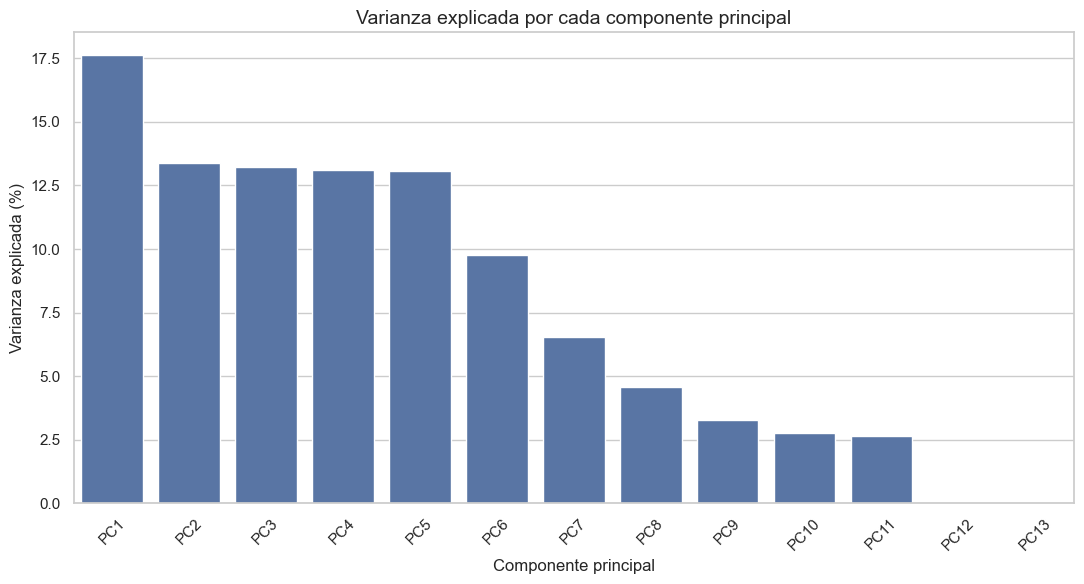

In [97]:
# Gráfico de varianza explicada por cada componente

plt.figure(
    figsize=(11, 6)
)

ax = sns.barplot(
    data=tabla_varianza_pca,
    x="Componente",
    y="Varianza explicada (%)"
)

plt.title(
    "Varianza explicada por cada componente principal"
)

plt.xlabel(
    "Componente principal"
)

plt.ylabel(
    "Varianza explicada (%)"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

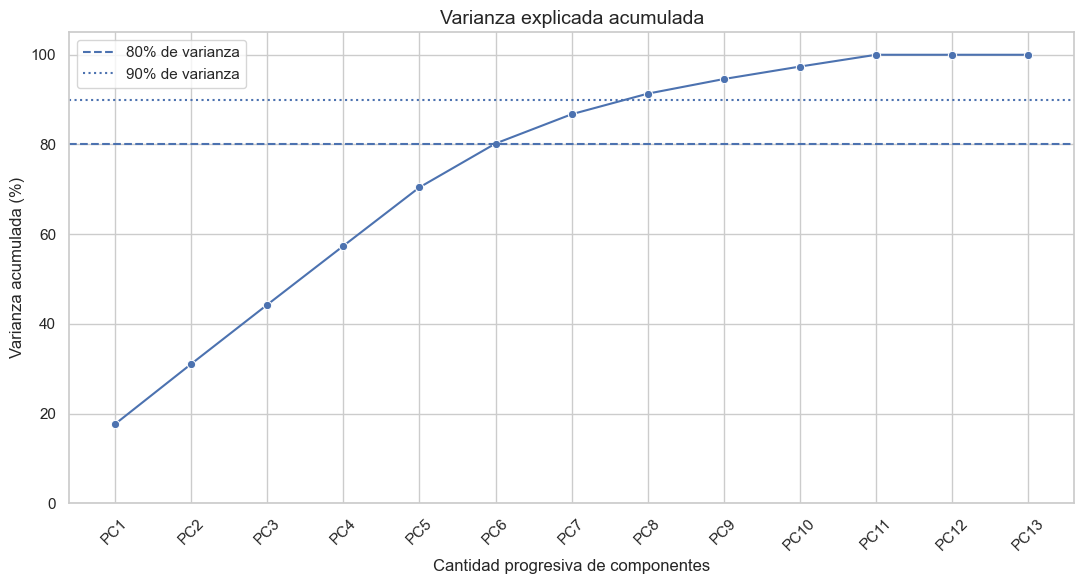

In [98]:
# Gráfico de varianza explicada acumulada

plt.figure(
    figsize=(11, 6)
)

sns.lineplot(
    data=tabla_varianza_pca,
    x="Componente",
    y="Varianza acumulada (%)",
    marker="o"
)

# Líneas de referencia

plt.axhline(
    y=80,
    linestyle="--",
    label="80% de varianza"
)

plt.axhline(
    y=90,
    linestyle=":",
    label="90% de varianza"
)

plt.title(
    "Varianza explicada acumulada"
)

plt.xlabel(
    "Cantidad progresiva de componentes"
)

plt.ylabel(
    "Varianza acumulada (%)"
)

plt.xticks(
    rotation=45
)

plt.ylim(
    0,
    105
)

plt.legend()

plt.tight_layout()

plt.show()

##### 11.4 Selección del número de componentes

No existe un porcentaje universal que deba conservarse en todos los problemas.

Como referencias analíticas se calculará cuántas componentes son necesarias para representar:

- Al menos el 80% de la varianza total.
- Al menos el 90% de la varianza total.

Estos valores permitirán evaluar cuánto puede reducirse la dimensionalidad sin perder una proporción excesiva de información.

La selección para visualización será diferente:

- Se utilizarán dos componentes para representar los datos en 2D.
- Se utilizarán tres componentes para representar los datos en 3D.

Las visualizaciones constituyen proyecciones parciales y no necesariamente conservan toda la información del espacio original.

In [99]:
# Cantidad de componentes necesarias para cada umbral

componentes_80 = int(
    np.searchsorted(
        varianza_acumulada_pca,
        0.80
    )
    + 1
)

componentes_90 = int(
    np.searchsorted(
        varianza_acumulada_pca,
        0.90
    )
    + 1
)

# Varianza representada
# en dos y tres dimensiones

varianza_2d = (
    varianza_explicada_pca[
        :2
    ]
    .sum()
    * 100
)

varianza_3d = (
    varianza_explicada_pca[
        :3
    ]
    .sum()
    * 100
)

print(
    "Selección de componentes"
)

print(
    "-" * 40
)

print(
    "Componentes necesarias "
    f"para alcanzar al menos 80%: "
    f"{componentes_80}"
)

print(
    "Componentes necesarias "
    f"para alcanzar al menos 90%: "
    f"{componentes_90}"
)

print(
    "\nVarianza representada "
    f"en la visualización 2D: "
    f"{varianza_2d:.2f}%"
)

print(
    "Varianza representada "
    f"en la visualización 3D: "
    f"{varianza_3d:.2f}%"
)

Selección de componentes
----------------------------------------
Componentes necesarias para alcanzar al menos 80%: 6
Componentes necesarias para alcanzar al menos 90%: 8

Varianza representada en la visualización 2D: 31.04%
Varianza representada en la visualización 3D: 44.26%


In [100]:
# Tabla resumen de conservación de varianza

resumen_componentes_pca = pd.DataFrame({
    "Criterio": [
        "Visualización en 2D",
        "Visualización en 3D",
        "Al menos 80% de varianza",
        "Al menos 90% de varianza"
    ],
    "Cantidad de componentes": [
        2,
        3,
        componentes_80,
        componentes_90
    ],
    "Varianza representada (%)": [
        varianza_2d,
        varianza_3d,
        (
            varianza_acumulada_pca[
                componentes_80 - 1
            ]
            * 100
        ),
        (
            varianza_acumulada_pca[
                componentes_90 - 1
            ]
            * 100
        )
    ]
})

resumen_componentes_pca[
    "Varianza representada (%)"
] = (
    resumen_componentes_pca[
        "Varianza representada (%)"
    ]
    .round(2)
)

display(
    resumen_componentes_pca
)

,Criterio,Cantidad de componentes,Varianza representada (%)
0,Visualización en 2D,2,31.04
1,Visualización en 3D,3,44.26
2,Al menos 80% de varianza,6,80.21
3,Al menos 90% de varianza,8,91.33


##### 11.5 Creación de la representación mediante componentes principales

Se construirá un nuevo DataFrame que contendrá las coordenadas obtenidas mediante PCA.

Cada fila continuará representando al mismo cliente.

Las columnas `PC1`, `PC2` y `PC3` serán utilizadas para visualizar la distribución de los datos.

También se incorporará la etiqueta obtenida mediante K-Means.

Es importante destacar que PCA no volverá a entrenar K-Means.

Los clusters fueron construidos utilizando las 13 características transformadas.

PCA únicamente proyectará esos resultados en un espacio de menor dimensionalidad.

In [101]:
# DataFrame con todas las componentes principales

df_pca = pd.DataFrame(
    X_pca_completo,
    columns=nombres_componentes,
    index=X_cluster.index
)

# Incorporación de etiquetas
# obtenidas mediante K-Means

df_pca[
    "Cluster_KMeans"
] = (
    etiquetas_kmeans
)

# Etiqueta descriptiva

df_pca[
    "Segmento_KMeans"
] = (
    "Cluster "
    + df_pca[
        "Cluster_KMeans"
    ]
    .astype(str)
)

print(
    "Dataset PCA creado correctamente."
)

print(
    f"Dimensiones: "
    f"{df_pca.shape}"
)

display(
    df_pca.head()
)

Dataset PCA creado correctamente.
Dimensiones: (10000, 15)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,Cluster_KMeans,Segmento_KMeans
0,-0.249690,-0.926899,-0.358876,0.515229,-0.488642,-1.512932,-0.770863,0.287400,0.419690,0.443506,0.095938,7.771561e-16,6.661338e-16,1,Cluster 1
1,0.778122,-0.832736,-0.413112,0.788855,-0.822586,-0.547316,-0.733698,-0.835473,0.594082,-0.773233,-0.057598,4.440892e-16,7.771561e-16,2,Cluster 2
2,-0.807402,0.505031,-1.569345,-0.246213,0.765548,2.581597,-0.677299,1.022333,-0.380031,-0.185222,-0.832196,-2.220446e-15,-2.109424e-15,0,Cluster 0
3,-1.412976,-1.006839,0.530966,0.787365,-0.751859,-0.285581,-0.749518,0.423456,-0.491409,-0.614910,0.394660,-3.330669e-16,0.000000e+00,1,Cluster 1
4,1.231182,-0.770157,2.113040,0.672218,-0.151200,-0.242173,-0.721176,-0.695618,0.497326,-0.001171,-0.719051,2.220446e-16,3.330669e-16,2,Cluster 2


##### 11.6 Proyección de los centroides de K-Means

Los centroides del modelo K-Means también serán transformados mediante PCA.

Esto permitirá ubicarlos dentro de las visualizaciones en dos y tres dimensiones.

Los centroides serán representados mediante un marcador diferente para distinguirlos de los clientes.

In [102]:
# Transformación de los centroides al espacio PCA

centroides_pca = (
    modelo_pca_completo
    .transform(
        modelo_kmeans_final
        .cluster_centers_
    )
)

# Conversión a DataFrame

df_centroides_pca = pd.DataFrame(
    centroides_pca,
    columns=nombres_componentes
)

# Identificación del cluster

df_centroides_pca[
    "Cluster"
] = (
    range(
        K_FINAL
    )
)

display(
    df_centroides_pca[
        [
            "Cluster",
            "PC1",
            "PC2",
            "PC3"
        ]
    ]
    .round(3)
)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,Cluster,PC1,PC2,PC3
0,0,-0.136,0.184,0.079
1,1,-1.291,0.020,-0.027
2,2,1.089,0.274,0.046
3,3,0.542,-1.106,-0.183


##### 11.7 Visualización de los clusters en dos dimensiones

La siguiente representación utilizará:

- Eje horizontal: primera componente principal.
- Eje vertical: segunda componente principal.
- Color: cluster obtenido mediante K-Means.
- Marcador destacado: centroide proyectado de cada cluster.

La visualización permitirá analizar el nivel de separación y superposición de los segmentos.

Las distancias observadas corresponden a una proyección parcial y no representan necesariamente toda la estructura del espacio original.

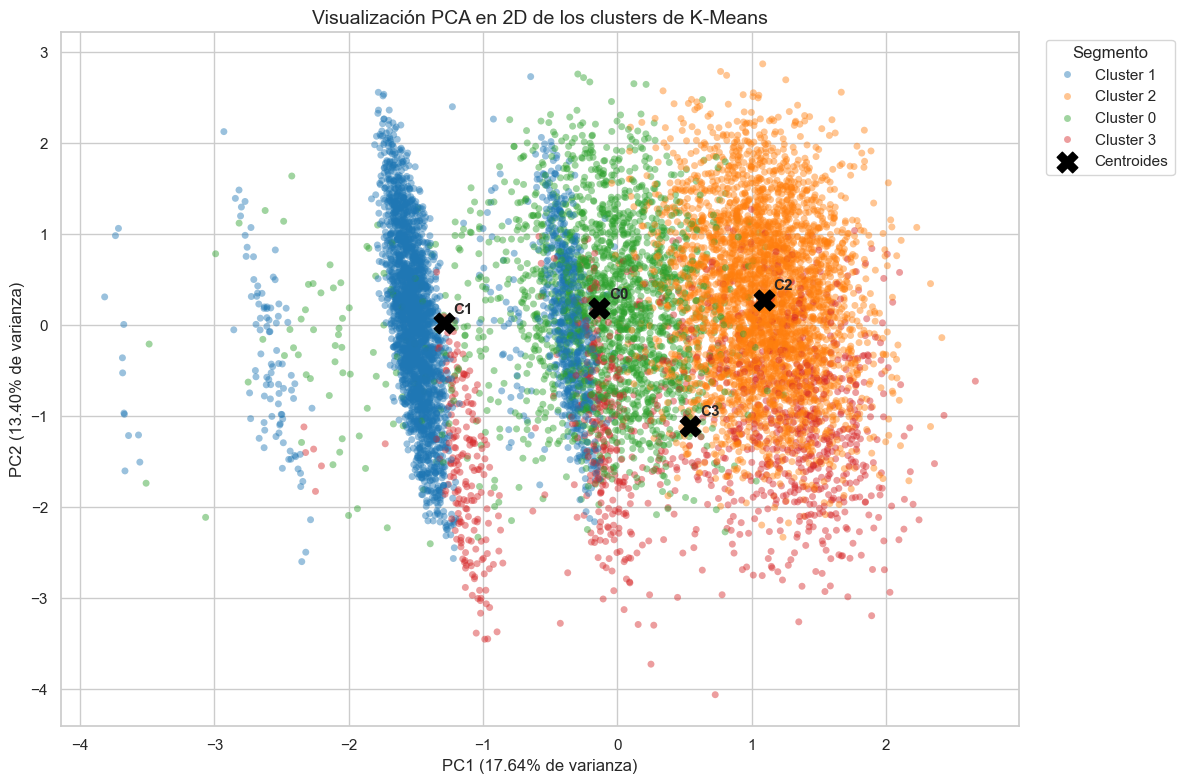

In [103]:
# Visualización PCA en dos dimensiones

plt.figure(
    figsize=(12, 8)
)

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Segmento_KMeans",
    palette="tab10",
    alpha=0.45,
    s=25,
    linewidth=0
)

# Incorporación de centroides

plt.scatter(
    df_centroides_pca[
        "PC1"
    ],
    df_centroides_pca[
        "PC2"
    ],
    marker="X",
    s=220,
    color="black",
    label="Centroides"
)

# Etiquetas de centroides

for _, fila in (
    df_centroides_pca
    .iterrows()
):

    plt.annotate(
        f"C{int(fila['Cluster'])}",
        (
            fila["PC1"],
            fila["PC2"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Visualización PCA en 2D de los clusters de K-Means"
)

plt.xlabel(
    "PC1 "
    f"({varianza_explicada_pca[0] * 100:.2f}% de varianza)"
)

plt.ylabel(
    "PC2 "
    f"({varianza_explicada_pca[1] * 100:.2f}% de varianza)"
)

plt.legend(
    title="Segmento",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

##### 11.8 Visualización de los clusters en tres dimensiones

La representación tridimensional incorporará la tercera componente principal.

Los ejes serán:

- PC1.
- PC2.
- PC3.

La tercera dimensión puede revelar separaciones que no resultan visibles en una proyección bidimensional.

Sin embargo, la representación continuará siendo una simplificación del espacio original.

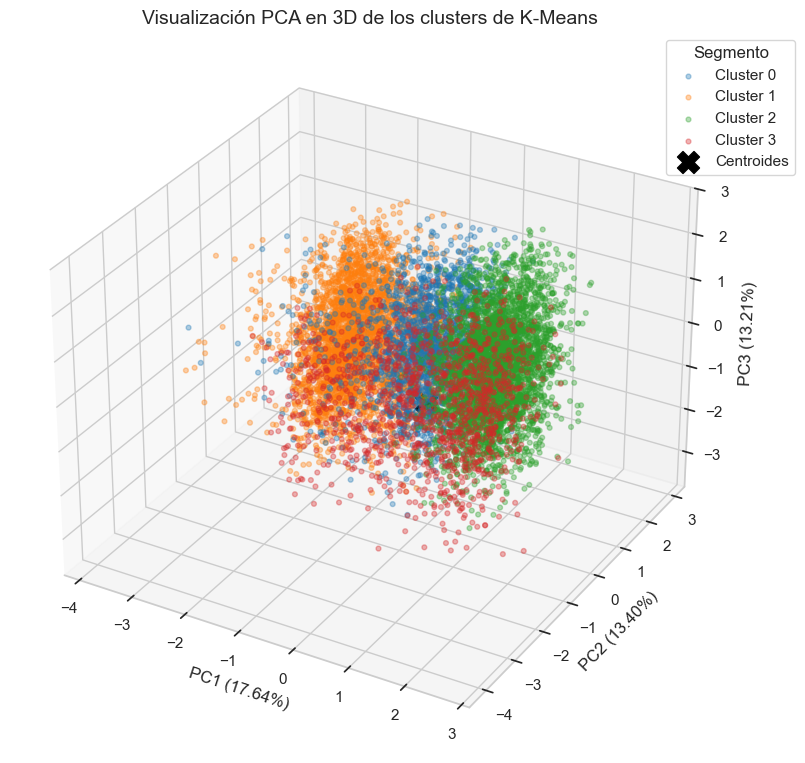

In [104]:
# Visualización PCA en tres dimensiones

fig = plt.figure(
    figsize=(13, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# Colores para los clusters

colores_clusters = (
    sns.color_palette(
        "tab10",
        K_FINAL
    )
)

# Representación de cada cluster

for cluster in range(
    K_FINAL
):

    mascara_cluster = (
        df_pca[
            "Cluster_KMeans"
        ]
        == cluster
    )

    ax.scatter(
        df_pca.loc[
            mascara_cluster,
            "PC1"
        ],
        df_pca.loc[
            mascara_cluster,
            "PC2"
        ],
        df_pca.loc[
            mascara_cluster,
            "PC3"
        ],
        s=12,
        alpha=0.35,
        color=(
            colores_clusters[
                cluster
            ]
        ),
        label=f"Cluster {cluster}"
    )

# Centroides

ax.scatter(
    df_centroides_pca[
        "PC1"
    ],
    df_centroides_pca[
        "PC2"
    ],
    df_centroides_pca[
        "PC3"
    ],
    marker="X",
    s=250,
    color="black",
    label="Centroides"
)

ax.set_title(
    "Visualización PCA en 3D de los clusters de K-Means"
)

ax.set_xlabel(
    "PC1 "
    f"({varianza_explicada_pca[0] * 100:.2f}%)"
)

ax.set_ylabel(
    "PC2 "
    f"({varianza_explicada_pca[1] * 100:.2f}%)"
)

ax.set_zlabel(
    "PC3 "
    f"({varianza_explicada_pca[2] * 100:.2f}%)"
)

ax.legend(
    title="Segmento",
    bbox_to_anchor=(1.10, 1)
)

plt.tight_layout()

plt.show()

##### 11.9 Interpretación de las componentes principales

Cada componente es una combinación lineal de las variables utilizadas.

Las cargas o *loadings* indican la dirección y la intensidad con la que cada variable participa en una componente.

Interpretación general:

- Carga positiva elevada: relación positiva importante con la componente.

- Carga negativa elevada: relación negativa importante con la componente.

- Valor cercano a cero: participación reducida.

El signo no representa por sí solo una característica buena o mala.

Lo importante es analizar:

- La magnitud absoluta de la carga.
- La relación entre las variables dentro de cada componente.
- La dirección positiva o negativa.

Se analizarán principalmente las primeras tres componentes, utilizadas para las visualizaciones.

In [105]:
# Cargas de las variables en cada componente

cargas_pca = pd.DataFrame(
    modelo_pca_completo
    .components_
    .T,
    index=X_cluster.columns,
    columns=nombres_componentes
)

cargas_pca.index.name = (
    "Variable"
)

# Primeras tres componentes

cargas_pca_principales = (
    cargas_pca[
        [
            "PC1",
            "PC2",
            "PC3"
        ]
    ]
)

display(
    cargas_pca_principales
    .round(3)
)

,PC1,PC2,PC3
Variable,,,
CreditScore,-0.011,0.091,0.968
Age,0.135,-0.527,-0.122
Tenure,-0.056,0.585,-0.056
Balance,0.715,0.110,0.039
NumOfProducts,-0.665,-0.037,0.010
EstimatedSalary,-0.003,0.596,-0.207
Geography_France,-0.089,-0.007,-0.010
Geography_Germany,0.125,0.015,0.008
Geography_Spain,-0.036,-0.008,0.001


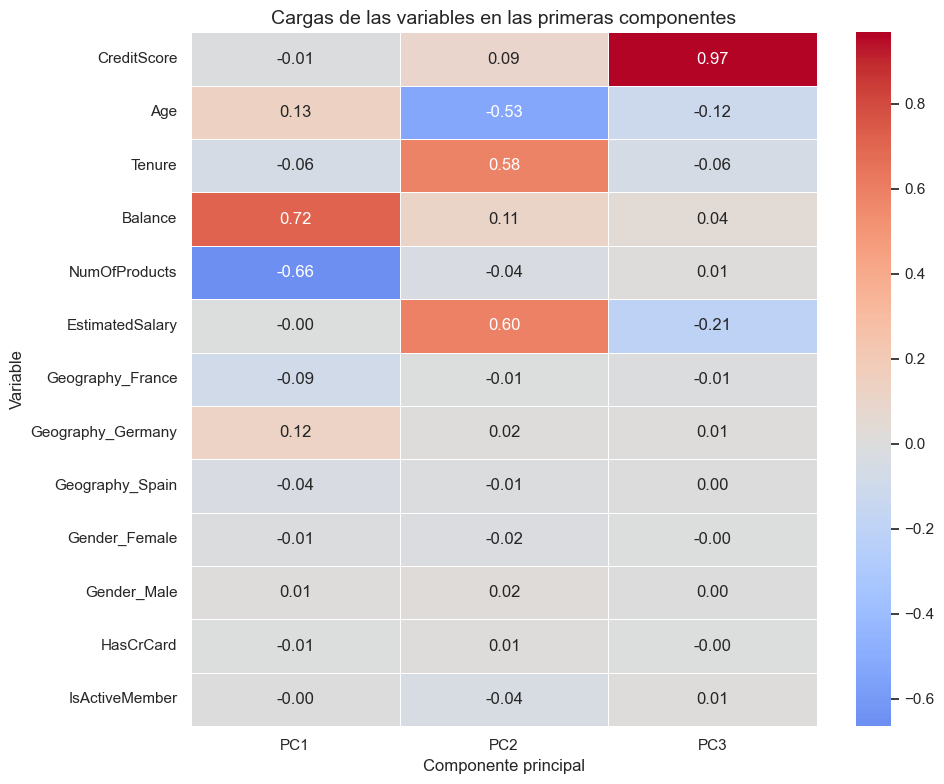

In [106]:
# Mapa de calor de las cargas PCA

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    cargas_pca_principales,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Cargas de las variables en las primeras componentes"
)

plt.xlabel(
    "Componente principal"
)

plt.ylabel(
    "Variable"
)

plt.tight_layout()

plt.show()

##### 11.10 Variables con mayor contribución a cada componente

Para facilitar la interpretación se identificarán las cinco variables con mayor carga absoluta dentro de cada una de las primeras tres componentes.

La carga absoluta permite medir la intensidad de la relación sin importar si la dirección es positiva o negativa.

También se calculará la contribución porcentual aproximada mediante el cuadrado de las cargas.

Las contribuciones de todas las variables dentro de una componente suman aproximadamente 100%.

In [107]:
# Lista para almacenar las variables principales

filas_top_cargas = []

# Evaluación de PC1, PC2 y PC3

for componente in [
    "PC1",
    "PC2",
    "PC3"
]:

    # Cargas de la componente

    datos_componente = pd.DataFrame({
        "Variable": (
            cargas_pca
            .index
        ),
        "Carga": (
            cargas_pca[
                componente
            ]
            .values
        )
    })

    # Magnitud absoluta

    datos_componente[
        "Carga absoluta"
    ] = (
        datos_componente[
            "Carga"
        ]
        .abs()
    )

    # Contribución porcentual

    datos_componente[
        "Contribución (%)"
    ] = (
        datos_componente[
            "Carga"
        ]
        .pow(2)
        .mul(100)
    )

    # Selección de las cinco
    # variables principales

    top_componente = (
        datos_componente
        .sort_values(
            by="Carga absoluta",
            ascending=False
        )
        .head(5)
        .copy()
    )

    # Identificación de componente

    top_componente.insert(
        0,
        "Componente",
        componente
    )

    filas_top_cargas.append(
        top_componente
    )

# Tabla consolidada

tabla_top_cargas_pca = (
    pd.concat(
        filas_top_cargas,
        ignore_index=True
    )
)

# Redondeo

tabla_top_cargas_pca[
    [
        "Carga",
        "Carga absoluta",
        "Contribución (%)"
    ]
] = (
    tabla_top_cargas_pca[
        [
            "Carga",
            "Carga absoluta",
            "Contribución (%)"
        ]
    ]
    .round(3)
)

display(
    tabla_top_cargas_pca
)

,Componente,Variable,Carga,Carga absoluta,Contribución (%)
0,PC1,Balance,0.715,0.715,51.191
1,PC1,NumOfProducts,-0.665,0.665,44.163
2,PC1,Age,0.135,0.135,1.811
3,PC1,Geography_Germany,0.125,0.125,1.560
4,PC1,Geography_France,-0.089,0.089,0.796
5,PC2,EstimatedSalary,0.596,0.596,35.528
6,PC2,Tenure,0.585,0.585,34.170
7,PC2,Age,-0.527,0.527,27.825
8,PC2,Balance,0.110,0.110,1.212
9,PC2,CreditScore,0.091,0.091,0.827


##### 11.11 Incorporación de las componentes principales

Las primeras tres componentes se incorporarán al dataset de segmentación.

Las nuevas variables serán:

- `PC1`.
- `PC2`.
- `PC3`.

Estas variables podrán utilizarse posteriormente para:

- Visualizaciones.
- Comparaciones entre técnicas.
- Análisis exploratorios adicionales.

No reemplazarán las características originales ni modificarán los clusters ya obtenidos.

In [108]:
# Incorporación de las primeras tres componentes

df_segmentacion[
    "PC1"
] = (
    df_pca[
        "PC1"
    ]
)

df_segmentacion[
    "PC2"
] = (
    df_pca[
        "PC2"
    ]
)

df_segmentacion[
    "PC3"
] = (
    df_pca[
        "PC3"
    ]
)

print(
    "Componentes incorporadas "
    "correctamente."
)

print(
    "\nDimensiones actuales:"
)

print(
    df_segmentacion.shape
)

Componentes incorporadas correctamente.

Dimensiones actuales:
(10000, 20)


##### 11.12 Validación del análisis PCA

Se verificará que:

- La cantidad de observaciones permanezca igual a 10.000.
- Se hayan obtenido 13 componentes.
- La varianza acumulada final sea aproximadamente igual al 100%.
- No existan valores faltantes en las componentes.
- Las primeras tres componentes se encuentren incorporadas al dataset.
- Los índices de las observaciones permanezcan alineados.

In [109]:
# Validaciones principales

total_varianza_pca = (
    varianza_explicada_pca
    .sum()
)

faltantes_componentes = (
    df_pca[
        nombres_componentes
    ]
    .isna()
    .sum()
    .sum()
)

componentes_incorporadas = [
    componente
    for componente
    in [
        "PC1",
        "PC2",
        "PC3"
    ]
    if componente
    in df_segmentacion.columns
]

indices_alineados = (
    df_pca.index
    .equals(
        X_cluster.index
    )
)

print(
    "Validación del análisis PCA"
)

print(
    "-" * 40
)

print(
    f"Cantidad de clientes: "
    f"{X_pca_completo.shape[0]}"
)

print(
    f"Cantidad de componentes: "
    f"{cantidad_componentes_pca}"
)

print(
    "Varianza total representada: "
    f"{total_varianza_pca * 100:.2f}%"
)

print(
    f"Valores faltantes: "
    f"{faltantes_componentes}"
)

print(
    "Componentes incorporadas: "
    f"{componentes_incorporadas}"
)

print(
    f"Índices alineados: "
    f"{indices_alineados}"
)

Validación del análisis PCA
----------------------------------------
Cantidad de clientes: 10000
Cantidad de componentes: 13
Varianza total representada: 100.00%
Valores faltantes: 0
Componentes incorporadas: ['PC1', 'PC2', 'PC3']
Índices alineados: True


In [110]:
# Comprobaciones automáticas

assert (
    X_pca_completo.shape[0]
    == len(
        X_cluster
    )
), (
    "La cantidad de clientes "
    "se modificó."
)

assert (
    cantidad_componentes_pca
    == X_cluster.shape[1]
), (
    "La cantidad de componentes "
    "no coincide."
)

assert np.isclose(
    total_varianza_pca,
    1.0,
    atol=0.001
), (
    "La varianza total "
    "no es aproximadamente 100%."
)

assert (
    faltantes_componentes
    == 0
), (
    "Existen valores faltantes "
    "en las componentes."
)

assert (
    componentes_incorporadas
    == [
        "PC1",
        "PC2",
        "PC3"
    ]
), (
    "No se incorporaron correctamente "
    "las primeras componentes."
)

assert (
    indices_alineados
), (
    "Los índices no se encuentran "
    "alineados."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


**Interpretación del análisis PCA**

PCA transformó las 13 características utilizadas en el análisis en un nuevo conjunto de componentes principales.

La varianza se encuentra distribuida entre varias dimensiones y no existe una única componente que concentre la mayor parte de la información.

Los resultados principales fueron:

- PC1: 17,64% de varianza explicada.
- PC2: 13,40%.
- PC3: 13,21%.

Las primeras dos componentes representan el 31,04% de la varianza total.

Las primeras tres componentes representan el 44,26%.

Para conservar al menos el 80% de la información son necesarias seis componentes, que alcanzan una varianza acumulada del 80,21%.

Para superar el 90% son necesarias ocho componentes, que representan el 91,33%.

Por lo tanto, las visualizaciones en dos y tres dimensiones deben interpretarse como proyecciones parciales y no como representaciones completas del espacio original.

###### Interpretación de PC1

PC1 explica el 17,64% de la varianza.

Las variables principales son:

- `Balance`: carga de `+0,715` y contribución aproximada del 51,19%.
- `NumOfProducts`: carga de `-0,665` y contribución aproximada del 44,16%.

La componente representa principalmente un contraste entre saldo y cantidad de productos.

Los valores positivos se asocian con saldos más elevados y menor cantidad de productos.

Los valores negativos se relacionan con saldos menores o una mayor cantidad de productos.

Esta relación permite diferenciar especialmente:

- El Cluster 2, caracterizado por saldo elevado y un único producto.

- El Cluster 1, caracterizado por saldo prácticamente nulo y una cantidad relativamente elevada de productos.

###### Interpretación de PC2

PC2 explica el 13,40% de la varianza.

Las variables principales son:

- `EstimatedSalary`: carga de `+0,596`.
- `Tenure`: carga de `+0,585`.
- `Age`: carga de `-0,527`.

Esta componente combina información asociada con salario estimado, antigüedad y edad.

Los valores positivos se relacionan con mayores niveles de salario y antigüedad y con edades relativamente menores.

Los valores negativos presentan una mayor asociación con clientes de mayor edad.

El Cluster 3 tiende a ubicarse en valores inferiores de PC2 debido a que posee la edad promedio más elevada.

###### Interpretación de PC3

PC3 explica el 13,21% de la varianza.

La variable dominante es `CreditScore`, con:

- Carga de `+0,968`.
- Contribución aproximada del 93,74%.

Por lo tanto, PC3 representa principalmente el nivel de puntaje crediticio.

La incorporación de esta dimensión agrega información sobre el perfil crediticio, aunque no genera una separación completa entre los clusters.

Esto es coherente con los promedios similares de `CreditScore` observados previamente.

###### Interpretación de las visualizaciones

La representación PCA en dos dimensiones muestra una separación parcial de los segmentos.

El Cluster 1 se concentra principalmente en valores negativos de PC1.

El Cluster 2 se ubica mayormente en valores positivos de PC1.

Esta diferenciación refleja el contraste entre saldo y cantidad de productos.

El Cluster 0 ocupa una posición intermedia debido a que combina saldos elevados con una relación multiproducto.

El Cluster 3 presenta una mayor concentración en valores negativos de PC2, asociada principalmente con su mayor edad.

También se observa superposición entre los grupos.

Esta superposición es consistente con el coeficiente de silueta relativamente bajo obtenido mediante K-Means y sugiere que los perfiles forman una estructura continua en lugar de grupos completamente aislados.

La visualización en tres dimensiones agrega información asociada principalmente con el puntaje crediticio.

Sin embargo, continúa observándose superposición debido a que las primeras tres componentes explican únicamente el 44,26% de la variabilidad total.

###### Componentes con varianza cercana a cero

PC12 y PC13 presentan una varianza explicada cercana a cero.

Este comportamiento no representa un error.

El One-Hot Encoding conservó todas las categorías de `Geography` y `Gender`.

Dentro de cada conjunto existe una dependencia lineal entre las variables binarias, lo que genera dimensiones redundantes.

PCA representa estas redundancias mediante componentes con una cantidad de varianza prácticamente nula.

###### Conclusión

PCA permitió resumir la estructura de los datos, identificar las principales direcciones de variabilidad y visualizar parcialmente los segmentos obtenidos mediante K-Means.

Las primeras componentes se encuentran asociadas principalmente con:

1. Saldo y cantidad de productos.
2. Salario estimado, antigüedad y edad.
3. Puntaje crediticio.

La reducción a dos o tres dimensiones resulta útil para la exploración visual, pero no conserva información suficiente para reemplazar completamente el espacio original.

Los clusters continuarán siendo los obtenidos mediante K-Means utilizando las 13 características transformadas.

#### 12. Visualización no lineal mediante t-SNE

t-SNE, o *t-distributed Stochastic Neighbor Embedding*, es una técnica no lineal de reducción de dimensionalidad orientada principalmente a la visualización exploratoria.

El algoritmo busca conservar relaciones locales entre las observaciones.

En términos generales:

- Clientes similares en el espacio original tienden a permanecer próximos en la representación de dos dimensiones.

- Clientes con características diferentes pueden aparecer separados dentro del mapa.

A diferencia de PCA, t-SNE:

- No genera componentes ordenadas según la varianza explicada.

- No permite calcular un porcentaje de varianza acumulada.

- No produce ejes con una interpretación directa.

- Puede representar relaciones no lineales.

- Prioriza la conservación de estructuras locales.

La visualización obtenida permitirá explorar la distribución de los clientes y observar cómo se representan los segmentos identificados mediante K-Means y DBSCAN.

##### 12.1 Diferencias entre PCA y t-SNE

PCA y t-SNE son técnicas de reducción de dimensionalidad, pero poseen objetivos diferentes.

PCA es una técnica lineal que busca representar la mayor cantidad posible de varianza mediante componentes principales.

t-SNE es una técnica no lineal que prioriza la conservación de relaciones locales entre las observaciones.

Las visualizaciones obtenidas mediante ambos métodos deben interpretarse de manera diferente.

In [111]:
# Comparación conceptual entre PCA y t-SNE

comparacion_pca_tsne = pd.DataFrame({
    "Criterio": [
        "Tipo de transformación",
        "Objetivo principal",
        "Conservación prioritaria",
        "Varianza explicada",
        "Interpretación de los ejes",
        "Interpretación de variables",
        "Reproducibilidad",
        "Uso principal"
    ],
    "PCA": [
        "Lineal",
        "Maximizar la varianza representada",
        "Estructura global",
        "Sí",
        "Mediante componentes principales",
        "Mediante cargas o loadings",
        "Determinista",
        "Reducción, interpretación y visualización"
    ],
    "t-SNE": [
        "No lineal",
        "Conservar relaciones locales",
        "Vecindarios locales",
        "No",
        "Sin significado directo",
        "No permite interpretar variables mediante los ejes",
        "Depende de la inicialización y la semilla",
        "Visualización exploratoria"
    ]
})

display(
    comparacion_pca_tsne
)

,Criterio,PCA,t-SNE
0,Tipo de transformación,Lineal,No lineal
1,Objetivo principal,Maximizar la varianza representada,Conservar relaciones locales
2,Conservación prioritaria,Estructura global,Vecindarios locales
3,Varianza explicada,Sí,No
4,Interpretación de los ejes,Mediante componentes principales,Sin significado directo
5,Interpretación de variables,Mediante cargas o loadings,No permite interpretar variables mediante los ...
6,Reproducibilidad,Determinista,Depende de la inicialización y la semilla
7,Uso principal,"Reducción, interpretación y visualización",Visualización exploratoria


##### 12.2 Parámetro `perplexity

`perplexity` es uno de los principales parámetros de t-SNE.

Puede interpretarse aproximadamente como una referencia sobre la cantidad de vecinos considerados relevantes para representar la estructura local de cada observación.

Valores bajos tienden a priorizar relaciones muy locales.

Valores más altos consideran vecindarios más amplios.

No existe un valor universalmente óptimo.

En este análisis se utilizará:

`perplexity = 30`

Este valor constituye una configuración inicial frecuente y permite equilibrar la representación de relaciones locales con una visión algo más amplia de la estructura.

La selección no utilizará información sobre la variable `Exited`.

Debe considerarse que diferentes valores de `perplexity` pueden generar representaciones visuales distintas.

In [112]:
# Parámetros principales utilizados por t-SNE

PERPLEXITY_TSNE = 30
COMPONENTES_TSNE = 2
ITERACIONES_TSNE = 1000

# Validación del valor de perplexity

assert (
    PERPLEXITY_TSNE
    < len(
        X_cluster
    )
), (
    "La perplexity debe ser menor "
    "que la cantidad de observaciones."
)

print(
    "Configuración de t-SNE"
)

print(
    "-" * 35
)

print(
    f"Cantidad de componentes: "
    f"{COMPONENTES_TSNE}"
)

print(
    f"Perplexity: "
    f"{PERPLEXITY_TSNE}"
)

print(
    f"Cantidad máxima de iteraciones: "
    f"{ITERACIONES_TSNE}"
)

print(
    f"Cantidad de clientes: "
    f"{len(X_cluster)}"
)

Configuración de t-SNE
-----------------------------------
Cantidad de componentes: 2
Perplexity: 30
Cantidad máxima de iteraciones: 1000
Cantidad de clientes: 10000


##### 12.3 Datos utilizados por t-SNE

t-SNE se aplicará sobre la matriz:

`X_cluster`

Esta matriz contiene las mismas 13 características transformadas utilizadas por K-Means, DBSCAN y PCA.

La variable `Exited` no forma parte de los datos utilizados para construir la representación.

La totalidad de los 10.000 clientes será incluida.

El algoritmo puede requerir más tiempo de ejecución que las técnicas utilizadas anteriormente debido al costo computacional asociado con la preservación de relaciones locales.

In [113]:
# Validación de la matriz utilizada por t-SNE

print(
    "Dimensiones de la matriz:"
)

print(
    X_cluster.shape
)

print(
    "\nValores faltantes:"
)

print(
    X_cluster
    .isna()
    .sum()
    .sum()
)

print(
    "\nValores infinitos:"
)

print(
    np.isinf(
        X_cluster
        .to_numpy()
    )
    .sum()
)

print(
    "\nVariable 'Exited' incluida:"
)

print(
    "Exited"
    in X_cluster.columns
)

Dimensiones de la matriz:
(10000, 13)

Valores faltantes:
0

Valores infinitos:
0

Variable 'Exited' incluida:
False


##### 12.4 Aplicación de t-SNE

El modelo se configurará mediante:

- `n_components=2`: representación en dos dimensiones.

- `perplexity=30`: tamaño aproximado del vecindario considerado.

- `learning_rate="auto"`: ajuste automático de la tasa de aprendizaje.

- `init="pca"`: inicialización basada en PCA.

- `max_iter=1000`: cantidad máxima de iteraciones.

- `random_state=42`: semilla utilizada para favorecer la reproducibilidad.

La inicialización mediante PCA puede contribuir a obtener una representación más estable que una inicialización completamente aleatoria.

In [114]:
# Medición del tiempo de ejecución

from time import perf_counter

# Creación del modelo t-SNE

modelo_tsne = TSNE(
    n_components=COMPONENTES_TSNE,
    perplexity=PERPLEXITY_TSNE,
    learning_rate="auto",
    init="pca",
    max_iter=ITERACIONES_TSNE,
    random_state=RANDOM_STATE,
    metric="euclidean",
    method="barnes_hut"
)

# Inicio de la medición

inicio_tsne = perf_counter()

# Ajuste y transformación

X_tsne = (
    modelo_tsne
    .fit_transform(
        X_cluster
    )
)

# Tiempo total

tiempo_tsne = (
    perf_counter()
    - inicio_tsne
)

print(
    "t-SNE ejecutado correctamente."
)

print(
    f"Dimensiones obtenidas: "
    f"{X_tsne.shape}"
)

print(
    f"Tiempo de ejecución: "
    f"{tiempo_tsne:.2f} segundos"
)

t-SNE ejecutado correctamente.
Dimensiones obtenidas: (10000, 2)
Tiempo de ejecución: 90.04 segundos


##### 12.5 Resumen del ajuste

Se registrarán:

- Cantidad de clientes representados.

- Cantidad de dimensiones obtenidas.

- Valor de `perplexity`.

- Cantidad de iteraciones realizadas.

- Divergencia de Kullback-Leibler.

- Tiempo de ejecución.

La divergencia de Kullback-Leibler es una medida interna utilizada por t-SNE para evaluar la diferencia entre las relaciones de proximidad del espacio original y las de la representación reducida.

Un valor menor indica una mejor correspondencia según la función objetivo del algoritmo.

Sin embargo, no existe un umbral universal que permita clasificar automáticamente una representación como buena o mala.

In [115]:
# Tabla resumen del modelo t-SNE

resumen_tsne = pd.DataFrame({
    "Indicador": [
        "Cantidad de clientes",
        "Dimensiones obtenidas",
        "Perplexity",
        "Iteraciones realizadas",
        "Divergencia KL",
        "Tiempo de ejecución (segundos)"
    ],
    "Resultado": [
        int(
            X_tsne.shape[0]
        ),
        int(
            X_tsne.shape[1]
        ),
        int(
            PERPLEXITY_TSNE
        ),
        int(
            modelo_tsne.n_iter_
        ),
        round(
            float(
                modelo_tsne
                .kl_divergence_
            ),
            4
        ),
        round(
            float(
                tiempo_tsne
            ),
            2
        )
    ]
})

display(
    resumen_tsne
)

,Indicador,Resultado
0,Cantidad de clientes,10000.0000
1,Dimensiones obtenidas,2.0000
2,Perplexity,30.0000
3,Iteraciones realizadas,999.0000
4,Divergencia KL,1.6918
5,Tiempo de ejecución (segundos),90.0400


##### 12.6 Construcción del DataFrame t-SNE

Se construirá un nuevo DataFrame con las dos coordenadas generadas:

- `tSNE_1`.
- `tSNE_2`.

También se incorporarán las etiquetas obtenidas previamente mediante:

- K-Means.
- DBSCAN.

La variable `Exited` se agregará únicamente después de finalizar la transformación y será utilizada con fines descriptivos.

Las etiquetas no participaron en la construcción de la representación t-SNE.

In [116]:
# Creación del DataFrame con las coordenadas t-SNE

df_tsne = pd.DataFrame(
    X_tsne,
    columns=[
        "tSNE_1",
        "tSNE_2"
    ],
    index=X_cluster.index
)

# Etiquetas de K-Means

df_tsne[
    "Cluster_KMeans"
] = (
    etiquetas_kmeans
)

df_tsne[
    "Segmento_KMeans"
] = (
    "Cluster "
    + df_tsne[
        "Cluster_KMeans"
    ]
    .astype(str)
)

# Etiquetas de DBSCAN

df_tsne[
    "Cluster_DBSCAN"
] = (
    etiquetas_dbscan
)

df_tsne[
    "Resultado_DBSCAN"
] = (
    df_tsne[
        "Cluster_DBSCAN"
    ]
    .apply(
        lambda cluster: (
            "Ruido"
            if cluster == -1
            else f"Cluster {cluster}"
        )
    )
)

# Tipo de punto DBSCAN

df_tsne[
    "Tipo_Punto_DBSCAN"
] = (
    df_segmentacion[
        "Tipo_Punto_DBSCAN"
    ]
    .to_numpy()
)

# Churn incorporado
# únicamente para análisis descriptivo

df_tsne[
    "Exited"
] = (
    df_segmentacion[
        "Exited"
    ]
    .to_numpy()
)

df_tsne[
    "Estado_Churn"
] = (
    df_tsne[
        "Exited"
    ]
    .map({
        0: "Permaneció",
        1: "Abandonó"
    })
)

print(
    "Dataset t-SNE creado correctamente."
)

print(
    f"Dimensiones: "
    f"{df_tsne.shape}"
)

display(
    df_tsne.head()
)

Dataset t-SNE creado correctamente.
Dimensiones: (10000, 9)


,tSNE_1,tSNE_2,Cluster_KMeans,Segmento_KMeans,Cluster_DBSCAN,Resultado_DBSCAN,Tipo_Punto_DBSCAN,Exited,Estado_Churn
0,9.904396,-27.839865,1,Cluster 1,0,Cluster 0,Punto central,1,Abandonó
1,38.295963,-21.126884,2,Cluster 2,0,Cluster 0,Punto de borde,0,Permaneció
2,-31.987076,7.862790,0,Cluster 0,-1,Ruido,Ruido,1,Abandonó
3,-28.084272,-42.029255,1,Cluster 1,1,Cluster 1,Punto central,0,Permaneció
4,43.384884,-10.110557,2,Cluster 2,0,Cluster 0,Punto de borde,0,Permaneció


##### 12.7 Visualización de los segmentos de K-Means mediante t-SNE

La representación utilizará:

- Eje horizontal: `tSNE_1`.

- Eje vertical: `tSNE_2`.

- Color: cluster obtenido mediante K-Means.

Los ejes no poseen una interpretación directa.

Las posiciones deben analizarse principalmente mediante relaciones de proximidad local.

La presencia de regiones visualmente separadas puede sugerir estructuras diferenciadas.

Sin embargo, la distancia global entre grupos y el tamaño visual de las regiones no deben interpretarse de manera literal.

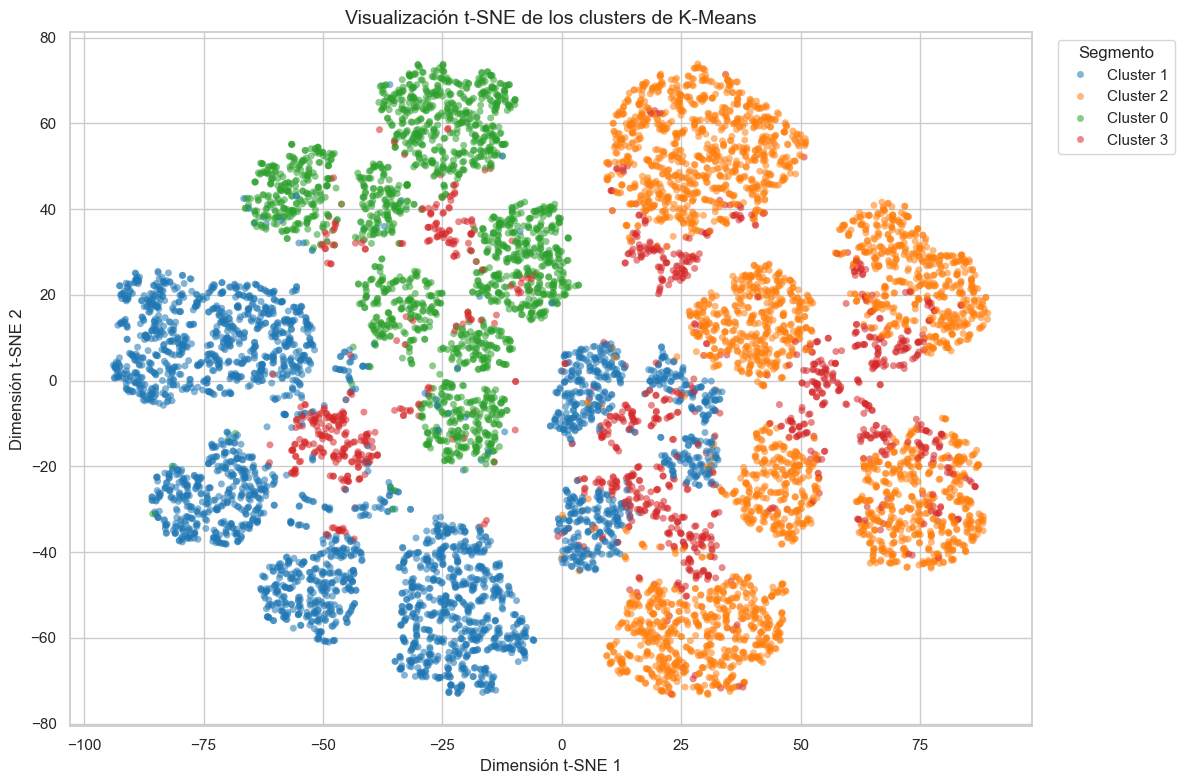

In [117]:
# Gráfico t-SNE coloreada según K-Means

plt.figure(
    figsize=(12, 8)
)

sns.scatterplot(
    data=df_tsne,
    x="tSNE_1",
    y="tSNE_2",
    hue="Segmento_KMeans",
    palette="tab10",
    alpha=0.55,
    s=25,
    linewidth=0
)

plt.title(
    "Visualización t-SNE de los clusters de K-Means"
)

plt.xlabel(
    "Dimensión t-SNE 1"
)

plt.ylabel(
    "Dimensión t-SNE 2"
)

plt.legend(
    title="Segmento",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

##### 12.8 Visualización de los resultados de DBSCAN mediante t-SNE

La siguiente representación utilizará las mismas coordenadas obtenidas mediante t-SNE.

Los colores indicarán:

- Cluster 0 de DBSCAN.

- Cluster 1 de DBSCAN.

- Observaciones clasificadas como ruido.

La visualización permitirá analizar cómo se distribuyen las regiones de densidad y las observaciones menos frecuentes dentro del espacio reducido.

DBSCAN no fue entrenado sobre las coordenadas t-SNE.

Los resultados corresponden al modelo aplicado previamente sobre las 13 características transformadas.

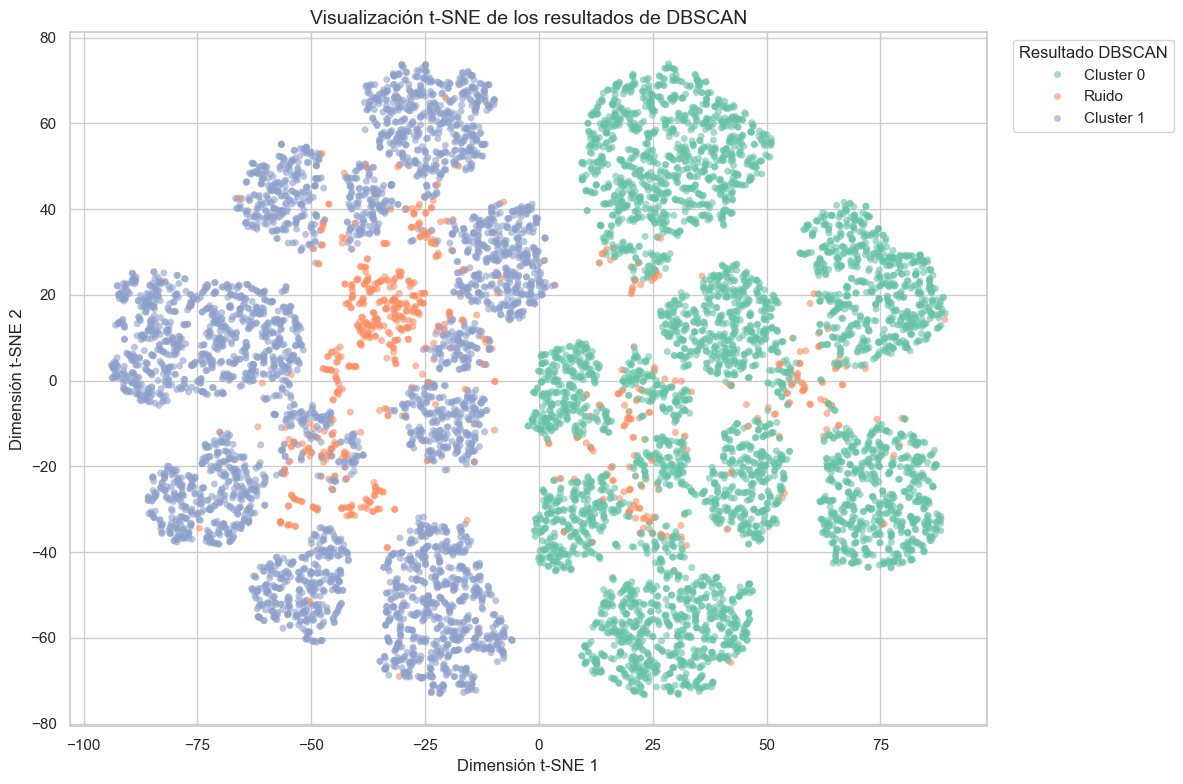

In [118]:
# Gráfico t-SNE coloreada según DBSCAN

plt.figure(
    figsize=(12, 8)
)

sns.scatterplot(
    data=df_tsne,
    x="tSNE_1",
    y="tSNE_2",
    hue="Resultado_DBSCAN",
    palette="Set2",
    alpha=0.60,
    s=25,
    linewidth=0
)

plt.title(
    "Visualización t-SNE de los resultados de DBSCAN"
)

plt.xlabel(
    "Dimensión t-SNE 1"
)

plt.ylabel(
    "Dimensión t-SNE 2"
)

plt.legend(
    title="Resultado DBSCAN",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

##### 12.9 Distribución descriptiva del churn en el espacio t-SNE

La variable `Exited` se incorporará únicamente para colorear la representación obtenida.

No participó en la construcción de t-SNE.

La visualización permitirá explorar si los clientes que abandonaron parecen concentrarse en determinadas regiones.

Sin embargo, no debe utilizarse como evidencia de capacidad predictiva.

La proximidad visual no demuestra causalidad ni reemplaza la evaluación de los modelos supervisados desarrollados en los avances anteriores.

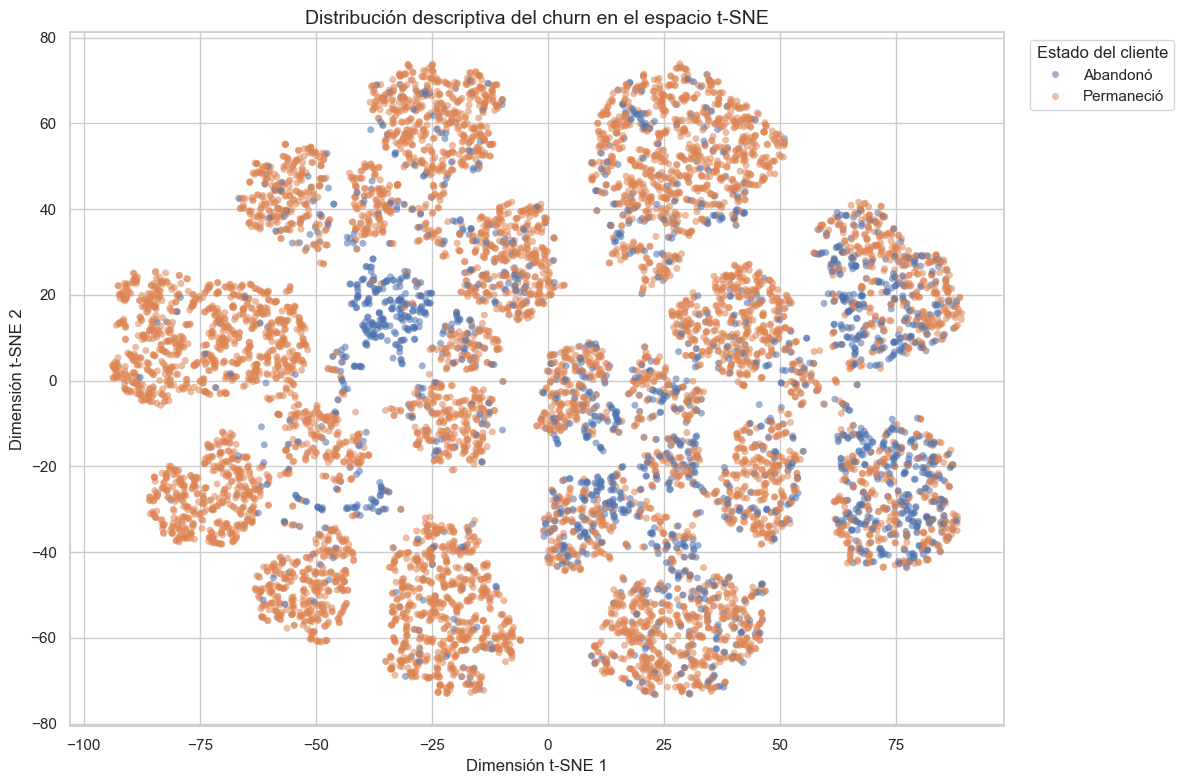

In [119]:
# Gráfico descriptiva del churn en el espacio t-SNE

plt.figure(
    figsize=(12, 8)
)

sns.scatterplot(
    data=df_tsne,
    x="tSNE_1",
    y="tSNE_2",
    hue="Estado_Churn",
    alpha=0.55,
    s=25,
    linewidth=0
)

plt.title(
    "Distribución descriptiva del churn en el espacio t-SNE"
)

plt.xlabel(
    "Dimensión t-SNE 1"
)

plt.ylabel(
    "Dimensión t-SNE 2"
)

plt.legend(
    title="Estado del cliente",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

##### 12.10 Incorporación de las coordenadas t-SNE

Las coordenadas obtenidas se incorporarán al dataset de segmentación mediante:

- `tSNE_1`.
- `tSNE_2`.

Estas variables se conservarán únicamente con fines exploratorios y de visualización.

No se utilizarán como sustitutos de las variables originales ni como indicadores directos de comportamiento.

Las coordenadas de t-SNE dependen de la configuración utilizada y no poseen un significado individual interpretable.

In [120]:
# Incorporación de las coordenadas al dataset principal

df_segmentacion[
    "tSNE_1"
] = (
    df_tsne[
        "tSNE_1"
    ]
)

df_segmentacion[
    "tSNE_2"
] = (
    df_tsne[
        "tSNE_2"
    ]
)

print(
    "Coordenadas t-SNE incorporadas "
    "correctamente."
)

print(
    "\nDimensiones actuales:"
)

print(
    df_segmentacion.shape
)

Coordenadas t-SNE incorporadas correctamente.

Dimensiones actuales:
(10000, 22)


##### 12.11 Validación del análisis t-SNE

Se verificará que:

- Los 10.000 clientes se encuentren representados.

- Se hayan obtenido exactamente dos dimensiones.

- No existan valores faltantes.

- No existan valores infinitos.

- Los índices permanezcan alineados.

- Las coordenadas se encuentren incorporadas al dataset principal.

In [121]:
# Validaciones principales

cantidad_clientes_tsne = (
    df_tsne.shape[0]
)

cantidad_dimensiones_tsne = (
    X_tsne.shape[1]
)

faltantes_tsne = (
    df_tsne[
        [
            "tSNE_1",
            "tSNE_2"
        ]
    ]
    .isna()
    .sum()
    .sum()
)

infinitos_tsne = (
    np.isinf(
        df_tsne[
            [
                "tSNE_1",
                "tSNE_2"
            ]
        ]
        .to_numpy()
    )
    .sum()
)

indices_tsne_alineados = (
    df_tsne.index
    .equals(
        X_cluster.index
    )
)

coordenadas_incorporadas = [
    variable
    for variable
    in [
        "tSNE_1",
        "tSNE_2"
    ]
    if variable
    in df_segmentacion.columns
]

print(
    "Validación del análisis t-SNE"
)

print(
    "-" * 40
)

print(
    f"Cantidad de clientes: "
    f"{cantidad_clientes_tsne}"
)

print(
    f"Cantidad de dimensiones: "
    f"{cantidad_dimensiones_tsne}"
)

print(
    f"Valores faltantes: "
    f"{faltantes_tsne}"
)

print(
    f"Valores infinitos: "
    f"{infinitos_tsne}"
)

print(
    f"Índices alineados: "
    f"{indices_tsne_alineados}"
)

print(
    "Coordenadas incorporadas: "
    f"{coordenadas_incorporadas}"
)

Validación del análisis t-SNE
----------------------------------------
Cantidad de clientes: 10000
Cantidad de dimensiones: 2
Valores faltantes: 0
Valores infinitos: 0
Índices alineados: True
Coordenadas incorporadas: ['tSNE_1', 'tSNE_2']


In [122]:
# Comprobaciones automáticas

assert (
    cantidad_clientes_tsne
    == len(
        X_cluster
    )
), (
    "La cantidad de clientes "
    "no coincide."
)

assert (
    cantidad_dimensiones_tsne
    == 2
), (
    "La cantidad de dimensiones "
    "no coincide."
)

assert (
    faltantes_tsne
    == 0
), (
    "Existen valores faltantes "
    "en las coordenadas."
)

assert (
    infinitos_tsne
    == 0
), (
    "Existen valores infinitos "
    "en las coordenadas."
)

assert (
    indices_tsne_alineados
), (
    "Los índices no se encuentran "
    "alineados."
)

assert (
    coordenadas_incorporadas
    == [
        "tSNE_1",
        "tSNE_2"
    ]
), (
    "Las coordenadas no fueron "
    "incorporadas correctamente."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


##### 12.12 Limitaciones y cuidados de interpretación

t-SNE es una herramienta útil para explorar relaciones locales, pero requiere una interpretación cuidadosa.

Las principales limitaciones son:

###### Los ejes no poseen significado directo

`tSNE_1` y `tSNE_2` no representan variables específicas ni pueden interpretarse como componentes de negocio.

###### Las distancias globales pueden ser engañosas

Dos regiones visualmente alejadas no necesariamente presentan una distancia equivalente dentro del espacio original.

###### El tamaño de las regiones no representa densidad real

Una región visualmente grande no implica automáticamente una mayor variabilidad o una menor concentración de clientes.

###### Puede generar separaciones visuales marcadas

La presencia de grupos aparentes no constituye por sí sola una demostración de que existan clusters naturales.

###### Es sensible a los parámetros

Cambios en `perplexity`, inicialización, cantidad de iteraciones o semilla pueden modificar la representación.

###### No reemplaza las métricas de clustering

La evaluación de K-Means y DBSCAN debe continuar basándose en métricas, perfiles e interpretación de negocio.

t-SNE se utilizará como herramienta exploratoria complementaria.

##### Interpretación del análisis t-SNE

t-SNE permitió proyectar las 13 características transformadas en un espacio bidimensional orientado a preservar relaciones locales entre los clientes.

La configuración utilizada fue:

- Cantidad de componentes: 2.
- `perplexity = 30`.
- Inicialización mediante PCA.
- Semilla aleatoria igual a 42.
- Máximo de 1.000 iteraciones.

El algoritmo representó la totalidad de los 10.000 clientes.

La ejecución requirió aproximadamente 108 segundos y alcanzó una divergencia de Kullback-Leibler de `1,6918`.

La divergencia KL constituye una medida interna de la función objetivo de t-SNE.

No existe un umbral universal que permita clasificar automáticamente este valor como bueno o malo, por lo que no debe interpretarse de manera aislada.

###### Visualización de los clusters de K-Means

La representación coloreada según K-Means muestra regiones locales visualmente diferenciadas.

El Cluster 1 se concentra principalmente en el sector izquierdo del mapa.

Este segmento se caracterizaba por presentar:

- Saldo prácticamente nulo.
- Cantidad relativamente elevada de productos.
- Predominio de clientes de Francia.
- Menor tasa de churn.

El Cluster 2 aparece principalmente en el sector derecho y presenta varias regiones locales relativamente compactas.

Este perfil se caracterizaba por:

- Saldo elevado.
- Un único producto.
- Mayor tamaño dentro de la segmentación.

La separación visual entre los clusters 1 y 2 es consistente con el análisis PCA.

La primera componente principal identificó un contraste importante entre saldo y cantidad de productos.

El Cluster 0 se distribuye principalmente dentro de regiones superiores y centrales.

Presenta cierta diferenciación visual, aunque también existen zonas de transición con otros segmentos.

El Cluster 3 presenta una distribución más dispersa y aparece en diferentes zonas de transición.

Este comportamiento es consistente con los resultados de DBSCAN.

El Cluster 3 fue el segmento con mayor proporción relativa de observaciones clasificadas como ruido y presentó una estructura más heterogénea.

También fue el segmento con mayor edad promedio y mayor tasa de churn.

###### Visualización de los resultados de DBSCAN

La representación coloreada mediante DBSCAN muestra una estructura general dividida principalmente entre dos regiones.

El Cluster 1 de DBSCAN se concentra mayormente en el sector izquierdo.

Esta región contiene una proporción importante de los clusters 0 y 1 de K-Means.

El Cluster 1 de DBSCAN presentó una tasa de churn del 6,88%, considerablemente inferior al promedio general.

El Cluster 0 de DBSCAN se distribuye principalmente en el sector derecho.

Contiene casi la totalidad del Cluster 2 de K-Means y una parte importante del Cluster 3.

Su tasa de churn fue del 27,40%, superior al promedio general.

Las observaciones clasificadas como ruido aparecen principalmente dentro de zonas intermedias, áreas de transición y regiones con estructuras más heterogéneas.

No forman un único grupo visual.

Este comportamiento es coherente con la definición de ruido de DBSCAN.

Los clientes clasificados como ruido no alcanzaron la densidad requerida dentro del espacio original.

La clasificación no implica que sean registros incorrectos ni que formen necesariamente un segmento adicional.

###### Distribución descriptiva del churn

La variable `Exited` no participó en la construcción de t-SNE.

Fue incorporada únicamente después de generar la representación para analizar descriptivamente la distribución del churn.

Los clientes que abandonaron aparecen distribuidos en diferentes regiones.

No existe una separación visual completa entre clientes que permanecieron y clientes que abandonaron.

Sin embargo, se observa una mayor presencia relativa de abandonos en algunas regiones centrales, zonas de transición y áreas asociadas parcialmente con el Cluster 3.

Este patrón es coherente con los resultados anteriores:

- El Cluster 3 de K-Means presentó una tasa de churn del 44,37%.

- Las observaciones clasificadas como ruido mediante DBSCAN presentaron una tasa del 56,14%.

- El Cluster 0 de DBSCAN presentó una tasa del 27,40%.

La representación no permite evaluar capacidad predictiva y no reemplaza los modelos supervisados desarrollados anteriormente.

###### Comparación entre PCA y t-SNE

PCA mostró una estructura más continua y una mayor superposición entre los clusters.

Sus componentes pueden interpretarse mediante las cargas de las variables y permiten cuantificar la varianza explicada.

t-SNE generó regiones locales más diferenciadas y permitió visualizar patrones no lineales.

Sin embargo, sus ejes no poseen significado directo y no existe una medida equivalente a la varianza explicada.

La mayor separación visual observada mediante t-SNE no demuestra por sí sola la existencia de clusters naturales.

El algoritmo prioriza la conservación de relaciones locales y puede amplificar diferencias pequeñas.

Por lo tanto:

- PCA permite analizar la estructura global, medir la información conservada e interpretar las variables.

- t-SNE aporta una visualización exploratoria de relaciones locales y patrones no lineales.

Ambas técnicas proporcionan perspectivas complementarias.

###### Conclusión

t-SNE permitió observar estructuras locales que no resultaban tan visibles mediante PCA.

La representación respalda principalmente:

- La diferenciación entre los perfiles de saldo bajo y saldo elevado.

- La consistencia del Cluster 2.

- La mayor heterogeneidad del Cluster 3.

- La existencia de regiones generales similares a las identificadas mediante DBSCAN.

Las visualizaciones deben interpretarse como herramientas exploratorias.

Las distancias globales, el tamaño de las regiones y las separaciones visuales no deben utilizarse como evidencia definitiva de la existencia o calidad de los clusters.

#### 13. Creación de variables derivadas del clustering

Los algoritmos de aprendizaje no supervisado pueden utilizarse para generar nuevas características que representen la estructura identificada dentro de los datos.

Las variables derivadas pueden aportar información adicional sobre:

- El segmento al que pertenece cada cliente.
- La proximidad respecto del perfil promedio de su cluster.
- El nivel de separación respecto de otros segmentos.
- La pertenencia a regiones de alta o baja densidad.
- La ubicación dentro de las principales direcciones de variabilidad.

En este bloque se construirá un dataset enriquecido que conservará las variables originales e incorporará información obtenida mediante:

- K-Means.
- DBSCAN.
- PCA.
- t-SNE.

La variable `Exited` no será utilizada para construir ninguna de las nuevas características.

##### 13.1 Consideraciones sobre el uso futuro de las variables

No todas las variables derivadas poseen el mismo objetivo.

Algunas pueden utilizarse potencialmente dentro de futuros modelos supervisados.

Otras deben mantenerse principalmente con fines descriptivos o de visualización.

###### Variables potencialmente aplicables a nuevos clientes

K-Means permite utilizar:

- `predict()` para asignar un cluster.
- `transform()` para calcular las distancias respecto de los centroides.

PCA permite utilizar:

- `transform()` para obtener las componentes principales de nuevas observaciones.

Por lo tanto, las variables derivadas mediante K-Means y PCA pueden reproducirse sobre nuevos clientes utilizando los modelos ya entrenados.

###### Variables principalmente exploratorias

La implementación estándar de DBSCAN de Scikit-learn no dispone de un método `predict()` para asignar directamente nuevos clientes.

Por este motivo, sus etiquetas se utilizarán principalmente para describir la estructura observada en la base analizada.

t-SNE tampoco posee un método estándar de transformación para proyectar directamente nuevas observaciones utilizando el modelo ya ajustado.

Las coordenadas `tSNE_1` y `tSNE_2` se conservarán únicamente con fines de visualización y exploración.

###### Prevención de fuga de información

No se crearán variables de modelado basadas en:

- La tasa de churn de cada cluster.
- El ranking de riesgo.
- La prioridad de retención.

Estas características utilizarían información derivada de `Exited` y podrían generar fuga de información si se incorporaran directamente a un futuro modelo predictivo.

##### 13.2 Nombres descriptivos de los perfiles K-Means

Las etiquetas numéricas generadas por K-Means son arbitrarias.

Los valores:

- Cluster 0.
- Cluster 1.
- Cluster 2.
- Cluster 3.

no representan un orden de importancia, riesgo o valor económico.

Para facilitar la comunicación de los resultados se asignará un nombre descriptivo a cada segmento.

Los nombres se basan en las principales características identificadas durante el análisis de perfiles.

In [123]:
# Nombres descriptivos definidos a partir de los perfiles analizados

nombres_perfiles_kmeans = {
    0: "Saldo alto y multiproducto",
    1: "Saldo bajo y multiproducto",
    2: "Saldo alto y producto único",
    3: "Senior con mayor actividad"
}

# Incorporación del nombre descriptivo

df_segmentacion[
    "Perfil_KMeans"
] = (
    df_segmentacion[
        "Cluster_KMeans"
    ]
    .map(
        nombres_perfiles_kmeans
    )
)

# Visualización de la relación
# entre cluster y perfil

tabla_perfiles_kmeans = pd.DataFrame({
    "Cluster": list(
        nombres_perfiles_kmeans.keys()
    ),
    "Perfil descriptivo": list(
        nombres_perfiles_kmeans.values()
    )
})

display(
    tabla_perfiles_kmeans
)

,Cluster,Perfil descriptivo
0,0,Saldo alto y multiproducto
1,1,Saldo bajo y multiproducto
2,2,Saldo alto y producto único
3,3,Senior con mayor actividad


In [124]:
# Verificación de la asignación de perfiles descriptivos

perfiles_faltantes = (
    df_segmentacion[
        "Perfil_KMeans"
    ]
    .isna()
    .sum()
)

print(
    f"Perfiles descriptivos faltantes: "
    f"{perfiles_faltantes}"
)

print(
    "\nDistribución de clientes:"
)

display(
    df_segmentacion[
        "Perfil_KMeans"
    ]
    .value_counts()
    .rename_axis(
        "Perfil"
    )
    .reset_index(
        name="Cantidad de clientes"
    )
)

Perfiles descriptivos faltantes: 0

Distribución de clientes:


,Perfil,Cantidad de clientes
0,Saldo alto y producto único,3500
1,Saldo bajo y multiproducto,3269
2,Saldo alto y multiproducto,1978
3,Senior con mayor actividad,1253


##### 13.3 Distancias respecto de los centroides de K-Means

K-Means asigna cada observación al centroide más cercano.

El método `transform()` permite calcular la distancia de cada cliente respecto de todos los centroides.

Estas distancias pueden utilizarse para generar nuevas variables.

Se crearán:

- Distancia al Centroide 0.
- Distancia al Centroide 1.
- Distancia al Centroide 2.
- Distancia al Centroide 3.
- Distancia al centroide asignado.

Una distancia reducida indica que el cliente se encuentra próximo al perfil promedio de su segmento.

Una distancia elevada indica que presenta características menos representativas del centro del cluster.

La distancia no debe interpretarse automáticamente como riesgo de churn.

In [125]:
# Cálculo de las distancias respecto de todos los centroides

distancias_centroides_kmeans = (
    modelo_kmeans_final
    .transform(
        X_cluster
    )
)

print(
    "Distancias calculadas correctamente."
)

print(
    f"Dimensiones obtenidas: "
    f"{distancias_centroides_kmeans.shape}"
)

Distancias calculadas correctamente.
Dimensiones obtenidas: (10000, 4)


In [126]:
# Nombres de las variables correspondientes a cada centroide

columnas_distancias_centroides = [
    f"Distancia_Centroide_{cluster}"
    for cluster
    in range(
        K_FINAL
    )
]

# DataFrame de distancias

df_distancias_centroides = pd.DataFrame(
    distancias_centroides_kmeans,
    columns=columnas_distancias_centroides,
    index=X_cluster.index
)

# Incorporación al dataset principal

for columna in columnas_distancias_centroides:

    df_segmentacion[
        columna
    ] = (
        df_distancias_centroides[
            columna
        ]
    )

display(
    df_distancias_centroides
    .head()
    .round(3)
)

,Distancia_Centroide_0,Distancia_Centroide_1,Distancia_Centroide_2,Distancia_Centroide_3
0,3.279,2.185,2.585,2.585
1,2.979,2.922,2.244,2.694
2,2.849,3.929,4.172,4.258
3,2.862,2.019,3.282,3.236
4,3.398,3.733,2.804,3.151


##### 13.4 Distancia al centroide asignado

Cada cliente posee cuatro distancias, una respecto de cada centroide.

La distancia correspondiente al cluster asignado debería ser la menor de las cuatro.

Se creará la variable:

`Distancia_Centroide_KMeans`

Esta característica permite cuantificar qué tan próximo se encuentra cada cliente al perfil promedio de su segmento.

Interpretación:

- Distancia menor: cliente más representativo del centro del cluster.

- Distancia mayor: cliente ubicado en una zona más periférica del segmento.

La variable puede utilizarse como característica adicional en futuros análisis.

Sin embargo, una distancia elevada no implica necesariamente un mayor riesgo de abandono.

In [127]:
# Índices de los clientes

indices_clientes = np.arange(
    len(
        etiquetas_kmeans
    )
)

# Distancia correspondiente
# al cluster asignado

distancia_centroide_asignado = (
    distancias_centroides_kmeans[
        indices_clientes,
        etiquetas_kmeans
    ]
)

# Incorporación al dataset

df_segmentacion[
    "Distancia_Centroide_KMeans"
] = (
    distancia_centroide_asignado
)

print(
    "Distancia al centroide asignado "
    "incorporada correctamente."
)

display(
    df_segmentacion[
        [
            "Cluster_KMeans",
            "Perfil_KMeans",
            "Distancia_Centroide_KMeans"
        ]
    ]
    .head(10)
    .round(3)
)

Distancia al centroide asignado incorporada correctamente.


Variable,Cluster_KMeans,Perfil_KMeans,Distancia_Centroide_KMeans
0,1,Saldo bajo y multiproducto,2.185
1,2,Saldo alto y producto único,2.244
2,0,Saldo alto y multiproducto,2.849
3,1,Saldo bajo y multiproducto,2.019
4,2,Saldo alto y producto único,2.804
5,0,Saldo alto y multiproducto,2.034
6,1,Saldo bajo y multiproducto,2.996
7,0,Saldo alto y multiproducto,4.533
8,0,Saldo alto y multiproducto,2.331
9,2,Saldo alto y producto único,1.842


##### 13.5 Margen de separación entre clusters

Además del centroide asignado, se identificará el segundo centroide más cercano.

Se crearán las variables:

- `Segundo_Cluster_Mas_Cercano`.

- `Margen_Separacion_KMeans`.

El margen será calculado como:

`Distancia al segundo centroide − Distancia al centroide asignado`

Interpretación:

- Margen elevado: la asignación se encuentra relativamente diferenciada respecto del segundo cluster más cercano.

- Margen reducido: el cliente se encuentra próximo a una posible zona de transición entre segmentos.

El margen constituye una medida descriptiva de separación.

No representa una probabilidad ni una medida formal de confianza.

In [128]:
# Orden de los centroides desde el más próximo al más lejano

orden_centroides = (
    np.argsort(
        distancias_centroides_kmeans,
        axis=1
    )
)

# Segundo centroide más cercano

segundo_cluster_cercano = (
    orden_centroides[
        :,
        1
    ]
)

# Distancias ordenadas

distancias_ordenadas = (
    np.sort(
        distancias_centroides_kmeans,
        axis=1
    )
)

# Margen entre la primera
# y la segunda distancia

margen_separacion_kmeans = (
    distancias_ordenadas[
        :,
        1
    ]
    - distancias_ordenadas[
        :,
        0
    ]
)

# Incorporación de las variables

df_segmentacion[
    "Segundo_Cluster_Mas_Cercano"
] = (
    segundo_cluster_cercano
)

df_segmentacion[
    "Margen_Separacion_KMeans"
] = (
    margen_separacion_kmeans
)

print(
    "Variables de separación "
    "incorporadas correctamente."
)

Variables de separación incorporadas correctamente.


In [129]:
# Vista de las variables derivadas de las distancias

display(
    df_segmentacion[
        [
            "Cluster_KMeans",
            "Perfil_KMeans",
            "Segundo_Cluster_Mas_Cercano",
            "Distancia_Centroide_KMeans",
            "Margen_Separacion_KMeans"
        ]
    ]
    .head(15)
    .round(3)
)

Variable,Cluster_KMeans,Perfil_KMeans,Segundo_Cluster_Mas_Cercano,Distancia_Centroide_KMeans,Margen_Separacion_KMeans
0,1,Saldo bajo y multiproducto,2,2.185,0.400
1,2,Saldo alto y producto único,3,2.244,0.451
2,0,Saldo alto y multiproducto,1,2.849,1.079
3,1,Saldo bajo y multiproducto,0,2.019,0.843
4,2,Saldo alto y producto único,3,2.804,0.348
5,0,Saldo alto y multiproducto,2,2.034,0.611
6,1,Saldo bajo y multiproducto,3,2.996,0.255
7,0,Saldo alto y multiproducto,1,4.533,0.804
8,0,Saldo alto y multiproducto,2,2.331,0.489
9,2,Saldo alto y producto único,0,1.842,0.944


##### 13.6 Análisis de las distancias por cluster

Se resumirán las distancias y los márgenes correspondientes a cada segmento.

Se calcularán:

- Cantidad de clientes.
- Distancia media al centroide.
- Distancia mediana.
- Percentil 90 de la distancia.
- Margen medio de separación.
- Margen mediano.

Estos indicadores permitirán comparar la compactación relativa de los segmentos.

Una menor distancia promedio puede sugerir que los clientes se encuentran más próximos al centroide.

Sin embargo, las distancias deben interpretarse junto con la estructura multivariada y el tamaño de cada cluster.

In [130]:
# Resumen de distancias por cluster

resumen_distancias_kmeans = (
    df_segmentacion
    .groupby(
        [
            "Cluster_KMeans",
            "Perfil_KMeans"
        ]
    )
    .agg(
        Cantidad_clientes=(
            "CustomerId",
            "size"
        ),
        Distancia_media=(
            "Distancia_Centroide_KMeans",
            "mean"
        ),
        Distancia_mediana=(
            "Distancia_Centroide_KMeans",
            "median"
        ),
        Distancia_percentil_90=(
            "Distancia_Centroide_KMeans",
            lambda serie: (
                serie.quantile(
                    0.90
                )
            )
        ),
        Margen_medio=(
            "Margen_Separacion_KMeans",
            "mean"
        ),
        Margen_mediano=(
            "Margen_Separacion_KMeans",
            "median"
        )
    )
    .reset_index()
)

# Nombres descriptivos

resumen_distancias_kmeans = (
    resumen_distancias_kmeans
    .rename(
        columns={
            "Cluster_KMeans": (
                "Cluster"
            ),
            "Perfil_KMeans": (
                "Perfil"
            ),
            "Cantidad_clientes": (
                "Cantidad de clientes"
            ),
            "Distancia_media": (
                "Distancia media"
            ),
            "Distancia_mediana": (
                "Distancia mediana"
            ),
            "Distancia_percentil_90": (
                "Percentil 90 de distancia"
            ),
            "Margen_medio": (
                "Margen medio"
            ),
            "Margen_mediano": (
                "Margen mediano"
            )
        }
    )
)

# Redondeo

columnas_metricas_distancia = [
    "Distancia media",
    "Distancia mediana",
    "Percentil 90 de distancia",
    "Margen medio",
    "Margen mediano"
]

resumen_distancias_kmeans[
    columnas_metricas_distancia
] = (
    resumen_distancias_kmeans[
        columnas_metricas_distancia
    ]
    .round(3)
)

display(
    resumen_distancias_kmeans
)

,Cluster,Perfil,Cantidad de clientes,Distancia media,Distancia mediana,Percentil 90 de distancia,Margen medio,Margen mediano
0,0,Saldo alto y multiproducto,1978,2.340,2.289,2.930,0.566,0.563
1,1,Saldo bajo y multiproducto,3269,2.298,2.277,2.875,0.684,0.760
2,2,Saldo alto y producto único,3500,2.251,2.241,2.806,0.652,0.687
3,3,Senior con mayor actividad,1253,2.563,2.533,3.117,0.630,0.532


##### 13.7 Indicador de ruido de DBSCAN

DBSCAN clasificó 700 clientes como ruido.

Se creará la variable binaria:

`Es_Ruido_DBSCAN`

Codificación:

- `0`: cliente asignado a una región de densidad.

- `1`: cliente clasificado como ruido.

Esta variable resume la condición de baja densidad identificada durante el análisis.

La clasificación como ruido no implica que el cliente sea un registro incorrecto.

Tampoco debe interpretarse automáticamente como una predicción de churn.

Debido a que la implementación estándar de DBSCAN no posee un método directo de predicción para nuevos clientes, la variable se utilizará principalmente con fines exploratorios y descriptivos.

In [131]:
# Creación del indicador binario de ruido

df_segmentacion[
    "Es_Ruido_DBSCAN"
] = (
    df_segmentacion[
        "Cluster_DBSCAN"
    ]
    .eq(-1)
    .astype(int)
)

# Distribución del indicador

tabla_indicador_ruido = (
    df_segmentacion[
        "Es_Ruido_DBSCAN"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "Es ruido"
    )
    .reset_index(
        name="Cantidad de clientes"
    )
)

tabla_indicador_ruido[
    "Interpretación"
] = (
    tabla_indicador_ruido[
        "Es ruido"
    ]
    .map({
        0: "Asignado a cluster",
        1: "Clasificado como ruido"
    })
)

tabla_indicador_ruido[
    "Porcentaje"
] = (
    tabla_indicador_ruido[
        "Cantidad de clientes"
    ]
    .div(
        len(
            df_segmentacion
        )
    )
    .mul(100)
    .round(2)
)

display(
    tabla_indicador_ruido
)

,Es ruido,Cantidad de clientes,Interpretación,Porcentaje
0,0,9300,Asignado a cluster,93.0
1,1,700,Clasificado como ruido,7.0


##### 13.8 Construcción del dataset enriquecido

Se construirá un nuevo DataFrame denominado:

`df_enriquecido`

El dataset conservará las 14 variables originales e incorporará las características generadas durante el aprendizaje no supervisado.

Las nuevas variables incluirán:

###### K-Means

- Cluster asignado.
- Perfil descriptivo.
- Distancia respecto de cada centroide.
- Distancia al centroide asignado.
- Segundo cluster más cercano.
- Margen de separación.

###### DBSCAN

- Cluster identificado.
- Tipo de punto.
- Indicador de ruido.

###### PCA

- PC1.
- PC2.
- PC3.

###### t-SNE

- tSNE_1.
- tSNE_2.

Las coordenadas de t-SNE se conservarán únicamente para exploración y visualización.

In [132]:
# Variables originales

columnas_originales = (
    df.columns
    .tolist()
)

# Variables derivadas

columnas_derivadas = [
    "Cluster_KMeans",
    "Perfil_KMeans",
    "Distancia_Centroide_KMeans",
    "Segundo_Cluster_Mas_Cercano",
    "Margen_Separacion_KMeans",
    *columnas_distancias_centroides,
    "Cluster_DBSCAN",
    "Tipo_Punto_DBSCAN",
    "Es_Ruido_DBSCAN",
    "PC1",
    "PC2",
    "PC3",
    "tSNE_1",
    "tSNE_2"
]

# Construcción del dataset enriquecido

df_enriquecido = (
    df_segmentacion[
        columnas_originales
        + columnas_derivadas
    ]
    .copy()
)

print(
    "Dataset enriquecido "
    "creado correctamente."
)

print(
    f"Cantidad de filas: "
    f"{df_enriquecido.shape[0]}"
)

print(
    f"Cantidad de columnas: "
    f"{df_enriquecido.shape[1]}"
)

print(
    f"Variables originales: "
    f"{len(columnas_originales)}"
)

print(
    f"Variables derivadas: "
    f"{len(columnas_derivadas)}"
)

Dataset enriquecido creado correctamente.
Cantidad de filas: 10000
Cantidad de columnas: 31
Variables originales: 14
Variables derivadas: 17


In [133]:
# Vista de las principales variables derivadas

display(
    df_enriquecido[
        [
            "CustomerId",
            "Cluster_KMeans",
            "Perfil_KMeans",
            "Distancia_Centroide_KMeans",
            "Margen_Separacion_KMeans",
            "Cluster_DBSCAN",
            "Tipo_Punto_DBSCAN",
            "Es_Ruido_DBSCAN",
            "PC1",
            "PC2",
            "PC3",
            "tSNE_1",
            "tSNE_2"
        ]
    ]
    .head(10)
    .round(3)
)

Variable,CustomerId,Cluster_KMeans,Perfil_KMeans,Distancia_Centroide_KMeans,Margen_Separacion_KMeans,Cluster_DBSCAN,Tipo_Punto_DBSCAN,Es_Ruido_DBSCAN,PC1,PC2,PC3,tSNE_1,tSNE_2
0,15634602,1,Saldo bajo y multiproducto,2.185,0.400,0,Punto central,0,-0.250,-0.927,-0.359,9.904000,-27.840000
1,15647311,2,Saldo alto y producto único,2.244,0.451,0,Punto de borde,0,0.778,-0.833,-0.413,38.296001,-21.127001
2,15619304,0,Saldo alto y multiproducto,2.849,1.079,-1,Ruido,1,-0.807,0.505,-1.569,-31.987000,7.863000
3,15701354,1,Saldo bajo y multiproducto,2.019,0.843,1,Punto central,0,-1.413,-1.007,0.531,-28.084000,-42.028999
4,15737888,2,Saldo alto y producto único,2.804,0.348,0,Punto de borde,0,1.231,-0.770,2.113,43.384998,-10.111000
5,15574012,0,Saldo alto y multiproducto,2.034,0.611,1,Punto de borde,0,-0.110,0.929,-0.321,-32.273998,41.875999
6,15592531,1,Saldo bajo y multiproducto,2.996,0.255,1,Punto de borde,0,-1.385,-1.100,1.835,-49.731998,-5.786000
7,15656148,0,Saldo alto y multiproducto,4.533,0.804,-1,Ruido,1,-2.323,0.169,-2.616,-33.075001,11.368000
8,15792365,0,Saldo alto y multiproducto,2.331,0.489,1,Punto de borde,0,0.264,-0.790,-1.396,-55.532001,35.082001
9,15592389,2,Saldo alto y producto único,1.842,0.944,0,Punto central,0,1.115,-0.144,0.660,24.549999,66.851997


##### 13.9 Catálogo y uso recomendado de las variables derivadas

Las características generadas presentan objetivos diferentes.

Se construirá un catálogo que indique:

- Técnica de origen.
- Significado.
- Uso recomendado.
- Posibilidad de obtener la variable para nuevos clientes.

Esta distinción es importante para evitar utilizar variables puramente exploratorias como si fueran características directamente aplicables en producción.

In [134]:
# Catálogo de variables derivadas

catalogo_features_derivadas = pd.DataFrame({
    "Variable": [
        "Cluster_KMeans",
        "Perfil_KMeans",
        "Distancia_Centroide_KMeans",
        "Distancia_Centroide_0 a 3",
        "Segundo_Cluster_Mas_Cercano",
        "Margen_Separacion_KMeans",
        "Cluster_DBSCAN",
        "Tipo_Punto_DBSCAN",
        "Es_Ruido_DBSCAN",
        "PC1, PC2 y PC3",
        "tSNE_1 y tSNE_2"
    ],
    "Origen": [
        "K-Means",
        "K-Means",
        "K-Means",
        "K-Means",
        "K-Means",
        "K-Means",
        "DBSCAN",
        "DBSCAN",
        "DBSCAN",
        "PCA",
        "t-SNE"
    ],
    "Descripción": [
        "Segmento asignado al cliente",
        "Nombre descriptivo del segmento",
        "Distancia al centroide asignado",
        "Distancia respecto de cada centroide",
        "Segundo segmento más próximo",
        "Diferencia entre la primera y segunda distancia",
        "Región de densidad identificada",
        "Punto central, de borde o ruido",
        "Indicador binario de ruido",
        "Coordenadas en las primeras componentes",
        "Coordenadas de visualización no lineal"
    ],
    "Uso recomendado": [
        "Segmentación y posible feature futura",
        "Comunicación y reportes",
        "Feature futura y monitoreo",
        "Features futuras opcionales",
        "Análisis de transición entre segmentos",
        "Análisis de separación y feature futura",
        "Análisis exploratorio",
        "Análisis exploratorio",
        "Análisis exploratorio y monitoreo",
        "Reducción, visualización y uso opcional",
        "Visualización exclusivamente"
    ],
    "Aplicable directamente a nuevos clientes": [
        "Sí",
        "Sí, después de predecir el cluster",
        "Sí",
        "Sí",
        "Sí",
        "Sí",
        "No mediante DBSCAN estándar",
        "No mediante DBSCAN estándar",
        "No mediante DBSCAN estándar",
        "Sí",
        "No mediante t-SNE estándar"
    ]
})

display(
    catalogo_features_derivadas
)

,Variable,Origen,Descripción,Uso recomendado,Aplicable directamente a nuevos clientes
0,Cluster_KMeans,K-Means,Segmento asignado al cliente,Segmentación y posible feature futura,Sí
1,Perfil_KMeans,K-Means,Nombre descriptivo del segmento,Comunicación y reportes,"Sí, después de predecir el cluster"
2,Distancia_Centroide_KMeans,K-Means,Distancia al centroide asignado,Feature futura y monitoreo,Sí
3,Distancia_Centroide_0 a 3,K-Means,Distancia respecto de cada centroide,Features futuras opcionales,Sí
4,Segundo_Cluster_Mas_Cercano,K-Means,Segundo segmento más próximo,Análisis de transición entre segmentos,Sí
5,Margen_Separacion_KMeans,K-Means,Diferencia entre la primera y segunda distancia,Análisis de separación y feature futura,Sí
6,Cluster_DBSCAN,DBSCAN,Región de densidad identificada,Análisis exploratorio,No mediante DBSCAN estándar
7,Tipo_Punto_DBSCAN,DBSCAN,"Punto central, de borde o ruido",Análisis exploratorio,No mediante DBSCAN estándar
8,Es_Ruido_DBSCAN,DBSCAN,Indicador binario de ruido,Análisis exploratorio y monitoreo,No mediante DBSCAN estándar
9,"PC1, PC2 y PC3",PCA,Coordenadas en las primeras componentes,"Reducción, visualización y uso opcional",Sí


##### 13.10 Validación de las variables derivadas

Se verificará que:

- El dataset conserve los 10.000 clientes.

- Las variables originales permanezcan sin modificaciones.

- No existan valores faltantes en las características derivadas.

- La distancia al centroide asignado coincida con la menor distancia disponible.

- El margen de separación sea igual o superior a cero.

- El cluster asignado coincida con la predicción de K-Means.

- El indicador de ruido coincida con la etiqueta `-1` de DBSCAN.

In [135]:
# Cantidad de clientes

cantidad_clientes_enriquecido = (
    len(
        df_enriquecido
    )
)

# Valores faltantes
# en variables derivadas

faltantes_features_derivadas = (
    df_enriquecido[
        columnas_derivadas
    ]
    .isna()
    .sum()
    .sum()
)

# Distancia mínima disponible

distancia_minima_calculada = (
    distancias_centroides_kmeans
    .min(
        axis=1
    )
)

# Predicciones reproducidas

predicciones_kmeans_validacion = (
    modelo_kmeans_final
    .predict(
        X_cluster
    )
)

# Validación del indicador
# de ruido

indicador_ruido_esperado = (
    etiquetas_dbscan
    == -1
).astype(int)

# Conservación
# de variables originales

variables_originales_conservadas = (
    df_enriquecido[
        columnas_originales
    ]
    .equals(
        df[
            columnas_originales
        ]
    )
)

print(
    "Validación del dataset enriquecido"
)

print(
    "-" * 45
)

print(
    f"Cantidad de clientes: "
    f"{cantidad_clientes_enriquecido}"
)

print(
    f"Cantidad de variables: "
    f"{df_enriquecido.shape[1]}"
)

print(
    f"Valores faltantes "
    f"en variables derivadas: "
    f"{faltantes_features_derivadas}"
)

print(
    "Variables originales conservadas: "
    f"{variables_originales_conservadas}"
)

print(
    "Distancia asignada coincide "
    "con la mínima: "
    f"{np.allclose(
        distancia_centroide_asignado,
        distancia_minima_calculada
    )}"
)

print(
    "Margen mínimo observado: "
    f"{margen_separacion_kmeans.min():.6f}"
)

print(
    "Predicciones K-Means coinciden: "
    f"{np.array_equal(
        predicciones_kmeans_validacion,
        etiquetas_kmeans
    )}"
)

print(
    "Indicador de ruido coincide: "
    f"{np.array_equal(
        df_enriquecido[
            'Es_Ruido_DBSCAN'
        ].to_numpy(),
        indicador_ruido_esperado
    )}"
)

Validación del dataset enriquecido
---------------------------------------------
Cantidad de clientes: 10000
Cantidad de variables: 31
Valores faltantes en variables derivadas: 0
Variables originales conservadas: True
Distancia asignada coincide con la mínima: True
Margen mínimo observado: 0.000179
Predicciones K-Means coinciden: True
Indicador de ruido coincide: True


In [136]:
# Comprobaciones automáticas

assert (
    cantidad_clientes_enriquecido
    == len(
        df
    )
), (
    "La cantidad de clientes "
    "se modificó."
)

assert (
    faltantes_features_derivadas
    == 0
), (
    "Existen valores faltantes "
    "en las variables derivadas."
)

assert (
    variables_originales_conservadas
), (
    "Las variables originales "
    "fueron modificadas."
)

assert np.allclose(
    distancia_centroide_asignado,
    distancia_minima_calculada
), (
    "La distancia asignada "
    "no coincide con la mínima."
)

assert np.all(
    margen_separacion_kmeans
    >= 0
), (
    "Se identificaron márgenes "
    "de separación negativos."
)

assert np.array_equal(
    predicciones_kmeans_validacion,
    etiquetas_kmeans
), (
    "Las etiquetas de K-Means "
    "no coinciden."
)

assert np.array_equal(
    df_enriquecido[
        "Es_Ruido_DBSCAN"
    ]
    .to_numpy(),
    indicador_ruido_esperado
), (
    "El indicador de ruido "
    "no coincide."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


##### 13.11 Exportación opcional

El entregable obligatorio del Avance 3 es el notebook.

La exportación del dataset enriquecido no constituye un requisito obligatorio.

Sin embargo, puede resultar útil para:

- Análisis posteriores.
- Elaboración del reporte final.
- Visualizaciones adicionales.
- Evaluación futura de variables derivadas.

El archivo se guardará con un nombre diferente para conservar intacto el dataset original.

In [137]:
# Nombre del archivo enriquecido

ruta_dataset_enriquecido = Path(
    "Churn_Modelling_Segmentado.csv"
)

# Exportación

df_enriquecido.to_csv(
    ruta_dataset_enriquecido,
    index=False
)

print(
    "Dataset enriquecido exportado "
    "correctamente."
)

print(
    f"Archivo: "
    f"{ruta_dataset_enriquecido}"
)

print(
    f"Cantidad de registros: "
    f"{len(df_enriquecido)}"
)

print(
    f"Cantidad de columnas: "
    f"{df_enriquecido.shape[1]}"
)

Dataset enriquecido exportado correctamente.
Archivo: Churn_Modelling_Segmentado.csv
Cantidad de registros: 10000
Cantidad de columnas: 31


##### Interpretación de las variables derivadas


El aprendizaje no supervisado permitió generar nuevas características que representan diferentes aspectos de la estructura identificada dentro de la base de clientes.

El dataset enriquecido conserva:

- 10.000 clientes.
- 14 variables originales.
- 17 variables derivadas.
- 31 columnas en total.

Las variables originales permanecieron sin modificaciones y no se identificaron valores faltantes dentro de las nuevas características.

###### Variables derivadas mediante K-Means

K-Means permitió incorporar:

- `Cluster_KMeans`.
- `Perfil_KMeans`.
- Distancia respecto de cada centroide.
- Distancia al centroide asignado.
- Segundo cluster más cercano.
- Margen de separación.

Las distancias permiten analizar qué tan próximo se encuentra un cliente respecto del perfil promedio de su segmento.

El Cluster 2 presentó la menor distancia media al centroide, con un valor de `2,251`.

También obtuvo la menor distancia mediana y el menor percentil 90.

Por lo tanto, sus clientes presentan una estructura relativamente compacta alrededor del centroide.

Este resultado es coherente con la elevada consistencia observada mediante DBSCAN.

El Cluster 1 presentó el mayor margen medio y mediano respecto del segundo centroide más próximo.

Esto indica que una proporción importante de sus clientes se encuentra relativamente diferenciada de los demás segmentos.

Su combinación de saldo prácticamente nulo y cantidad relativamente elevada de productos constituye un perfil claramente identificable.

El Cluster 0 presentó valores intermedios de distancia y el menor margen medio de separación.

El segmento comparte algunas características con otros grupos:

- Saldo elevado, al igual que el Cluster 2.
- Mayor cantidad de productos, similar al comportamiento observado en el Cluster 1.

El Cluster 3 presentó:

- Mayor distancia media: `2,563`.
- Mayor distancia mediana: `2,533`.
- Mayor percentil 90: `3,117`.

Por lo tanto, constituye el segmento con mayor dispersión interna.

Este resultado es consistente con los análisis anteriores:

- Mayor heterogeneidad mediante DBSCAN.
- Mayor proporción relativa de observaciones clasificadas como ruido.
- Distribución más dispersa mediante t-SNE.
- Mayor tasa de churn.

Sin embargo, la mayor distancia al centroide no implica por sí sola una mayor probabilidad de abandono.

La distancia representa una medida de proximidad respecto del perfil promedio del cluster y no una métrica de riesgo.

El margen mínimo observado fue de `0,000179`.

El valor positivo confirma que cada cliente fue asignado al centroide más cercano.

La existencia de un margen próximo a cero indica que algunas observaciones se encuentran cerca de una zona de transición entre segmentos.

Esto no representa un error y es consistente con la superposición observada mediante PCA y con el coeficiente de silueta obtenido.

###### Variables derivadas mediante DBSCAN

Se incorporaron:

- `Cluster_DBSCAN`.
- `Tipo_Punto_DBSCAN`.
- `Es_Ruido_DBSCAN`.

El indicador `Es_Ruido_DBSCAN` presenta la siguiente distribución:

- Valor 0: 9.300 clientes, equivalentes al 93,00%.
- Valor 1: 700 clientes, equivalentes al 7,00%.

La clasificación como ruido indica que el cliente no pertenece a una región suficientemente densa bajo los parámetros utilizados.

No implica que el registro sea incorrecto ni constituye una predicción directa de churn.

Debido a que la implementación estándar de DBSCAN no posee un método `predict()`, estas variables se utilizarán principalmente con fines exploratorios y descriptivos.

###### Variables derivadas mediante PCA

Se incorporaron:

- `PC1`.
- `PC2`.
- `PC3`.

Las componentes resumen diferentes direcciones de variabilidad:

- PC1: saldo y cantidad de productos.
- PC2: salario estimado, antigüedad y edad.
- PC3: puntaje crediticio.

Las componentes pueden reproducirse para nuevos clientes utilizando el mismo preprocesador y el modelo PCA ajustado.

###### Variables derivadas mediante t-SNE

Se incorporaron:

- `tSNE_1`.
- `tSNE_2`.

Estas coordenadas se conservarán únicamente con fines exploratorios y de visualización.

Los ejes no poseen significado directo y la implementación estándar no permite transformar nuevos clientes mediante el mismo modelo ajustado.

###### Uso futuro

Las variables obtenidas mediante K-Means y PCA pueden evaluarse como características adicionales dentro de futuros modelos supervisados.

Por ejemplo:

- Cluster asignado.
- Distancia al centroide.
- Distancias a todos los centroides.
- Margen de separación.
- Componentes principales.

Sin embargo, su utilidad predictiva deberá comprobarse mediante una nueva evaluación del modelo.

No debe asumirse que una variable derivada mejorará automáticamente el rendimiento.

Las etiquetas obtenidas mediante DBSCAN y las coordenadas t-SNE se conservarán principalmente para análisis exploratorio.

No se generaron variables basadas en:

- Tasa de churn del segmento.
- Ranking de churn.
- Prioridad de retención.

Esta decisión evita incorporar información derivada de `Exited` dentro del proceso de feature engineering.

###### Conclusión

El dataset enriquecido integra información original, segmentación, proximidad a centroides, estructura de densidad y reducción de dimensionalidad.

Las validaciones confirmaron que:

- Se conservaron los 10.000 clientes.
- Las variables originales no fueron modificadas.
- No existen valores faltantes en las características derivadas.
- Las etiquetas de K-Means coinciden con las predicciones del modelo.
- La distancia asignada corresponde al centroide más próximo.
- Los márgenes de separación son no negativos.
- El indicador de ruido coincide con las etiquetas de DBSCAN.

El dataset se encuentra preparado para futuros análisis, reportes y posibles evaluaciones de nuevas variables dentro de modelos supervisados.

#### 14. Insights de negocio y recomendaciones estratégicas

Los algoritmos de aprendizaje no supervisado permitieron identificar perfiles diferenciados dentro de la base de clientes.

Sin embargo, la utilidad de una segmentación no depende únicamente de las métricas técnicas.

Los segmentos deben traducirse en información comprensible y potencialmente accionable para el negocio.

En este bloque se integrarán:

- Tamaño de cada segmento.
- Características demográficas.
- Características financieras.
- Cantidad de productos.
- Nivel de actividad.
- Tasa de churn.
- Cantidad absoluta de abandonos.
- Participación sobre el total de clientes que abandonaron.

El objetivo será identificar prioridades y proponer estrategias de retención adaptadas a las características de cada grupo.

##### 14.1 Tabla consolidada de resultados

Se construirá una tabla que reúna los principales indicadores de cada cluster.

La tabla incluirá:

- Perfil descriptivo.
- Cantidad de clientes.
- Participación dentro de la base.
- Cantidad de clientes que permanecieron.
- Cantidad de clientes que abandonaron.
- Tasa de churn.
- Diferencia respecto de la tasa general.
- Participación sobre el total de abandonos.
- Edad promedio.
- Saldo promedio.
- Cantidad promedio de productos.
- Porcentaje de miembros activos.

La participación sobre el total de abandonos permitirá complementar la tasa de churn.

Un segmento puede presentar una tasa moderada, pero generar una cantidad elevada de bajas debido a su tamaño.

In [138]:
# Construcción del resumen de negocio por segmento

tabla_negocio_segmentos = (
    df_segmentacion
    .groupby(
        "Cluster_KMeans"
    )
    .agg(
        Cantidad_clientes=(
            "CustomerId",
            "size"
        ),
        Clientes_que_abandonaron=(
            "Exited",
            "sum"
        ),
        Edad_promedio=(
            "Age",
            "mean"
        ),
        Saldo_promedio=(
            "Balance",
            "mean"
        ),
        Productos_promedio=(
            "NumOfProducts",
            "mean"
        ),
        Porcentaje_miembros_activos=(
            "IsActiveMember",
            "mean"
        )
    )
    .reset_index()
)

# Clientes que permanecieron

tabla_negocio_segmentos[
    "Clientes_que_permanecieron"
] = (
    tabla_negocio_segmentos[
        "Cantidad_clientes"
    ]
    - tabla_negocio_segmentos[
        "Clientes_que_abandonaron"
    ]
)

# Participación sobre la base

tabla_negocio_segmentos[
    "Porcentaje_base"
] = (
    tabla_negocio_segmentos[
        "Cantidad_clientes"
    ]
    .div(
        len(
            df_segmentacion
        )
    )
    .mul(100)
)

# Tasa de churn

tabla_negocio_segmentos[
    "Tasa_churn_pct"
] = (
    tabla_negocio_segmentos[
        "Clientes_que_abandonaron"
    ]
    .div(
        tabla_negocio_segmentos[
            "Cantidad_clientes"
        ]
    )
    .mul(100)
)

# Diferencia respecto
# de la tasa general

tabla_negocio_segmentos[
    "Diferencia_vs_general_pp"
] = (
    tabla_negocio_segmentos[
        "Tasa_churn_pct"
    ]
    - tasa_churn_general_pct
)

# Participación sobre
# todos los abandonos

tabla_negocio_segmentos[
    "Participacion_total_churn_pct"
] = (
    tabla_negocio_segmentos[
        "Clientes_que_abandonaron"
    ]
    .div(
        total_churn
    )
    .mul(100)
)

# Conversión del porcentaje
# de miembros activos

tabla_negocio_segmentos[
    "Porcentaje_miembros_activos"
] = (
    tabla_negocio_segmentos[
        "Porcentaje_miembros_activos"
    ]
    .mul(100)
)

# Incorporación del perfil

tabla_negocio_segmentos[
    "Perfil"
] = (
    tabla_negocio_segmentos[
        "Cluster_KMeans"
    ]
    .map(
        nombres_perfiles_kmeans
    )
)

In [139]:
# Reordenamiento y presentación de la tabla

tabla_negocio_visual = (
    tabla_negocio_segmentos[
        [
            "Cluster_KMeans",
            "Perfil",
            "Cantidad_clientes",
            "Porcentaje_base",
            "Clientes_que_permanecieron",
            "Clientes_que_abandonaron",
            "Tasa_churn_pct",
            "Diferencia_vs_general_pp",
            "Participacion_total_churn_pct",
            "Edad_promedio",
            "Saldo_promedio",
            "Productos_promedio",
            "Porcentaje_miembros_activos"
        ]
    ]
    .copy()
)

# Nombres descriptivos

tabla_negocio_visual = (
    tabla_negocio_visual
    .rename(
        columns={
            "Cluster_KMeans": (
                "Cluster"
            ),
            "Cantidad_clientes": (
                "Cantidad de clientes"
            ),
            "Porcentaje_base": (
                "% de la base"
            ),
            "Clientes_que_permanecieron": (
                "Clientes que permanecieron"
            ),
            "Clientes_que_abandonaron": (
                "Clientes que abandonaron"
            ),
            "Tasa_churn_pct": (
                "Tasa de churn (%)"
            ),
            "Diferencia_vs_general_pp": (
                "Diferencia vs. general (p.p.)"
            ),
            "Participacion_total_churn_pct": (
                "% del total de abandonos"
            ),
            "Edad_promedio": (
                "Edad promedio"
            ),
            "Saldo_promedio": (
                "Saldo promedio"
            ),
            "Productos_promedio": (
                "Productos promedio"
            ),
            "Porcentaje_miembros_activos": (
                "% miembros activos"
            )
        }
    )
)

# Redondeo

columnas_redondeo_negocio = [
    "% de la base",
    "Tasa de churn (%)",
    "Diferencia vs. general (p.p.)",
    "% del total de abandonos",
    "Edad promedio",
    "Saldo promedio",
    "Productos promedio",
    "% miembros activos"
]

tabla_negocio_visual[
    columnas_redondeo_negocio
] = (
    tabla_negocio_visual[
        columnas_redondeo_negocio
    ]
    .round(2)
)

display(
    tabla_negocio_visual
)

,Cluster,Perfil,Cantidad de clientes,% de la base,Clientes que permanecieron,Clientes que abandonaron,Tasa de churn (%),Diferencia vs. general (p.p.),% del total de abandonos,Edad promedio,Saldo promedio,Productos promedio,% miembros activos
0,0,Saldo alto y multiproducto,1978,19.78,1582,396,20.02,-0.35,19.44,36.88,121746.10,2.13,49.95
1,1,Saldo bajo y multiproducto,3269,32.69,2922,347,10.61,-9.76,17.03,35.69,1002.20,1.82,49.68
2,2,Saldo alto y producto único,3500,35.00,2762,738,21.09,0.72,36.23,35.90,120929.25,1.00,48.60
3,3,Senior con mayor actividad,1253,12.53,697,556,44.37,24.00,27.30,59.02,77826.47,1.30,66.88


##### 14.2 Priorización de los segmentos

La prioridad no se determinará utilizando únicamente la tasa de churn.

Se considerarán dos dimensiones:

###### Intensidad del riesgo

Representada por la tasa de churn.

Permite analizar qué proporción de clientes abandona dentro de cada segmento.

###### Volumen de impacto

Representado por la cantidad absoluta de clientes que abandonaron.

Un segmento grande puede concentrar una cantidad elevada de bajas aunque su tasa se encuentre cerca del promedio.

La prioridad asignada constituye una clasificación estratégica basada en los resultados observados.

No representa una probabilidad individual ni sustituye al modelo supervisado CatBoost.

In [140]:
# Clasificación estratégica basada en los resultados observados

prioridad_segmentos = {
    0: "Intermedia",
    1: "Baja",
    2: "Alta por volumen",
    3: "Crítica por tasa"
}

tipo_prioridad_segmentos = {
    0: (
        "Comportamiento cercano "
        "al promedio"
    ),
    1: (
        "Menor tasa de abandono"
    ),
    2: (
        "Mayor cantidad absoluta "
        "de abandonos"
    ),
    3: (
        "Mayor intensidad "
        "de churn"
    )
}

# Incorporación

tabla_negocio_segmentos[
    "Prioridad"
] = (
    tabla_negocio_segmentos[
        "Cluster_KMeans"
    ]
    .map(
        prioridad_segmentos
    )
)

tabla_negocio_segmentos[
    "Fundamento_prioridad"
] = (
    tabla_negocio_segmentos[
        "Cluster_KMeans"
    ]
    .map(
        tipo_prioridad_segmentos
    )
)

# Tabla resumen

tabla_prioridades = (
    tabla_negocio_segmentos[
        [
            "Cluster_KMeans",
            "Perfil",
            "Cantidad_clientes",
            "Clientes_que_abandonaron",
            "Tasa_churn_pct",
            "Participacion_total_churn_pct",
            "Prioridad",
            "Fundamento_prioridad"
        ]
    ]
    .copy()
)

tabla_prioridades = (
    tabla_prioridades
    .rename(
        columns={
            "Cluster_KMeans": (
                "Cluster"
            ),
            "Cantidad_clientes": (
                "Cantidad de clientes"
            ),
            "Clientes_que_abandonaron": (
                "Clientes que abandonaron"
            ),
            "Tasa_churn_pct": (
                "Tasa de churn (%)"
            ),
            "Participacion_total_churn_pct": (
                "% del total de abandonos"
            ),
            "Fundamento_prioridad": (
                "Fundamento"
            )
        }
    )
)

tabla_prioridades[
    [
        "Tasa de churn (%)",
        "% del total de abandonos"
    ]
] = (
    tabla_prioridades[
        [
            "Tasa de churn (%)",
            "% del total de abandonos"
        ]
    ]
    .round(2)
)

display(
    tabla_prioridades
)

,Cluster,Perfil,Cantidad de clientes,Clientes que abandonaron,Tasa de churn (%),% del total de abandonos,Prioridad,Fundamento
0,0,Saldo alto y multiproducto,1978,396,20.02,19.44,Intermedia,Comportamiento cercano al promedio
1,1,Saldo bajo y multiproducto,3269,347,10.61,17.03,Baja,Menor tasa de abandono
2,2,Saldo alto y producto único,3500,738,21.09,36.23,Alta por volumen,Mayor cantidad absoluta de abandonos
3,3,Senior con mayor actividad,1253,556,44.37,27.30,Crítica por tasa,Mayor intensidad de churn


##### 14.3 Participación de cada segmento sobre el total de churn

La tasa de churn permite medir la intensidad del abandono dentro de un segmento.

La participación sobre el total de abandonos permite medir cuánto contribuye cada grupo al volumen total de bajas.

Ambos indicadores son complementarios.

El Cluster 3 presenta la mayor tasa de churn.

El Cluster 2 concentra la mayor cantidad absoluta de clientes que abandonaron.

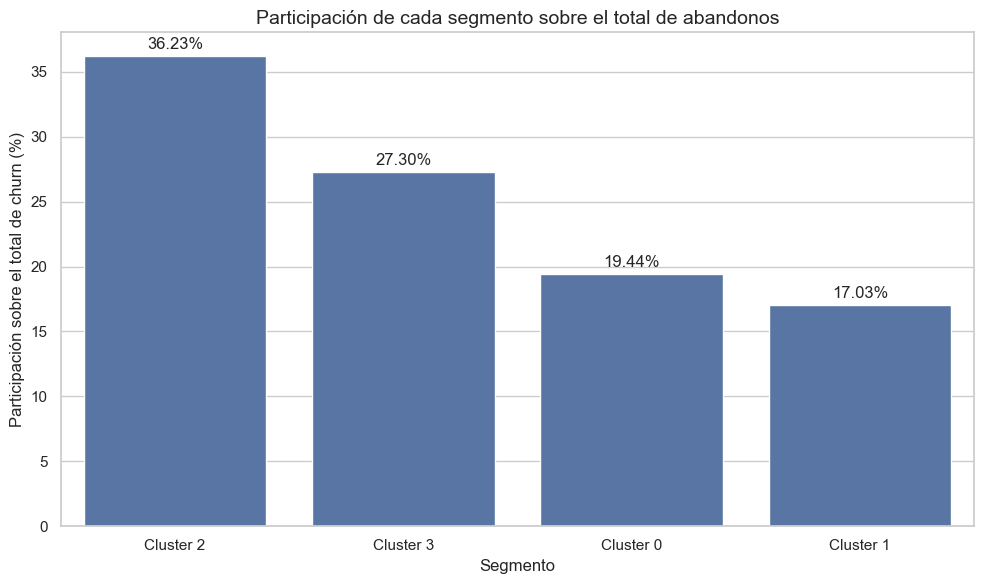

In [141]:
# Ordenamiento por contribución al total de abandonos

datos_contribucion_churn = (
    tabla_negocio_segmentos
    .sort_values(
        by="Participacion_total_churn_pct",
        ascending=False
    )
    .copy()
)

datos_contribucion_churn[
    "Segmento"
] = (
    "Cluster "
    + datos_contribucion_churn[
        "Cluster_KMeans"
    ]
    .astype(str)
)

# Gráfico

plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    data=datos_contribucion_churn,
    x="Segmento",
    y="Participacion_total_churn_pct"
)

# Etiquetas

for contenedor in ax.containers:

    etiquetas = [
        f"{valor:.2f}%"
        for valor
        in datos_contribucion_churn[
            "Participacion_total_churn_pct"
        ]
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        padding=3
    )

plt.title(
    "Participación de cada segmento "
    "sobre el total de abandonos"
)

plt.xlabel(
    "Segmento"
)

plt.ylabel(
    "Participación sobre "
    "el total de churn (%)"
)

plt.tight_layout()

plt.show()

##### 14.4 Relación entre tasa, tamaño y volumen de churn

La siguiente visualización integrará tres indicadores:

- Eje horizontal: participación del segmento dentro de la base.

- Eje vertical: tasa de churn.

- Tamaño del punto: cantidad de clientes que abandonaron.

La línea horizontal representará la tasa general de churn.

El gráfico permitirá diferenciar:

- Segmentos con elevada intensidad de abandono.

- Segmentos con mayor impacto debido a su tamaño.

- Segmentos con comportamiento inferior o cercano al promedio

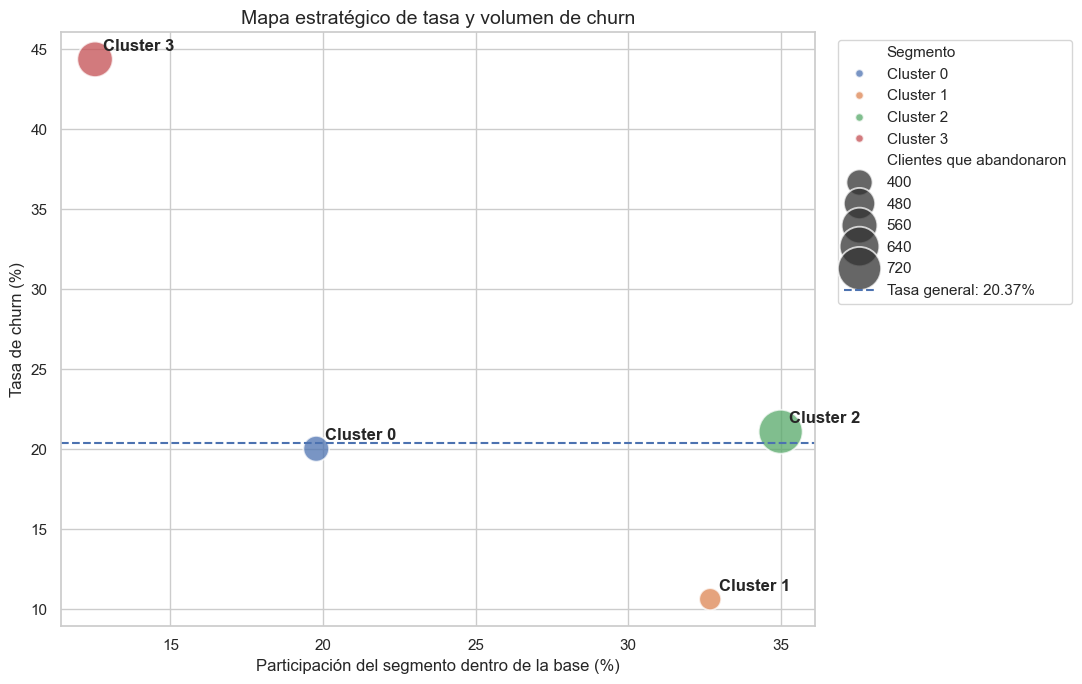

In [142]:
# Preparación de datos

datos_mapa_prioridad = (
    tabla_negocio_segmentos
    .copy()
)

# Nombre descriptivo para la leyenda
datos_mapa_prioridad[
    "Clientes que abandonaron"
] = (
    datos_mapa_prioridad[
        "Clientes_que_abandonaron"
    ]
)

datos_mapa_prioridad[
    "Segmento"
] = (
    "Cluster "
    + datos_mapa_prioridad[
        "Cluster_KMeans"
    ]
    .astype(str)
)

# Gráfico

plt.figure(
    figsize=(11, 7)
)

sns.scatterplot(
    data=datos_mapa_prioridad,
    x="Porcentaje_base",
    y="Tasa_churn_pct",
    size="Clientes que abandonaron",
    hue="Segmento",
    sizes=(250, 1000),
    alpha=0.75,
    legend="brief"
)

# Tasa general

plt.axhline(
    y=tasa_churn_general_pct,
    linestyle="--",
    label=(
        "Tasa general: "
        f"{tasa_churn_general_pct:.2f}%"
    )
)

# Etiquetas

for _, fila in (
    datos_mapa_prioridad
    .iterrows()
):

    plt.annotate(
        fila["Segmento"],
        (
            fila["Porcentaje_base"],
            fila["Tasa_churn_pct"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontweight="bold"
    )

plt.title(
    "Mapa estratégico de tasa y volumen de churn"
)

plt.xlabel(
    "Participación del segmento "
    "dentro de la base (%)"
)

plt.ylabel(
    "Tasa de churn (%)"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

##### 14.5 Recomendaciones estratégicas

Las recomendaciones se basan en los patrones identificados mediante K-Means y en el análisis posterior del churn.

Las acciones propuestas deben interpretarse como hipótesis.

Antes de una implementación general se recomienda:

- Validar la propuesta con las áreas comerciales y de atención.

- Realizar pruebas controladas.

- Medir el impacto real.

- Evaluar costos y beneficios.

- Revisar posibles efectos no deseados.

Las estrategias no deben aplicarse únicamente por la pertenencia a un cluster.

La segmentación debe complementarse con la probabilidad individual estimada mediante CatBoost y con información operativa actualizada.

In [143]:
# Recomendaciones estratégicas por segmento

estrategias_segmentos = pd.DataFrame({
    "Cluster": [
        0,
        1,
        2,
        3
    ],
    "Perfil": [
        nombres_perfiles_kmeans[0],
        nombres_perfiles_kmeans[1],
        nombres_perfiles_kmeans[2],
        nombres_perfiles_kmeans[3]
    ],
    "Prioridad": [
        "Intermedia",
        "Baja",
        "Alta por volumen",
        "Crítica por tasa"
    ],
    "Objetivo estratégico": [
        (
            "Sostener la relación "
            "y prevenir deterioro"
        ),
        (
            "Mantener la estabilidad "
            "y aumentar el uso"
        ),
        (
            "Reducir el volumen de bajas "
            "y profundizar el vínculo"
        ),
        (
            "Reducir urgentemente "
            "la intensidad del churn"
        )
    ],
    "Acciones sugeridas": [
        (
            "Programas de fidelización; "
            "revisión de la experiencia "
            "multiproducto; análisis "
            "específico del servicio "
            "en Alemania; monitoreo "
            "de satisfacción y uso."
        ),
        (
            "Comunicaciones de bajo costo; "
            "incentivos de uso; análisis "
            "de rentabilidad; activación "
            "de productos ya contratados; "
            "mantenimiento de la relación."
        ),
        (
            "Oferta de un segundo producto "
            "relevante; beneficios por "
            "profundizar la relación; "
            "seguimiento de clientes con "
            "alto saldo; campañas de "
            "retención de amplio alcance."
        ),
        (
            "Contacto proactivo y "
            "personalizado; revisión "
            "de fricciones en canales; "
            "soporte asistido; beneficios "
            "por permanencia; entrevistas "
            "o encuestas para comprender "
            "motivos de abandono."
        )
    ],
    "Fundamento": [
        (
            "Tasa cercana al promedio, "
            "saldo elevado y mayor "
            "cantidad de productos."
        ),
        (
            "Menor tasa de churn, "
            "saldo reducido y relación "
            "multiproducto."
        ),
        (
            "Mayor segmento y mayor "
            "cantidad absoluta de bajas."
        ),
        (
            "Tasa de churn superior "
            "al 44% y elevada "
            "heterogeneidad interna."
        )
    ]
})

display(
    estrategias_segmentos
)

,Cluster,Perfil,Prioridad,Objetivo estratégico,Acciones sugeridas,Fundamento
0,0,Saldo alto y multiproducto,Intermedia,Sostener la relación y prevenir deterioro,Programas de fidelización; revisión de la expe...,"Tasa cercana al promedio, saldo elevado y mayo..."
1,1,Saldo bajo y multiproducto,Baja,Mantener la estabilidad y aumentar el uso,Comunicaciones de bajo costo; incentivos de us...,"Menor tasa de churn, saldo reducido y relación..."
2,2,Saldo alto y producto único,Alta por volumen,Reducir el volumen de bajas y profundizar el v...,Oferta de un segundo producto relevante; benef...,Mayor segmento y mayor cantidad absoluta de ba...
3,3,Senior con mayor actividad,Crítica por tasa,Reducir urgentemente la intensidad del churn,Contacto proactivo y personalizado; revisión d...,Tasa de churn superior al 44% y elevada hetero...


##### 14.6 Indicadores para evaluar las estrategias

Las recomendaciones no deben evaluarse únicamente mediante la tasa general de churn.

Cada estrategia requiere indicadores específicos.

Algunas métricas no se encuentran disponibles en el dataset actual.

Su implementación requeriría integrar información operativa adicional, como:

- Uso de canales digitales.

- Frecuencia de transacciones.

- Reclamos.

- Contactos con atención al cliente.

- Encuestas de satisfacción.

- Costos de campaña.

- Rentabilidad.

- Aceptación de ofertas.

In [144]:
# Indicadores sugeridos por segmento

indicadores_seguimiento = pd.DataFrame({
    "Cluster": [
        0,
        1,
        2,
        3
    ],
    "Perfil": [
        nombres_perfiles_kmeans[0],
        nombres_perfiles_kmeans[1],
        nombres_perfiles_kmeans[2],
        nombres_perfiles_kmeans[3]
    ],
    "Indicadores principales": [
        (
            "Tasa de churn; uso de productos; "
            "satisfacción; reclamos; "
            "retención por geografía."
        ),
        (
            "Tasa de churn; nivel de actividad; "
            "uso efectivo de productos; "
            "costo de atención; rentabilidad."
        ),
        (
            "Tasa de churn; adopción de un "
            "segundo producto; permanencia "
            "del saldo; conversión de campañas; "
            "retorno de la inversión."
        ),
        (
            "Tasa de churn; tasa de contacto; "
            "conversión de retención; "
            "reclamos; resolución de consultas; "
            "satisfacción y motivos de salida."
        )
    ]
})

display(
    indicadores_seguimiento
)

,Cluster,Perfil,Indicadores principales
0,0,Saldo alto y multiproducto,Tasa de churn; uso de productos; satisfacción;...
1,1,Saldo bajo y multiproducto,Tasa de churn; nivel de actividad; uso efectiv...
2,2,Saldo alto y producto único,Tasa de churn; adopción de un segundo producto...
3,3,Senior con mayor actividad,Tasa de churn; tasa de contacto; conversión de...


##### 14.7 Integración con el modelo supervisado

K-Means y CatBoost responden preguntas diferentes.

CatBoost permite estimar:

> ¿Qué probabilidad tiene un cliente individual de abandonar el banco?

K-Means permite analizar:

> ¿A qué perfil general pertenece el cliente y qué estrategia podría resultar adecuada para ese segmento?

Una estrategia integrada podría utilizar:

1. La probabilidad individual estimada mediante CatBoost.

2. El segmento identificado mediante K-Means.

3. El valor económico potencial del cliente.

4. El historial reciente de actividad.

5. El costo esperado de la acción de retención.

Ejemplo conceptual:

Un cliente con alta probabilidad de churn perteneciente al Cluster 3 podría recibir una intervención personalizada y prioritaria.

Un cliente con riesgo similar perteneciente al Cluster 2 podría recibir una estrategia orientada a profundizar la relación mediante productos relevantes.

La pertenencia a un cluster no reemplaza la predicción individual.

Ambos enfoques aportan información complementaria.

##### 14.8 Consideraciones éticas y operativas

Las estrategias de retención deben implementarse de manera responsable.

La segmentación describe patrones grupales y no determina el comportamiento futuro de una persona.

Por lo tanto:

- No debe asumirse que todos los integrantes de un cluster presentan el mismo nivel de riesgo.

- La edad, el género o la geografía no deben utilizarse para aplicar condiciones desfavorables, excluir clientes o limitar el acceso a productos.

- Las acciones deben orientarse a mejorar la experiencia, ofrecer soporte y generar propuestas relevantes.

- Las campañas deben monitorearse para detectar resultados desiguales entre grupos.

- Las decisiones de alto impacto deben incorporar revisión humana.

- La efectividad debe validarse mediante experimentos y métricas posteriores.

El Cluster 3 presenta una edad promedio elevada.

Este resultado puede utilizarse para investigar necesidades de experiencia, accesibilidad y soporte.

No debe utilizarse para justificar un tratamiento perjudicial o discriminatorio.

Las recomendaciones propuestas representan hipótesis de retención y no relaciones causales demostradas.

##### 14.9 Validación del análisis estratégico

Se verificará que:

- Los cuatro clusters estén representados.

- La cantidad total de clientes sea igual a 10.000.

- La cantidad total de abandonos sea igual a 2.037.

- La participación de los segmentos sobre la base sume aproximadamente 100%.

- La participación sobre el total de abandonos sume aproximadamente 100%.

- Todos los segmentos posean un perfil y una prioridad.

In [145]:
# Validaciones principales

cantidad_clusters_negocio = (
    tabla_negocio_segmentos[
        "Cluster_KMeans"
    ]
    .nunique()
)

total_clientes_negocio = (
    tabla_negocio_segmentos[
        "Cantidad_clientes"
    ]
    .sum()
)

total_abandonos_negocio = (
    tabla_negocio_segmentos[
        "Clientes_que_abandonaron"
    ]
    .sum()
)

suma_porcentaje_base = (
    tabla_negocio_segmentos[
        "Porcentaje_base"
    ]
    .sum()
)

suma_participacion_churn = (
    tabla_negocio_segmentos[
        "Participacion_total_churn_pct"
    ]
    .sum()
)

perfiles_sin_asignar = (
    tabla_negocio_segmentos[
        "Perfil"
    ]
    .isna()
    .sum()
)

prioridades_sin_asignar = (
    tabla_negocio_segmentos[
        "Prioridad"
    ]
    .isna()
    .sum()
)

print(
    "Validación del análisis estratégico"
)

print(
    "-" * 45
)

print(
    f"Cantidad de clusters: "
    f"{cantidad_clusters_negocio}"
)

print(
    f"Cantidad total de clientes: "
    f"{total_clientes_negocio}"
)

print(
    f"Cantidad total de abandonos: "
    f"{total_abandonos_negocio}"
)

print(
    "Participación total "
    f"sobre la base: "
    f"{suma_porcentaje_base:.2f}%"
)

print(
    "Participación total "
    f"sobre el churn: "
    f"{suma_participacion_churn:.2f}%"
)

print(
    f"Perfiles sin asignar: "
    f"{perfiles_sin_asignar}"
)

print(
    f"Prioridades sin asignar: "
    f"{prioridades_sin_asignar}"
)

Validación del análisis estratégico
---------------------------------------------
Cantidad de clusters: 4
Cantidad total de clientes: 10000
Cantidad total de abandonos: 2037
Participación total sobre la base: 100.00%
Participación total sobre el churn: 100.00%
Perfiles sin asignar: 0
Prioridades sin asignar: 0


In [146]:
# Comprobaciones automáticas

assert (
    cantidad_clusters_negocio
    == K_FINAL
), (
    "No se encuentran representados "
    "todos los clusters."
)

assert (
    total_clientes_negocio
    == len(
        df_segmentacion
    )
), (
    "La cantidad total "
    "de clientes no coincide."
)

assert (
    total_abandonos_negocio
    == total_churn
), (
    "La cantidad total "
    "de abandonos no coincide."
)

assert np.isclose(
    suma_porcentaje_base,
    100,
    atol=0.01
), (
    "La participación sobre "
    "la base no suma 100%."
)

assert np.isclose(
    suma_participacion_churn,
    100,
    atol=0.01
), (
    "La participación sobre "
    "el churn no suma 100%."
)

assert (
    perfiles_sin_asignar
    == 0
), (
    "Existen perfiles "
    "sin asignar."
)

assert (
    prioridades_sin_asignar
    == 0
), (
    "Existen prioridades "
    "sin asignar."
)

print(
    "Todas las validaciones fueron "
    "superadas correctamente."
)

Todas las validaciones fueron superadas correctamente.


##### Interpretación estratégica de los segmentos


El análisis permitió diferenciar cuatro segmentos con características y niveles de churn distintos.

La tasa general de churn de FinanceGuard es del 20,37%.

La priorización considera tanto la intensidad del abandono como el volumen absoluto de clientes afectados.

###### Cluster 3 — Senior con mayor actividad

Prioridad:

**Crítica por tasa**

El segmento contiene 1.253 clientes y representa el 12,53% de la base.

Presenta una tasa de churn del 44,37%, equivalente a 24 puntos porcentuales por encima del promedio general.

Aunque no es el segmento más grande, concentra 556 abandonos y representa aproximadamente el 27,30% de todas las bajas.

Su tasa es más del doble de la tasa general.

El perfil presenta:

- Edad promedio de 59,02 años.
- Mayor proporción de miembros activos.
- Cantidad relativamente baja de productos.
- Mayor heterogeneidad interna.
- Mayor distancia promedio respecto del centroide.
- Mayor presencia relativa dentro del ruido identificado por DBSCAN.

La prioridad consiste en comprender las causas del abandono y diseñar acciones de soporte y retención personalizadas.

Las posibles acciones incluyen:

- Contacto proactivo.

- Revisión de fricciones en los canales.

- Mejora de accesibilidad y soporte.

- Beneficios por permanencia.

- Encuestas y análisis de motivos de salida.

La edad no debe utilizarse para aplicar condiciones desfavorables.

El objetivo debe ser identificar necesidades de experiencia y brindar un mejor servicio.

###### Cluster 2 — Saldo alto y producto único

Prioridad:

**Alta por volumen**

El segmento contiene 3.500 clientes y representa el 35,00% de la base.

Su tasa de churn es del 21,09%, levemente superior al promedio general.

Sin embargo, concentra 738 abandonos.

Esta es la mayor cantidad absoluta de bajas entre todos los segmentos y representa aproximadamente el 36,23% del churn total.

El perfil presenta:

- Saldo promedio elevado.

- Un único producto en promedio.

- Mayor tamaño dentro de la base.

- Estructura relativamente compacta.

- Alta consistencia entre K-Means y DBSCAN.

La prioridad se encuentra asociada al volumen.

Las posibles estrategias incluyen:

- Ofrecer un segundo producto relevante según las necesidades del cliente.

- Generar beneficios por profundizar la relación.

- Monitorear permanencia del saldo.

- Implementar campañas de retención de amplio alcance.

Las acciones de venta cruzada deben basarse en relevancia y necesidad.

No debe asumirse que aumentar la cantidad de productos reducirá automáticamente el churn.

###### Cluster 0 — Saldo alto y multiproducto

Prioridad:

**Intermedia**

El segmento contiene 1.978 clientes y representa el 19,78% de la base.

Su tasa de churn es del 20,02%, prácticamente igual al promedio general.

Concentra 396 abandonos y representa aproximadamente el 19,44% de las bajas.

El perfil presenta:

- Saldo elevado.

- Mayor cantidad promedio de productos.

- Fuerte presencia de clientes de Alemania.

- Nivel de actividad cercano al promedio.

La estrategia principal debe orientarse a mantener la relación y prevenir un deterioro futuro.

Las posibles acciones incluyen:

- Programas de fidelización.

- Seguimiento de uso de productos.

- Revisión de la experiencia multiproducto.

- Análisis específico de la experiencia de los clientes de Alemania.

- Monitoreo de satisfacción y reclamos.

La geografía funciona como una característica descriptiva.

No demuestra que el país cause el abandono.

###### Cluster 1 — Saldo bajo y multiproducto

Prioridad:

**Baja desde la perspectiva del churn**

El segmento contiene 3.269 clientes y representa el 32,69% de la base.

Presenta la menor tasa de churn:

10,61%.

La tasa es 9,76 puntos porcentuales inferior al promedio general.

Concentra 347 abandonos y representa aproximadamente el 17,03% del churn total.

El perfil presenta:

- Saldo prácticamente nulo.

- Cantidad relativamente elevada de productos.

- Predominio de clientes de Francia.

- Mayor margen de separación respecto de otros clusters.

La estrategia principal debe consistir en mantener la estabilidad y aumentar el uso efectivo de los productos.

Las posibles acciones incluyen:

- Comunicaciones de bajo costo.

- Incentivos de activación.

- Análisis del uso de los productos contratados.

- Evaluación de rentabilidad.

La menor tasa de churn no implica automáticamente una mayor rentabilidad.

El dataset no contiene información suficiente sobre ingresos, costos o valor económico del cliente.

###### Priorización general

Los resultados permiten diferenciar dos tipos principales de prioridad:

1. Cluster 3: prioridad por intensidad del riesgo.

Presenta la mayor tasa de churn.

2. Cluster 2: prioridad por volumen de impacto.

Concentra la mayor cantidad absoluta de abandonos.

El Cluster 0 presenta un comportamiento cercano al promedio y requiere acciones preventivas.

El Cluster 1 presenta la menor tasa de churn y requiere principalmente mantenimiento, activación y análisis de valor.

###### Integración de enfoques

K-Means proporciona una estrategia de segmentación grupal.

CatBoost proporciona una estimación individual de riesgo.

La combinación de ambos enfoques permitiría:

- Identificar qué clientes poseen mayor probabilidad de abandono.

- Comprender a qué perfil pertenecen.

- Diseñar una intervención adaptada al segmento.

- Priorizar recursos según riesgo, volumen y valor económico.

Las recomendaciones deben validarse mediante pruebas controladas.

Los patrones identificados representan asociaciones y no demuestran relaciones causales.

#### 15. Conclusiones generales y cierre del Avance 3

En este tercer avance se aplicaron técnicas de aprendizaje no supervisado para descubrir patrones ocultos dentro de la base de clientes de FinanceGuard.

El análisis se desarrolló desde el rol de analista de segmentación y exploración no supervisada.

Las técnicas implementadas fueron:

- K-Means.
- DBSCAN.
- PCA.
- t-SNE.

El objetivo principal consistió en identificar grupos de clientes con características similares, interpretar sus perfiles y analizar posteriormente su relación con la tasa de churn.

La variable `Exited` fue excluida de la construcción de los clusters, de la selección del número de segmentos y de las técnicas de reducción de dimensionalidad.

El churn se incorporó únicamente después de finalizar la segmentación, con fines descriptivos y de análisis de negocio.

##### 15.1 Resumen cuantitativo

La siguiente tabla consolida los principales resultados obtenidos durante el Avance 3.

El objetivo es presentar una visión sintética de:

- Segmentación mediante K-Means.
- Estructura de densidad identificada mediante DBSCAN.
- Reducción de dimensionalidad mediante PCA.
- Visualización no lineal mediante t-SNE.
- Dataset enriquecido.

In [147]:
# Resumen cuantitativo del Avance 3

resumen_final_avance_3 = pd.DataFrame({
    "Área": [
        "Dataset",
        "K-Means",
        "K-Means",
        "K-Means",
        "DBSCAN",
        "DBSCAN",
        "DBSCAN",
        "PCA",
        "PCA",
        "PCA",
        "t-SNE",
        "t-SNE",
        "Feature engineering"
    ],
    "Indicador": [
        "Cantidad de clientes",
        "Cantidad de clusters",
        "Coeficiente de silueta",
        "Cobertura de la base",
        "Cantidad de clusters",
        "Porcentaje de ruido",
        "Coeficiente de silueta",
        "Componentes para alcanzar 80%",
        "Componentes para superar 90%",
        "Varianza representada en 3D",
        "Dimensiones obtenidas",
        "Perplexity",
        "Variables derivadas"
    ],
    "Resultado": [
        f"{len(df):,}",
        f"{K_FINAL}",
        f"{silueta_kmeans_final:.4f}",
        "100,00%",
        f"{cantidad_clusters_dbscan}",
        (
            f"{cantidad_ruido_dbscan / len(df) * 100:.2f}%"
        ),
        f"{silueta_dbscan_final:.4f}",
        f"{componentes_80}",
        f"{componentes_90}",
        f"{varianza_3d:.2f}%",
        f"{X_tsne.shape[1]}",
        f"{PERPLEXITY_TSNE}",
        f"{len(columnas_derivadas)}"
    ]
})

display(
    resumen_final_avance_3
)

,Área,Indicador,Resultado
0,Dataset,Cantidad de clientes,"10,000"
1,K-Means,Cantidad de clusters,4
2,K-Means,Coeficiente de silueta,0.1299
3,K-Means,Cobertura de la base,"100,00%"
4,DBSCAN,Cantidad de clusters,2
5,DBSCAN,Porcentaje de ruido,7.00%
6,DBSCAN,Coeficiente de silueta,0.1283
7,PCA,Componentes para alcanzar 80%,6
8,PCA,Componentes para superar 90%,8
9,PCA,Varianza representada en 3D,44.26%


##### 15.2 Conclusiones técnicas

###### K-Means

Se evaluaron valores de `K` comprendidos entre 2 y 10 mediante:

- Método del codo.
- Coeficiente de silueta.

El mayor coeficiente de silueta global correspondió a `K = 2`.

Sin embargo, la consigna requería identificar entre 3 y 5 segmentos.

Dentro de ese intervalo, `K = 4` presentó el mejor coeficiente de silueta y un equilibrio adecuado entre:

- Reducción de la inercia.
- Separación de los grupos.
- Cantidad de segmentos.
- Interpretabilidad.
- Utilidad potencial para el negocio.

El modelo definitivo obtuvo:

- Cantidad de clusters: 4.
- Inercia: 56.180,40.
- Coeficiente de silueta: 0,1299.
- Cobertura: 100% de la base.

Los valores de silueta indican que existe superposición entre los perfiles.

Este resultado no invalida la segmentación.

Los clientes forman una estructura relativamente continua y no grupos completamente aislados.

A pesar de la superposición, los cuatro segmentos presentaron diferencias interpretables.

###### DBSCAN

DBSCAN fue configurado mediante:

- `eps = 1,698`.
- `min_samples = 26`.

El modelo identificó:

- Dos clusters.
- 9.300 clientes asignados.
- 700 observaciones clasificadas como ruido.
- 69,99% de puntos centrales.
- 23,01% de puntos de borde.
- 7,00% de ruido.
- Coeficiente de silueta de 0,1283.

Los dos clusters presentaron tamaños relativamente equilibrados.

La configuración seleccionada permitió detectar regiones de densidad y conservar un porcentaje moderado de observaciones de baja densidad.

DBSCAN mostró una estructura más general que K-Means.

Mientras K-Means generó cuatro segmentos operativos, DBSCAN identificó dos grandes regiones de densidad y un conjunto de perfiles menos frecuentes.

###### Comparación de algoritmos

K-Means fue seleccionado como método principal de segmentación porque:

- Asigna la totalidad de los clientes.
- Cumple con el objetivo de identificar entre 3 y 5 segmentos.
- Genera perfiles detallados e interpretables.
- Facilita el diseño de estrategias diferenciadas.
- Permite asignar nuevos clientes mediante `predict()`.

DBSCAN se mantuvo como técnica complementaria porque:

- Detecta regiones de densidad.
- Identifica puntos centrales y de borde.
- Permite detectar observaciones menos frecuentes.
- Reveló un grupo de ruido con una tasa de churn elevada.

Los algoritmos no son excluyentes.

Proporcionan perspectivas diferentes sobre la estructura de los clientes.

##### 15.3 Conclusiones sobre reducción de dimensionalidad

###### PCA

PCA permitió transformar las 13 características utilizadas en el análisis en un nuevo conjunto de componentes principales.

Los resultados fueron:

- PC1: 17,64% de varianza explicada.
- PC2: 13,40%.
- PC3: 13,21%.

Las primeras dos componentes representan el 31,04% de la varianza.

Las primeras tres representan el 44,26%.

Para conservar al menos el 80% de la información fueron necesarias seis componentes.

Para superar el 90% fueron necesarias ocho componentes.

La información se encuentra distribuida entre distintas dimensiones.

Por este motivo, las visualizaciones en 2D y 3D representan solo una parte de la estructura original.

Las principales componentes fueron interpretadas de la siguiente manera:

- PC1: contraste entre saldo y cantidad de productos.
- PC2: combinación de salario estimado, antigüedad y edad.
- PC3: principalmente puntaje crediticio.

PCA mostró una estructura continua y una superposición parcial entre los segmentos.

Esta superposición es consistente con el coeficiente de silueta obtenido mediante K-Means.

###### t-SNE

t-SNE fue aplicado utilizando:

- Dos dimensiones.
- `perplexity = 30`.
- Inicialización mediante PCA.
- Semilla igual a 42.

La técnica permitió observar relaciones locales y regiones visualmente más diferenciadas.

Los principales patrones fueron:

- Diferenciación entre los perfiles de saldo bajo y saldo elevado.
- Consistencia del Cluster 2.
- Mayor dispersión y heterogeneidad del Cluster 3.
- Correspondencia visual con las regiones generales identificadas mediante DBSCAN.

La mayor separación visual obtenida mediante t-SNE no demuestra por sí sola la existencia de clusters naturales.

Los ejes no poseen significado directo y las distancias globales deben interpretarse con cautela.

PCA y t-SNE aportaron perspectivas complementarias:

- PCA permitió medir la varianza e interpretar las variables.

- t-SNE permitió explorar relaciones locales y estructuras no lineales.

##### 15.4 Segmentos identificados mediante K-Means

###### Cluster 0 — Saldo alto y multiproducto

Características principales:

- 1.978 clientes.
- 19,78% de la base.
- Edad promedio: 36,88 años.
- Saldo promedio: 121.746,10.
- Productos promedio: 2,13.
- Predominio de clientes de Alemania.
- Tasa de churn: 20,02%.

El segmento presenta un comportamiento cercano a la tasa general.

Fue clasificado con prioridad intermedia.

Las estrategias recomendadas se orientan al mantenimiento de la relación, fidelización y prevención del deterioro.

###### Cluster 1 — Saldo bajo y multiproducto

Características principales:

- 3.269 clientes.
- 32,69% de la base.
- Edad promedio: 35,69 años.
- Saldo promedio: 1.002,20.
- Productos promedio: 1,82.
- Predominio de clientes de Francia.
- Tasa de churn: 10,61%.

Es el segmento con menor tasa de abandono.

Presenta una prioridad baja desde la perspectiva del churn.

Las estrategias sugeridas se orientan a mantener la estabilidad, aumentar el uso efectivo de los productos y evaluar su rentabilidad.

###### Cluster 2 — Saldo alto y producto único

Características principales:

- 3.500 clientes.
- 35,00% de la base.
- Edad promedio: 35,90 años.
- Saldo promedio: 120.929,25.
- Productos promedio: 1,00.
- Tasa de churn: 21,09%.

Es el segmento más grande.

Concentra 738 abandonos, equivalentes al 36,23% de todas las bajas.

Fue clasificado con prioridad alta por volumen.

Las estrategias se orientan a reducir la cantidad total de abandonos y profundizar el vínculo mediante propuestas relevantes.

###### Cluster 3 — Senior con mayor actividad

Características principales:

- 1.253 clientes.
- 12,53% de la base.
- Edad promedio: 59,02 años.
- Saldo promedio: 77.826,47.
- Productos promedio: 1,30.
- Mayor proporción de miembros activos.
- Tasa de churn: 44,37%.

Es el segmento con mayor intensidad de abandono.

Su tasa supera en 24 puntos porcentuales el promedio general.

Fue clasificado con prioridad crítica.

También presentó:

- Mayor heterogeneidad interna.
- Mayor distancia promedio respecto del centroide.
- Mayor proporción relativa de observaciones clasificadas como ruido.
- Distribución más dispersa mediante t-SNE.

Las estrategias propuestas se orientan al contacto proactivo, soporte personalizado e investigación de las causas del abandono.

##### 15.5 Integración con los modelos supervisados

Los Avances 1 y 2 tuvieron como objetivo predecir el abandono de clientes.

El Avance 3 tuvo un objetivo diferente:

Descubrir qué perfiles existen dentro de la base y analizar posteriormente su relación con el churn.

El mejor modelo supervisado fue CatBoost.

Sus resultados aproximados fueron:

- Accuracy: 0,88.
- Precision: 0,82.
- Recall: 0,50.
- F1-Score: 0,62.
- ROC-AUC: 0,87.
- PR-AUC: 0,73.

Las variables más importantes para CatBoost fueron:

1. `NumOfProducts`.
2. `Age`.
3. `Balance`.
4. `Geography`.
5. `EstimatedSalary`.

El análisis no supervisado identificó que varias de estas variables también fueron relevantes para diferenciar perfiles:

- Cantidad de productos.
- Edad.
- Saldo.
- Geografía.

Sin embargo, la interpretación es diferente.

En CatBoost estas variables contribuyeron a predecir churn.

En K-Means ayudaron a describir cómo se organiza la base de clientes.

Los dos enfoques pueden integrarse.

CatBoost responde:

> ¿Qué probabilidad tiene un cliente individual de abandonar?

K-Means responde:

> ¿A qué perfil pertenece el cliente y qué tipo de estrategia podría aplicarse?

Una estrategia futura podría combinar:

- Probabilidad individual de churn.
- Segmento K-Means.
- Valor económico.
- Historial reciente.
- Costo de la intervención.

La pertenencia a un cluster no reemplaza la estimación individual de riesgo.

##### 15.6 Variables derivadas y dataset enriquecido

El aprendizaje no supervisado permitió crear 17 nuevas variables.

El dataset final contiene:

- 10.000 clientes.
- 14 variables originales.
- 17 variables derivadas.
- 31 columnas en total.

Las nuevas características incluyen:

###### K-Means

- Cluster asignado.
- Perfil descriptivo.
- Distancia respecto de cada centroide.
- Distancia al centroide asignado.
- Segundo cluster más cercano.
- Margen de separación.

###### DBSCAN

- Cluster de densidad.
- Tipo de punto.
- Indicador de ruido.

###### PCA

- PC1.
- PC2.
- PC3.

###### t-SNE

- tSNE_1.
- tSNE_2.

Las variables obtenidas mediante K-Means y PCA podrían evaluarse en futuros modelos supervisados.

Su utilidad predictiva deberá comprobarse mediante validación.

No debe asumirse que una característica derivada mejorará automáticamente el rendimiento.

Las etiquetas de DBSCAN y las coordenadas de t-SNE se conservarán principalmente con fines exploratorios.

No se crearon variables basadas en:

- Tasa de churn del cluster.
- Ranking de riesgo.
- Prioridad de retención.

Esta decisión evitó incorporar información derivada de `Exited` dentro del feature engineering.

##### 15.7 Limitaciones

El análisis presenta distintas limitaciones que deben considerarse al interpretar los resultados.

###### Superposición entre segmentos

El coeficiente de silueta de K-Means fue relativamente bajo.

Esto indica que los grupos presentan cierto nivel de superposición.

Los segmentos deben interpretarse como perfiles operativos y no como categorías completamente separadas.

###### Sensibilidad de K-Means

K-Means requiere definir previamente la cantidad de clusters.

La solución depende de:

- Variables seleccionadas.
- Preprocesamiento.
- Escalamiento.
- Cantidad de clusters.
- Inicialización.

La solución con cuatro grupos fue seleccionada mediante criterios estadísticos y de interpretabilidad, pero no constituye la única segmentación posible.

###### Sensibilidad de DBSCAN

Los resultados dependen de:

- `eps`.
- `min_samples`.
- Escalamiento.
- Densidad local.

Pequeños cambios en `eps` generaron modificaciones importantes en la cantidad de clusters.

La clasificación como ruido corresponde a la configuración seleccionada y no constituye una propiedad absoluta del cliente.

###### Limitaciones de PCA

Las primeras dos componentes conservaron únicamente el 31,04% de la varianza.

Las primeras tres conservaron el 44,26%.

Por este motivo, las visualizaciones no representan toda la información original.

###### Limitaciones de t-SNE

t-SNE es sensible a:

- `perplexity`.
- Inicialización.
- Cantidad de iteraciones.
- Semilla.

Las distancias globales, formas y tamaños visuales no deben interpretarse literalmente.

La técnica se utilizó únicamente con fines exploratorios.

###### Limitaciones del dataset

El dataset no contiene información sobre:

- Transacciones.
- Uso detallado de canales.
- Reclamos.
- Satisfacción.
- Motivos de abandono.
- Rentabilidad.
- Costos de atención.
- Valor de vida del cliente.
- Historial temporal.

Estas variables podrían mejorar la comprensión de los segmentos y permitir estrategias más específicas.

###### Asociación y causalidad

Las diferencias observadas representan asociaciones.

No puede afirmarse que:

- Pertenecer a un cluster cause el churn.
- Una característica individual cause el abandono.
- Aumentar la cantidad de productos reduzca automáticamente el churn.

##### 15.8 Posibles líneas de trabajo futuro

A partir de los resultados obtenidos se proponen las siguientes líneas de análisis.

###### Evaluar las variables derivadas en CatBoost

Se podría incorporar:

- `Cluster_KMeans`.
- Distancia al centroide.
- Distancias a todos los centroides.
- Margen de separación.
- Componentes principales.

Luego debería compararse el rendimiento con el modelo original mediante la misma estrategia de validación.

###### Analizar estabilidad temporal

Si se dispusiera de información histórica, sería posible evaluar:

- Cambios de segmento.
- Permanencia dentro de los clusters.
- Evolución del churn por perfil.
- Migraciones entre grupos.

###### Incorporar nuevas fuentes de información

Podrían agregarse:

- Frecuencia de transacciones.
- Uso de canales.
- Reclamos.
- Contactos con atención.
- Satisfacción.
- Rentabilidad.
- Valor de vida del cliente.

###### Evaluar otros algoritmos

Como extensiones podrían analizarse:

- Clustering jerárquico.
- Gaussian Mixture Models.
- HDBSCAN.

Estas técnicas no fueron necesarias para cumplir el objetivo del Avance 3.

###### Validar estrategias de negocio

Las recomendaciones deberían evaluarse mediante:

- Pruebas A/B.
- Grupos de control.
- Medición de costos.
- Medición de retención incremental.
- Seguimiento de resultados por segmento.

La efectividad de una estrategia no puede confirmarse únicamente mediante el análisis histórico.

##### 15.9 Validación final del Avance 3

Antes de finalizar se verificará que:

- El dataset original conserve 10.000 clientes.
- `Exited` no forme parte de la matriz utilizada para clustering.
- K-Means haya generado cuatro clusters.
- Todos los clientes posean una etiqueta K-Means.
- DBSCAN haya generado dos clusters.
- Existan 700 observaciones clasificadas como ruido.
- PCA haya generado 13 componentes.
- t-SNE haya generado dos dimensiones.
- El dataset enriquecido conserve 10.000 clientes.
- El dataset enriquecido contenga 31 variables.
- No existan valores faltantes en las características derivadas.

In [148]:
# Variables requeridas dentro del dataset enriquecido

variables_requeridas_finales = [
    "Cluster_KMeans",
    "Perfil_KMeans",
    "Distancia_Centroide_KMeans",
    "Margen_Separacion_KMeans",
    "Cluster_DBSCAN",
    "Tipo_Punto_DBSCAN",
    "Es_Ruido_DBSCAN",
    "PC1",
    "PC2",
    "PC3",
    "tSNE_1",
    "tSNE_2"
]

# Variables faltantes

variables_finales_faltantes = [
    variable
    for variable
    in variables_requeridas_finales
    if variable
    not in df_enriquecido.columns
]

# Resumen de validación

validacion_final = pd.DataFrame({
    "Control": [
        "Clientes en dataset original",
        "Exited excluida de X_cluster",
        "Cantidad de clusters K-Means",
        "Clientes con etiqueta K-Means",
        "Cantidad de clusters DBSCAN",
        "Observaciones de ruido",
        "Componentes PCA",
        "Dimensiones t-SNE",
        "Clientes en dataset enriquecido",
        "Columnas del dataset enriquecido",
        "Faltantes en variables derivadas",
        "Variables finales faltantes"
    ],
    "Resultado": [
        len(df),
        (
            "Exited"
            not in X_cluster.columns
        ),
        (
            df_enriquecido[
                "Cluster_KMeans"
            ]
            .nunique()
        ),
        (
            df_enriquecido[
                "Cluster_KMeans"
            ]
            .notna()
            .sum()
        ),
        cantidad_clusters_dbscan,
        cantidad_ruido_dbscan,
        cantidad_componentes_pca,
        X_tsne.shape[1],
        len(
            df_enriquecido
        ),
        df_enriquecido.shape[1],
        (
            df_enriquecido[
                columnas_derivadas
            ]
            .isna()
            .sum()
            .sum()
        ),
        variables_finales_faltantes
    ]
})

display(
    validacion_final
)

,Control,Resultado
0,Clientes en dataset original,10000
1,Exited excluida de X_cluster,True
2,Cantidad de clusters K-Means,4
3,Clientes con etiqueta K-Means,10000
4,Cantidad de clusters DBSCAN,2
5,Observaciones de ruido,700
6,Componentes PCA,13
7,Dimensiones t-SNE,2
8,Clientes en dataset enriquecido,10000
9,Columnas del dataset enriquecido,31


In [149]:
# Comprobaciones automáticas finales

assert (
    len(
        df
    )
    == 10000
), (
    "El dataset original no contiene "
    "10.000 clientes."
)

assert (
    "Exited"
    not in X_cluster.columns
), (
    "Exited fue incorporada "
    "a la matriz de clustering."
)

assert (
    df_enriquecido[
        "Cluster_KMeans"
    ]
    .nunique()
    == 4
), (
    "K-Means no contiene "
    "cuatro clusters."
)

assert (
    df_enriquecido[
        "Cluster_KMeans"
    ]
    .notna()
    .sum()
    == 10000
), (
    "Existen clientes sin "
    "etiqueta K-Means."
)

assert (
    cantidad_clusters_dbscan
    == 2
), (
    "DBSCAN no contiene "
    "dos clusters."
)

assert (
    cantidad_ruido_dbscan
    == 700
), (
    "La cantidad de observaciones "
    "de ruido no coincide."
)

assert (
    cantidad_componentes_pca
    == 13
), (
    "La cantidad de componentes "
    "PCA no coincide."
)

assert (
    X_tsne.shape
    == (
        10000,
        2
    )
), (
    "Las dimensiones de t-SNE "
    "no coinciden."
)

assert (
    df_enriquecido.shape
    == (
        10000,
        31
    )
), (
    "Las dimensiones del dataset "
    "enriquecido no coinciden."
)

assert (
    df_enriquecido[
        columnas_derivadas
    ]
    .isna()
    .sum()
    .sum()
    == 0
), (
    "Existen valores faltantes "
    "en las variables derivadas."
)

assert (
    len(
        variables_finales_faltantes
    )
    == 0
), (
    "Faltan variables finales "
    "en el dataset enriquecido."
)

print(
    "Validación final completada."
)

print(
    "El Avance 3 cumple todas "
    "las comprobaciones definidas."
)

Validación final completada.
El Avance 3 cumple todas las comprobaciones definidas.


##### Conclusión final

El Avance 3 permitió complementar los modelos supervisados desarrollados previamente mediante una perspectiva de aprendizaje no supervisado.

K-Means identificó cuatro segmentos con perfiles demográficos, financieros y de comportamiento diferenciados.

El análisis posterior mostró diferencias relevantes en la tasa y el volumen de churn.

Los segmentos de mayor prioridad fueron:

- Cluster 3: prioridad crítica por intensidad del abandono.

- Cluster 2: prioridad alta por volumen total de bajas.

DBSCAN aportó una perspectiva complementaria basada en densidad.

La técnica identificó dos regiones principales y un grupo de 700 observaciones de ruido.

Los clientes clasificados como ruido presentaron una tasa de churn elevada, lo que constituye un hallazgo relevante para investigaciones futuras.

PCA permitió interpretar las principales direcciones de variabilidad.

t-SNE permitió visualizar relaciones locales y patrones no lineales.

Las variables derivadas enriquecieron el dataset con información asociada a:

- Segmentación.
- Proximidad a centroides.
- Separación entre clusters.
- Densidad.
- Componentes principales.
- Coordenadas exploratorias.

El análisis permitió responder una pregunta complementaria a la abordada mediante CatBoost.

El modelo supervisado estima qué clientes presentan mayor probabilidad de abandono.

La segmentación permite comprender qué perfiles existen y diseñar estrategias diferenciadas.

La combinación de ambos enfoques puede facilitar una gestión de retención más específica, eficiente y orientada a las características de cada cliente.

Los resultados representan asociaciones y patrones descriptivos